In [2]:
%load_ext autoreload
%autoreload 2

import os
import tempfile
import numpy as np
import pandas as pd
import scanpy as sc
import rpy2.robjects as ro
import matplotlib.pyplot as plt 
import seaborn as sns

from dotenv import load_dotenv; load_dotenv()

from utils import preprocessing
from utils import DEG
from utils.nebula_with_factors import filter_genes_for_nebula
from utils import nebula_with_factors as nbf

%matplotlib inline

PARALLEL_NEBULA_SCRIPT_PATH = os.getenv("PARALLEL_NEBULA_SCRIPT")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# DEG

## Config

In [3]:
ADATA_PATH       = f"/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad"
GROUP_NAME_SUBSETTING = None

TYPE_OF_DEG = "mito_patch_VS_patch_dead_region"


if TYPE_OF_DEG == "mito_patch_VS_patch_dead_region":

    CONTRAST_VARIABLE  = "ct_for_deg"       
    CONTRAST_BASELINE  = "Patch"
    CONTRAST_STIM      = "-Mito_cluster_patch"
    SAMPLE_VARIABLE    = "sample"
    LIBRARY_SIZE_COL   = "total_counts"
    REGION_BASELINE= "dead"
    GROUP_NAME_SUBSETTING = ["STRd D1 Striosome MSN", "STRd D2 Striosome MSN"]

    # ATTENTION: need to run PCA on the bottom before
    # ATTENTION: only POCs
        # NOT tehcnical
        # NOT sample-varibailty
    # PCs = [
    #     "PC_1",  
    #     "PC_2",  
    #     "PC_3", 
    #     "PC_5",
    #     "PC_6",
    #     "PC_7",
    # ]
    PCs = [f"PC_{i}"for i in range(1,11)]
    print("PCs used for the DE analysis:", PCs)

elif TYPE_OF_DEG == "mito_patch_VS_patch_healthy_region":

    CONTRAST_VARIABLE  = "ct_for_deg"       
    CONTRAST_BASELINE  = "Patch"
    CONTRAST_STIM      = "-Mito_cluster_patch"
    SAMPLE_VARIABLE    = "sample"
    LIBRARY_SIZE_COL   = "total_counts"
    REGION_BASELINE = "healthy"
    GROUP_NAME_SUBSETTING = ["STRd D1 Striosome MSN", "STRd D2 Striosome MSN"]

    # PCs = [
    #     "PC_1",  
    #     "PC_2",  
    #     "PC_3", 
    #     "PC_5",
    #     "PC_6",
    #     "PC_7",
    # ]
    PCs = [f"PC_{i}"for i in range(1,11)]
    print("PCs used for the DE analysis:", PCs)

elif TYPE_OF_DEG == "mito_D1D2_VS_D1D2_dead_region":

    CONTRAST_VARIABLE  = "ct_for_deg"       
    CONTRAST_BASELINE  = "eMSN_D1D2"
    CONTRAST_STIM      = "-Mito_cluster_D1D2"
    SAMPLE_VARIABLE    = "sample"
    LIBRARY_SIZE_COL   = "total_counts"
    REGION_BASELINE = "dead"

    PCs = [
        "PC_1"
    ]

elif TYPE_OF_DEG == "mito_patch_hull_VS_patch_hull_dead_region":

    CT = "Astrocyte" # Microglia, Astrocyte
    CONTRAST_VARIABLE  = "ct_for_deg"       
    CONTRAST_BASELINE  = f"{CT}_patch_hull_dead_region"
    CONTRAST_STIM      = f"{CT}_mito_patch_hull"
    SAMPLE_VARIABLE    = "sample"
    LIBRARY_SIZE_COL   = "total_counts"
    REGION_BASELINE = "dead"
    HULL_BASELINE = "radial_patch_in_death"

    #rename 
    TYPE_OF_DEG = f"{CT}_mito_patch_hull_VS_{CT}_patch_hull_dead_region"

    # No PCs
    PCs = [
    ]

COVARIATES = ["age_at_death", "pct_intronic", "Sorted", *PCs] 
    # no Sex, as they are all males

WITH_MITO_COV = False
MITO_COL = "pct_counts_mt"
mito_str = ""
if WITH_MITO_COV:
    COVARIATES.append(MITO_COL)
    mito_str = "_with_mito_cov"


SAVE_FOLDER = f"/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/{TYPE_OF_DEG}{mito_str}"
os.makedirs(SAVE_FOLDER, exist_ok=True)

saving_folder_pca = f"/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/pca_results_{CONTRAST_BASELINE}"

save_csv_path = f"{SAVE_FOLDER}/nebula_results.csv"



PCs used for the DE analysis: ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8', 'PC_9', 'PC_10']


## Load adata

In [4]:
adata = sc.read_h5ad(ADATA_PATH, backed="r")

## Select constrast cells

In [5]:
# chnage name
adata.obs["condition"] = adata.obs["condition"].replace({"diseased ": "diseased"})
print(adata.obs["condition"].unique())
print(adata.obs["region"].unique())

['diseased', 'healthy']
Categories (2, object): ['diseased', 'healthy']
[NaN, 'healthy', 'dead']
Categories (2, object): ['dead', 'healthy']


In [6]:
# ahve single PAtch label
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].replace({"Patch_D1": "Patch", "Patch_D2": "Patch"})

mask_diseased = adata.obs["condition"] == "diseased" # take inyl dieased samples
mask_spatial  = adata.obs["has_spatial"] # take nyl cells wiht spatial

if GROUP_NAME_SUBSETTING is not None: # Subset to onyl speifi  cell tye (why? manual cluster deifniton coudl have got some mstrix cells too)
    mask_group = adata.obs["Group_name"].isin(GROUP_NAME_SUBSETTING)
    print(f"Subsetting to groups: {GROUP_NAME_SUBSETTING}, n_cells: {mask_group.sum()}")
    mask_diseased = mask_diseased & mask_group

if "hull" in TYPE_OF_DEG:
    print("Using hull-based region definitions")

    # baseline: ct, in region, in hull
    adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(str) # ensure string type for comparison
    adata.obs.loc[(adata.obs["ct_for_deg"] == CT) & (adata.obs["region"] == REGION_BASELINE) & (adata.obs["mito_radial_neighborhood"] == HULL_BASELINE), "ct_for_deg"] = CONTRAST_BASELINE
    adata.obs.loc[(adata.obs["ct_for_deg"] == CT) & (adata.obs["region"] == "dead") & (adata.obs["mito_radial_neighborhood"] == "radial_high_mito_patch"), "ct_for_deg"] = CONTRAST_STIM

# each group gets its own region filter
mask_baseline = (adata.obs["ct_for_deg"] == CONTRAST_BASELINE) & (adata.obs["region"] == REGION_BASELINE)
mask_stim     = (adata.obs["ct_for_deg"] == CONTRAST_STIM)     & (adata.obs["region"] == "dead") # always dead region (dorsal)


print("\nmask_baseline:", mask_baseline.sum())
print("mask_stim:    ", mask_stim.sum())
print("mask_diseased:", mask_diseased.sum())
print("mask_spatial: ", mask_spatial.sum())

mask = mask_diseased & (mask_baseline | mask_stim) & mask_spatial
adata = adata[mask].to_memory().copy()

print(adata.obs["sample"].unique())


# Use gene symbols as index
if "gene_symbol" in adata.var.columns:
    adata.var.index = adata.var["gene_symbol"].astype(str)
    adata.var_names_make_unique()

adata.X = adata.layers["counts"].copy()
print(adata)

Subsetting to groups: ['STRd D1 Striosome MSN', 'STRd D2 Striosome MSN'], n_cells: 26763

mask_baseline: 1912
mask_stim:     445
mask_diseased: 14908
mask_spatial:  462822


/tmp/ipykernel_53216/3398713284.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].replace({"Patch_D1": "Patch", "Patch_D2": "Patch"})


['sample_01', 'sample_02', 'sample_03', 'sample_04', 'sample_06', 'sample_08', 'sample_09', 'sample_10']
Categories (8, object): ['sample_01', 'sample_02', 'sample_03', 'sample_04', 'sample_06', 'sample_08', 'sample_09', 'sample_10']
AnnData object with n_obs × n_vars = 2174 × 37588
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'original_barcode', 'do

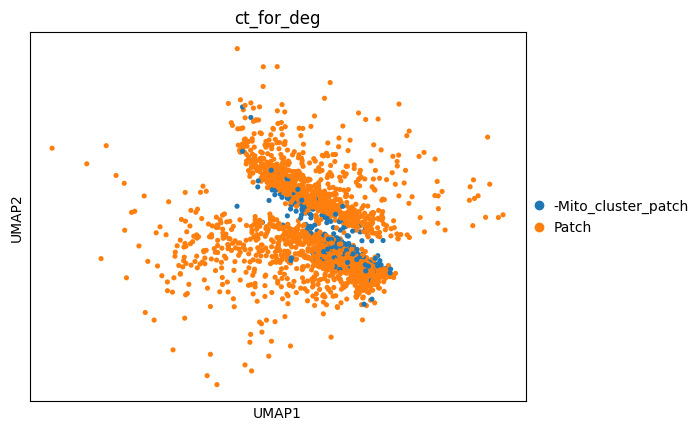

... storing 'sample_x_puck' as categorical


Sample: sample_01_puck2


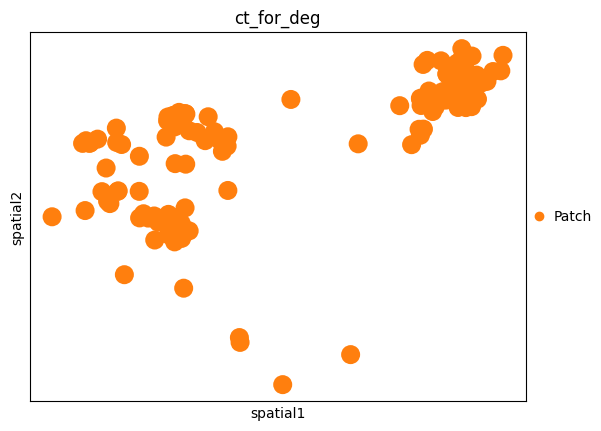

... storing 'sample_x_puck' as categorical


Sample: sample_01_puck1


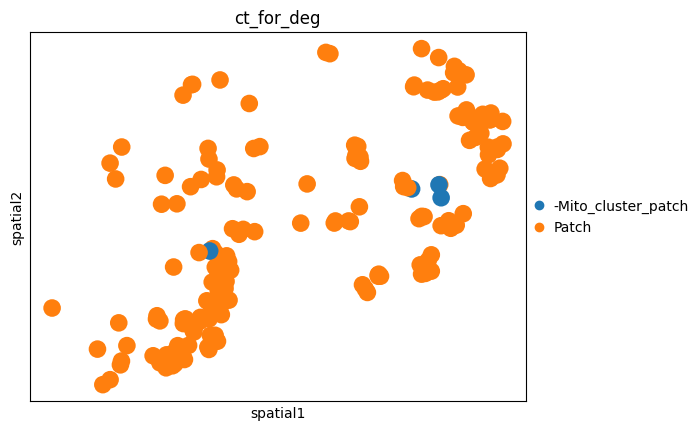

Sample: sample_02_puck1


... storing 'sample_x_puck' as categorical


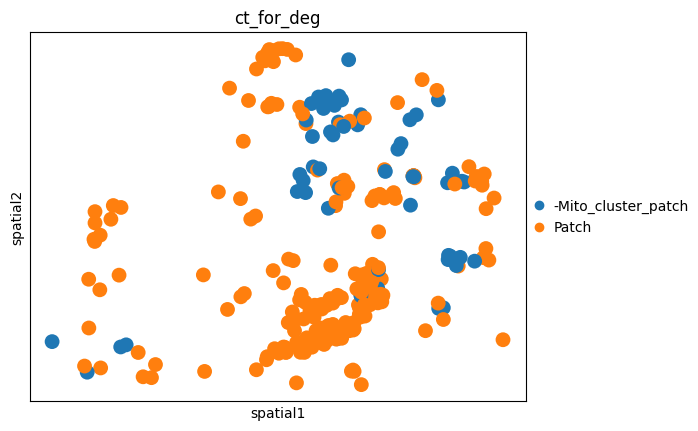

Sample: sample_02_puck2


... storing 'sample_x_puck' as categorical


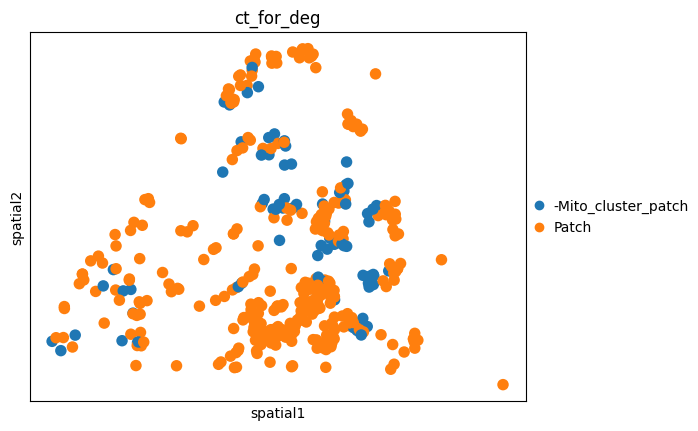

In [7]:
sc.pl.embedding(adata, basis="umap", color=CONTRAST_VARIABLE)


adata.obs["sample_x_puck"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
for sample in adata.obs["sample_x_puck"].unique()[:4]:
    print(f"Sample: {sample}")
    adata_sample = adata[adata.obs["sample_x_puck"] == sample].copy()
    sc.pl.embedding(adata_sample, basis="spatial", color=CONTRAST_VARIABLE)   

    #break 

... storing 'sample_x_puck' as categorical


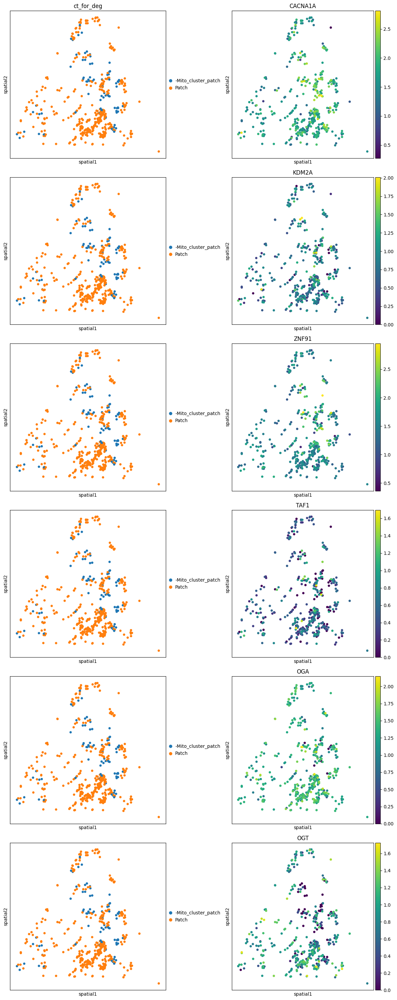

In [10]:
adata_sample = adata[adata.obs["sample_x_puck"] == "sample_02_puck2"].copy()

sc.pp.normalize_total(adata_sample, target_sum=1e4)
sc.pp.log1p(adata_sample)
adata_sample.layers["log1p_norm"] = adata_sample.X.copy()

import matplotlib.pyplot as plt

genes = [
    "CACNA1A", "KDM2A",
    "ZNF91", "TAF1", "OGA", "OGT",
    # "POLR2A", "ZSWIM6", "ZNF772", "SMG7", "ZNF93", "MOV10L1", "GLI3", "MEG3", "GNG7", "MT-ND6", "PNISR", "NONO", "MEG8",
    # "BAX", "CASP1", "CASP2", "CASP6", "CASP4", "CASP3", "ARRB1", "CALHM1", "BBC3", "HRK", "CDKN2A", "CDKN1A", "GATA4", "GLB1"
]

n = len(genes)
fig, axes = plt.subplots(n, 2, figsize=(12, 5 * n))
S=100
for i, gene in enumerate(genes):
    sc.pl.embedding(adata_sample, basis="spatial", color=CONTRAST_VARIABLE,size=S,
                    ax=axes[i, 0], show=False, title=CONTRAST_VARIABLE if i == 0 else "")
    sc.pl.embedding(adata_sample, basis="spatial", layer="log1p_norm", color=gene,size=S,
                    ax=axes[i, 1], show=False)
    
    #break

plt.tight_layout()
plt.show()


In [11]:
print(adata.obs[SAMPLE_VARIABLE].value_counts())
print(adata.obs[CONTRAST_VARIABLE].value_counts())
print(adata.obs["condition"].value_counts())

pd.crosstab(adata.obs[SAMPLE_VARIABLE], adata.obs[CONTRAST_VARIABLE])

sample
sample_02    704
sample_08    470
sample_01    347
sample_03    308
sample_09    125
sample_06     81
sample_04     72
sample_10     67
Name: count, dtype: int64
ct_for_deg
Patch                  1912
-Mito_cluster_patch     262
Name: count, dtype: int64
condition
diseased    2174
Name: count, dtype: int64


ct_for_deg,-Mito_cluster_patch,Patch
sample,,
sample_01,4,343
sample_02,136,568
sample_03,46,262
sample_04,1,71
sample_06,17,64
sample_08,33,437
sample_09,3,122
sample_10,22,45


In [12]:

# rmeove sample 9
adata = adata[~(adata.obs["sample"].isin(["sample_09", "sample_01"]))].copy()

## Add PCs

In [13]:
# Unpack what you need for projection

df_stats    = pd.read_csv(f"{saving_folder_pca}/healthy_stats.csv", index_col=0)  # results_healthy["df_stats"]
df_loadings = pd.read_csv(f"{saving_folder_pca}/gene_loadings.csv", index_col=0) #results_healthy["df_loadings"]

In [14]:
# ── 2. PROJECT onto diseased data ──────────────────────────────────────────────

shared_genes = adata.var_names.intersection(df_loadings.index)
print(f"Loadings genes: {len(df_loadings)}")
print(f"Diseased adata genes: {len(adata.var_names)}")
print(f"Shared genes: {len(shared_genes)}")
assert len(shared_genes) > 0, "No shared genes — check gene ID format (symbols vs ENSEMBL)"

df_loadings_shared = df_loadings.loc[shared_genes]
df_stats_shared    = df_stats.loc[shared_genes]
adata_shared       = adata[:, shared_genes].copy()

# Clear log1p key so calculate_pca doesn't think data is already normalized
if "log1p" in adata_shared.uns:
    del adata_shared.uns["log1p"]

results_diseased = nbf.calculate_pca(
    adata                = adata_shared,
    calculate_or_project = "project",
    saving_folder        = saving_folder_pca,
    df_stats             = df_stats_shared,
    df_loadings          = df_loadings_shared
)

# ── 3. ADD projected PCs back into adata ──────────────────────────────────────
df_pcs = results_diseased["df_pcs"]
pc_cols = [c for c in df_pcs.columns if c.startswith("PC_")]
df_pcs_indexed = df_pcs.set_index("barcode")
adata.obs[pc_cols] = df_pcs_indexed.reindex(adata.obs_names)


Loadings genes: 3000
Diseased adata genes: 37588
Shared genes: 2983
Normalising
Scaling
PCA on Diseased
Done.


... storing 'sample_x_puck' as categorical


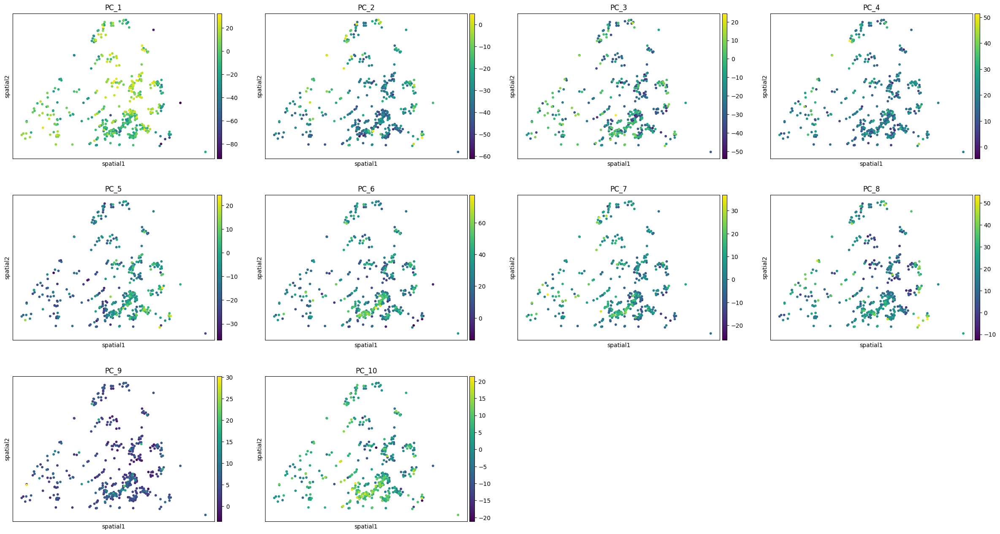

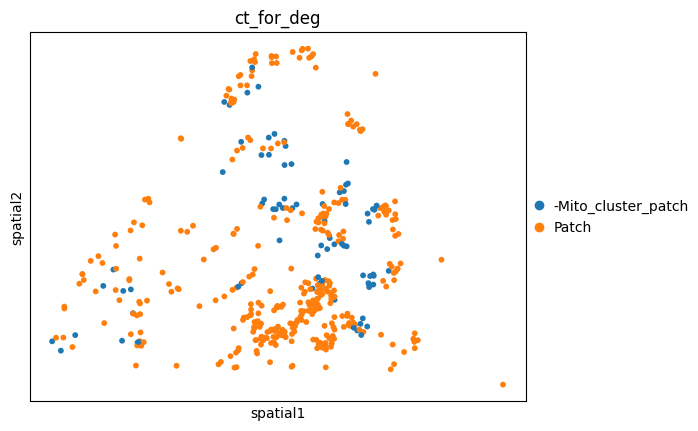

In [15]:
adata.obs["sample_x_puck"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
for sample in adata.obs["sample_x_puck"].unique():
    adata_sample = adata[adata.obs["sample_x_puck"] == "sample_02_puck2"].copy()
    sc.pl.embedding(adata_sample, basis="spatial", color=[f"PC_{i}" for i in range(1, 11)], size=70)   
    sc.pl.embedding(adata_sample, basis="spatial", color=["ct_for_deg"], size=70)   

    break 

# Umap

In [ ]:
# import scanpy as sc
# import harmonypy
# import numpy as np
# import pandas as pd

# # --- 0. Copy so we don't destroy the original ---
# adata_t = adata.copy()

# # --- 1. Make sure .X is log-normalized ---
# adata_t.X = adata_t.layers['log1p_norm'].copy()

# # --- 2. HVGs from raw counts, then strip MT genes ---
# sc.pp.highly_variable_genes(
#     adata_t, n_top_genes=3000, flavor='seurat_v3',
#     layer='counts', batch_key='sample'
# )
# adata_t.var.loc[adata_t.var['mt'], 'highly_variable'] = False
# print(f"HVGs after MT removal: {adata_t.var['highly_variable'].sum()}")

# # --- 3. Regress out pct_counts_mt + total_counts ---
# print("Regressing out pct_counts_mt and total_counts...")
# sc.pp.regress_out(adata_t, ['pct_counts_mt', 'total_counts'])

# # --- 4. Scale ---
# sc.pp.scale(adata_t, max_value=10)

# # --- 5. PCA ---
# sc.tl.pca(adata_t, n_comps=50, use_highly_variable=True)

# # --- 6. Harmony (safe orientation handling) ---
# print("Running Harmony batch correction...")
# ho = harmonypy.run_harmony(
#     adata_t.obsm['X_pca'].copy(),   # <-- add .copy()
#     adata_t.obs,
#     vars_use='sample',
#     max_iter_harmony=30
# )
# Z = ho.Z_corr
# print(f"Z_corr shape: {Z.shape}, n_obs: {adata_t.n_obs}")

# if Z.shape[0] == adata_t.n_obs:
#     adata_t.obsm['X_pca_harmony_noMT'] = Z
# elif Z.shape[1] == adata_t.n_obs:
#     adata_t.obsm['X_pca_harmony_noMT'] = Z.T
# else:
#     raise ValueError(f"Neither dim of Z_corr matches n_obs={adata_t.n_obs}: {Z.shape}")

# # --- 7. Neighbors, UMAP, Leiden ---
# sc.pp.neighbors(adata_t, n_neighbors=15, n_pcs=30,
#                 use_rep='X_pca_harmony_noMT')
# sc.tl.umap(adata_t)
# sc.tl.leiden(adata_t, resolution=0.5, key_added='leiden_noMT')

# # --- 8. Diagnostics ---
# print("\n=== high-mito cells vs new clusters ===")
# print(pd.crosstab(adata_t.obs['is_mito_cluster_patch'],
#                   adata_t.obs['leiden_noMT']))

# print("\n=== old curated labels vs new clusters ===")
# print(pd.crosstab(adata_t.obs['ct_for_deg'],
#                   adata_t.obs['leiden_noMT']))

# sc.pl.umap(adata_t,
#            color=['leiden_noMT', 'is_mito_cluster_patch',
#                   'ct_for_deg', 'pct_counts_mt', 'n_genes_by_counts'])

INFO: Seed set to 42
2026-10-28 14:46:34 | [INFO] Seed set to 42


Running HVG...
HVG computed with batch_key='sample'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-28 14:46:37,377 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-28 14:46:37 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-28 14:46:37,379 - harmonypy - INFO -   Parameters:
2026-10-28 14:46:37 | [INFO]   Parameters:
2026-10-28 14:46:37,379 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-28 14:46:37 | [INFO]     max_iter_harmony: 30
2026-10-28 14:46:37,380 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-28 14:46:37 | [INFO]     max_iter_kmeans: 20
2026-10-28 14:46:37,381 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-28 14:46:37 | [INFO]     epsilon_cluster: 1e-05
2026-10-28 14:46:37,382 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-28 14:46:37 | [INFO]     epsilon_harmony: 0.0001
2026-10-28 14:46:37,383 - harmonypy - INFO -     nclust: 57
2026-10-28 14:46:37 | [INFO]     nclust: 57
2026-10-28 14:46:37,384 - harmonypy - INFO -     block_size: 0.05
2026-10-28 14:46:37 | [INFO]     block_size: 0.05
2026-10-28 14:46:37,385 - harmon

Running Harmony batch correction...


2026-10-28 14:46:38,096 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 14:46:38 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-10-28 14:46:38,214 - harmonypy - INFO - KMeans initialization complete.
2026-10-28 14:46:38 | [INFO] KMeans initialization complete.
2026-10-28 14:46:38,623 - harmonypy - INFO - Iteration 1 of 30
2026-10-28 14:46:38 | [INFO] Iteration 1 of 30
2026-10-28 14:46:39,366 - harmonypy - INFO - Iteration 2 of 30
2026-10-28 14:46:39 | [INFO] Iteration 2 of 30
2026-10-28 14:46:39,667 - harmonypy - INFO - Iteration 3 of 30
2026-10-28 14:46:39 | [INFO] Iteration 3 of 30
2026-10-28 14:46:39,984 - harmonypy - INFO - Iteration 4 of 30
2026-10-28 14:46:39 | [INFO] Iteration 4 of 30
2026-10-28 14:46:40,175 - harmonypy - INFO - Iteration 5 of 30
2026-10-28 14:46:40 | [INFO] Iteration 5 of 30
2026-10-28 14:46:40,370 - harmonypy - INFO - Iteration 6 of 30
2026-10-28 14:46:40 | [INFO] Iteration 6 of 30
2026-10-28 14:46:40,498 - 

Z_corr shape: (1702, 50), n_obs: 1702
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...


... storing 'sample_x_puck' as categorical


Computing Leiden clusters...


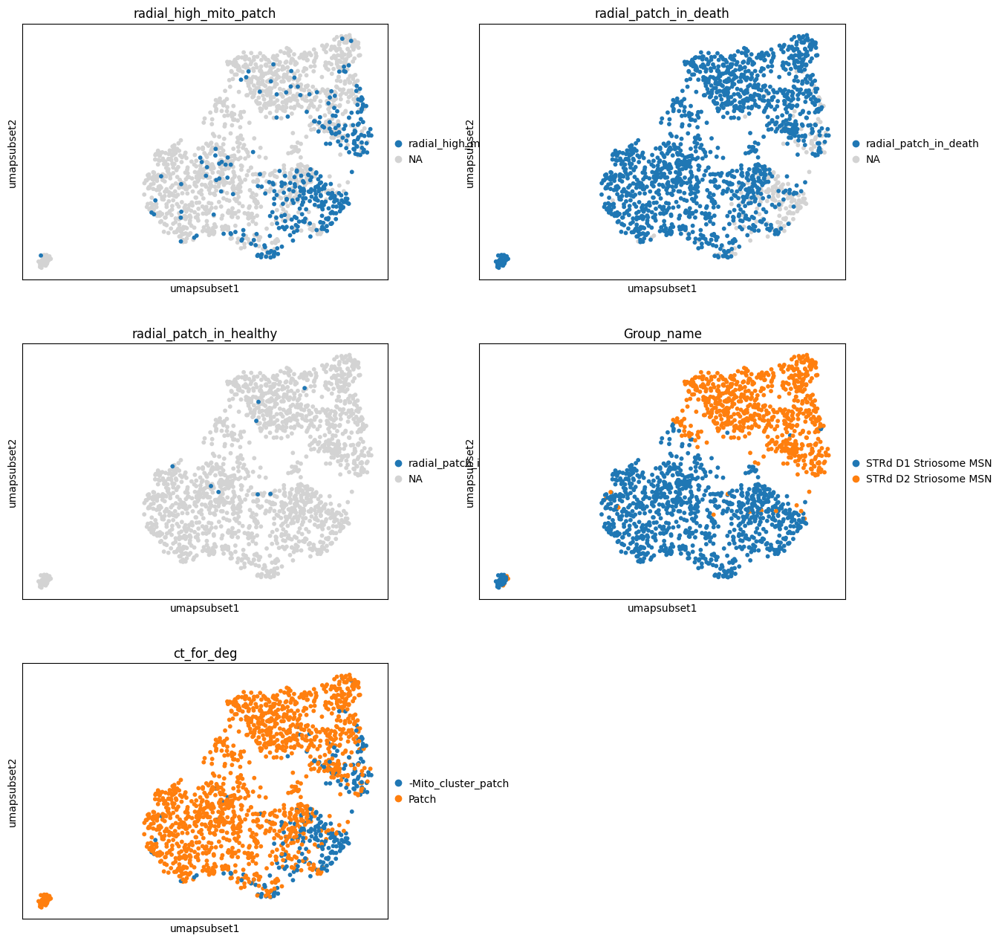

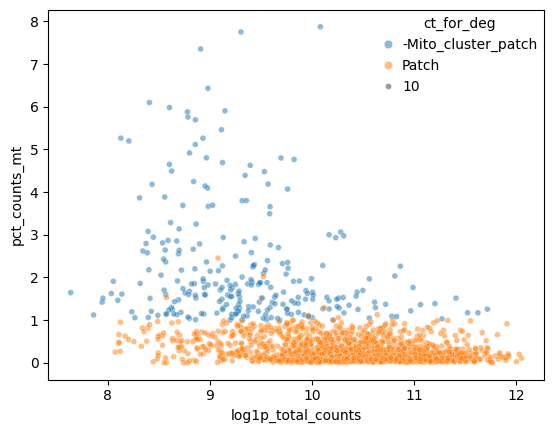

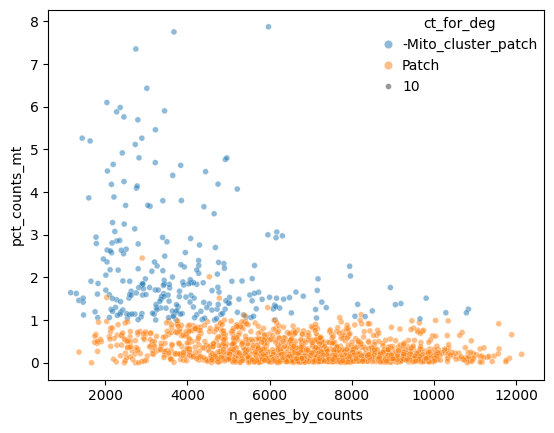

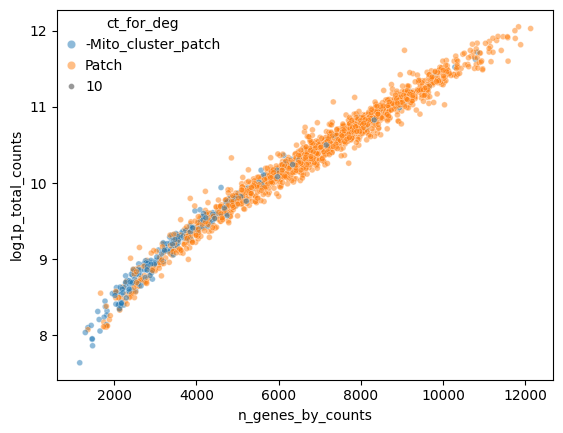

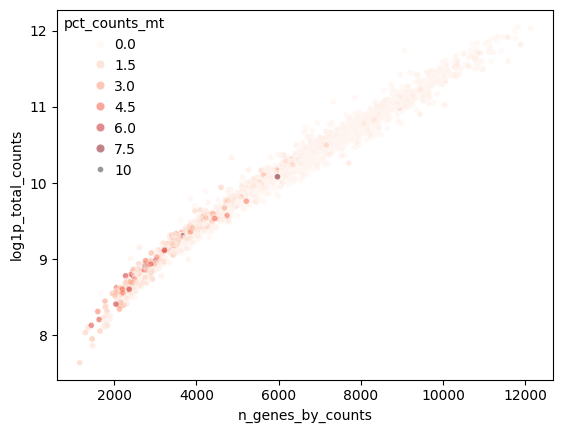

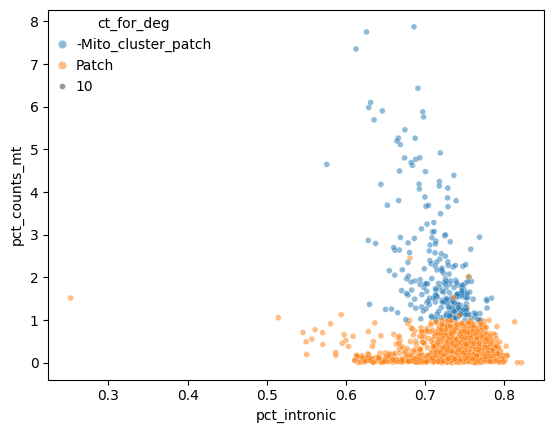

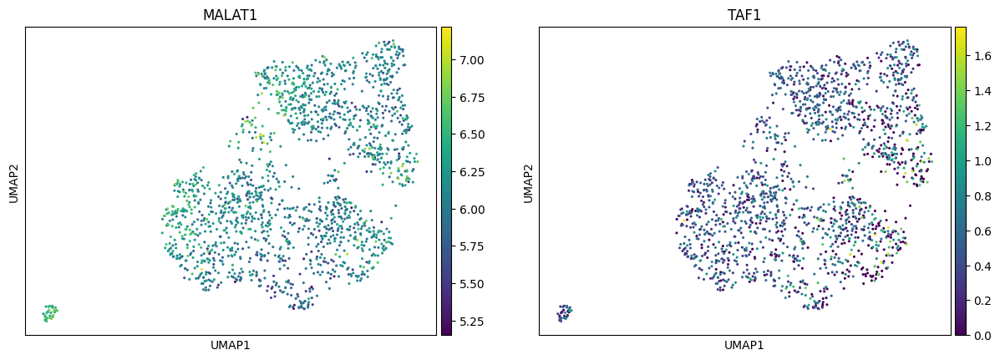

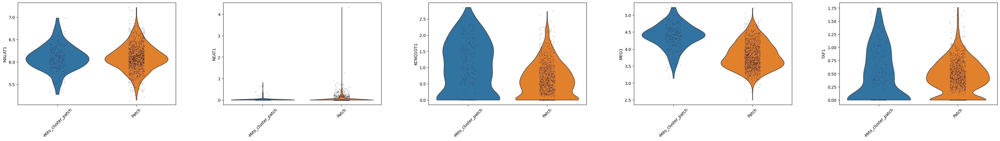

In [16]:
NAME="subset"
from utils import label_mapping_utils as lmu

leiden_cluster_names = lmu.preprocess_common_pipeline(adata, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)
sc.pl.embedding(adata, basis=F"umap{NAME}", color=["radial_high_mito_patch", "radial_patch_in_death", "radial_patch_in_healthy", "Group_name", "ct_for_deg"], ncols=2)


sns.scatterplot(adata.obs, x="log1p_total_counts", y="pct_counts_mt",hue="ct_for_deg", size=10, alpha=0.5); plt.show()
sns.scatterplot(adata.obs, x="n_genes_by_counts", y="pct_counts_mt",hue="ct_for_deg", size=10, alpha=0.5); plt.show()
sns.scatterplot(adata.obs, x="n_genes_by_counts", y="log1p_total_counts",hue="ct_for_deg", size=10, alpha=0.5); plt.show()
sns.scatterplot(adata.obs, x="n_genes_by_counts", y="log1p_total_counts",hue="pct_counts_mt", size=10, alpha=0.5, palette="Reds"); plt.show()
sns.scatterplot(adata.obs, x="pct_intronic", y="pct_counts_mt",hue="ct_for_deg", size=10, alpha=0.5); plt.show()


sc.pl.embedding(adata, basis="umap", color=["MALAT1", "TAF1"],layer="log1p_norm", size=20, show=True); plt.show()
sc.pl.violin(
    adata, 
    keys=["MALAT1", "NEAT1", "KCNQ1OT1", "MEG3", "TAF1"],
    groupby="ct_for_deg",
    layer="log1p_norm",
    rotation=45
)

In [ ]:
# # Build a composite score
# adata.obs['nuclear_compromise'] = (
#     adata.obs['pct_counts_mt'].rank(pct=True)
#     - adata.obs['n_genes_by_counts'].rank(pct=True)
#     # add: - rank of hnRNP module score, - rank of nuclear ncRNA score
# )

# # Nuclear-retained ncRNA score (should be LOWER in compromised)
# nuclear_ncrna = ['MALAT1', 'NEAT1', 'KCNQ1OT1', 'MEG3', 'TALAM1']
# nuclear_ncrna = [g for g in nuclear_ncrna if g in adata.var_names]
# sc.tl.score_genes(adata, nuclear_ncrna, score_name='nuclear_ncrna_score')

# # Splicing/hnRNP module (should be LOWER in compromised)
# splicing_module = ['HNRNPA2B1', 'HNRNPC', 'SRSF5', 'NCBP1', 'HNRNPA1',
#                    'HNRNPU', 'SRSF1', 'SRSF7', 'SF3B1']
# splicing_module = [g for g in splicing_module if g in adata.var_names]
# sc.tl.score_genes(adata, splicing_module, score_name='splicing_score')

# # Composite (each component on same scale via percentile rank)
# adata.obs['nuclear_compromise'] = (
#     adata.obs['pct_counts_mt'].rank(pct=True)
#     - adata.obs['n_genes_by_counts'].rank(pct=True)
#     - adata.obs['nuclear_ncrna_score'].rank(pct=True)
#     - adata.obs['splicing_score'].rank(pct=True)
# ) / 4

# sns.histplot(adata.obs, x="nuclear_compromise", hue="ct_for_deg", bins=50)

In [ ]:
# ogtcycle = [
#     'OGT',     # adds O-GlcNAc
#     'OGA',     # removes O-GlcNAc (a.k.a. MGEA5)
#     'GFPT1', 'GFPT2',  # hexosamine biosynthesis pathway entry
#     'GNPNAT1', 'PGM3', 'UAP1',  # HBP enzymes producing UDP-GlcNAc
# ]

# ogtcycle = [g for g in ogtcycle if g in adata.var_names]
# lmu.aucell(adata, ogtcycle, "OGlcNAc_module")


# sns.violinplot(data=adata.obs, x="OGlcNAc_module", hue="ct_for_deg", split=True); plt.show()

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# # --- 1. Control gene sets ---
# housekeeping = ['ACTB', 'GAPDH', 'TUBB', 'PPIA', 'RPL13A', 'B2M', 'HPRT1',
#                 'YWHAZ', 'SDHA', 'TBP', 'UBC', 'GUSB']
# housekeeping = [g for g in housekeeping if g in adata.var_names]

# # Size-matched random set (match OGlcNAc module size for fair comparison)
# n_ogt = 7  # size of your ogtcycle list
# np.random.seed(0)
# random_set = np.random.choice(adata.var_names, size=n_ogt, replace=False).tolist()

# # Multiple random sets for a null distribution
# random_modules = {}
# for i in range(50):
#     np.random.seed(i)
#     random_modules[f'random_{i}'] = np.random.choice(
#         adata.var_names, size=n_ogt, replace=False
#     ).tolist()

# # --- 2. Score all of them with AUCell ---
# lmu.aucell(adata, housekeeping, "housekeeping_module")
# lmu.aucell(adata, random_set, "random_module")
# for name, gs in random_modules.items():
#     lmu.aucell(adata, gs, name)

# # --- 3. Side-by-side comparison plot ---
# modules_to_plot = ['OGlcNAc_module', 'housekeeping_module', 'random_module']
# fig, axes = plt.subplots(1, len(modules_to_plot), figsize=(15, 5), sharey=False)
# for ax, mod in zip(axes, modules_to_plot):
#     sns.violinplot(data=adata.obs, x=mod, hue='ct_for_deg',
#                    split=True, ax=ax, inner='quartile')
#     ax.set_title(mod)
# plt.tight_layout()
# plt.show()

# # --- 4. Null distribution view: overlay all random modules ---
# random_cols = list(random_modules.keys())
# df_long = adata.obs[random_cols + ['ct_for_deg']].melt(
#     id_vars='ct_for_deg', var_name='random_set', value_name='score'
# )

# fig, ax = plt.subplots(figsize=(10, 5))
# sns.violinplot(data=df_long, x='random_set', y='score', hue='ct_for_deg',
#                split=True, ax=ax, inner='quartile')
# # Overlay OGlcNAc as a reference
# ax.axhline(adata.obs.loc[adata.obs['ct_for_deg'] == '-Mito_cluster_patch',
#                           'OGlcNAc_module'].median(),
#            color='blue', linestyle='--', label='OGlcNAc median (high-mito)')
# ax.axhline(adata.obs.loc[adata.obs['ct_for_deg'] == 'Patch',
#                           'OGlcNAc_module'].median(),
#            color='orange', linestyle='--', label='OGlcNAc median (healthy patch)')
# ax.legend()
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

# # --- 5. Quantitative effect size: how shifted is each module? ---
# print("Module shift (healthy patch median - high-mito median):")
# for mod in modules_to_plot + random_cols:
#     healthy = adata.obs.loc[adata.obs['ct_for_deg'] == 'Patch', mod].median()
#     highmt  = adata.obs.loc[adata.obs['ct_for_deg'] == '-Mito_cluster_patch', mod].median()
#     print(f"  {mod:30s}: {healthy - highmt:+.4f}")

#     #OGlcNAc is ~4× larger than the largest random shift and ~10× larger than the median random shift
#     #ousekeeping genes — which are similarly or more abundant than the OGlcNAc enzymes — are detected equivalently in both populations. So the OGlcNAc signal is targeting a specific functional pathway, not a complexity floor.

In [ ]:
# # Quick correlation check

# #within the patch population, does OGlcNAc score correlate continuously with your nuclear_compromise score? If yes, you have a coherent molecular axis, not just a binary group difference.
# import scipy.stats as stats
# patch_mask = adata.obs['ct_for_deg'].isin(['Patch', '-Mito_cluster_patch'])
# df = adata.obs.loc[patch_mask, ['nuclear_compromise', 'OGlcNAc_module']]
# r, p = stats.spearmanr(df['nuclear_compromise'], df['OGlcNAc_module'])
# print(f"Spearman r = {r:.3f}, p = {p:.3e}")
# sns.regplot(data=df, x='nuclear_compromise', y='OGlcNAc_module',
#             scatter_kws={'alpha': 0.3, 's': 10})

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# # =========================================================
# # 1. Per-donor consistency of OGlcNAc module
# # =========================================================
# # Are all "compromised" donors shifted down, all healthy donors not?

# fig, ax = plt.subplots(figsize=(12, 5))
# sns.violinplot(
#     data=adata.obs,
#     x='donor_id', y='OGlcNAc_module',
#     hue='ct_for_deg', split=True, inner='quartile', ax=ax
# )
# plt.xticks(rotation=45)
# plt.title('OGlcNAc module by donor, split by compromised vs healthy patch')
# plt.tight_layout()
# plt.show()

# # Numeric: per-donor median shift (healthy - compromised)
# print("\nPer-donor median shift (healthy patch - high-mito patch):")
# print("Positive = compromised cells lower (expected direction)\n")
# shifts = (
#     adata.obs.groupby(['donor_id', 'ct_for_deg'])['OGlcNAc_module']
#     .median()
#     .unstack('ct_for_deg')
# )
# shifts['shift'] = shifts['Patch'] - shifts['-Mito_cluster_patch']
# # Add condition info per donor
# shifts['condition'] = adata.obs.groupby('donor_id')['condition'].first()
# print(shifts)

# # =========================================================
# # 2. OGT / OGA ratio
# # =========================================================
# # Get gene names that actually exist in your data
# oga_name = 'OGA' if 'OGA' in adata.var_names else 'MGEA5'  # MGEA5 is OGA's old name

# # Pull expression as dense arrays
# def get_expr(adata, gene):
#     x = adata[:, gene].X
#     return np.asarray(x.todense()).flatten() if hasattr(x, 'todense') else x.flatten()

# adata.obs['OGT_expr'] = get_expr(adata, 'OGT')
# adata.obs['OGA_expr'] = get_expr(adata, oga_name)
# adata.obs['OGT_OGA_ratio'] = np.log1p(adata.obs['OGT_expr']) - np.log1p(adata.obs['OGA_expr'])

# # Plot OGT, OGA, and ratio side by side
# fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# for ax, col, title in zip(
#     axes,
#     ['OGT_expr', 'OGA_expr', 'OGT_OGA_ratio'],
#     ['OGT expression', f'{oga_name} (OGA) expression', 'log(OGT) - log(OGA)']
# ):
#     sns.violinplot(data=adata.obs, x='ct_for_deg', y=col,
#                    inner='quartile', ax=ax)
#     ax.set_title(title)
#     ax.set_xlabel('')
# plt.tight_layout()
# plt.show()

# # Numeric summary
# print("\n=== OGT vs OGA in compromised vs healthy patch ===")
# summary = adata.obs.groupby('ct_for_deg')[
#     ['OGT_expr', 'OGA_expr', 'OGT_OGA_ratio']
# ].median()
# print(summary)

# # What you want to see:
# # - OGT: lower in -Mito_cluster_patch
# # - OGA: stable or HIGHER in -Mito_cluster_patch (compensatory) — or at least not down as much as OGT
# # - Ratio: clearly lower in -Mito_cluster_patch (the cleanest readout)

In [ ]:
# sns.scatterplot(data=adata.obs[adata.obs['ct_for_deg'] == '-Mito_cluster_patch'],
#                 x='n_genes_by_counts', y='OGlcNAc_module', alpha=0.3)

## Calculte mt_cpt

In [17]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
# now adata.obs["pct_counts_mt"] is correct for the current gene set
adata.obs[MITO_COL] = adata.obs["pct_counts_mt"]

### Shoud i add pct_as_cov?

pct_mito is not an independent covariate — it is partially collinear with your contrast variable


If the mito distribution within each sample is cleanly separated by condition, it's biological → remove from covariates.

When you include pct_mito as a covariate, Nebula tries to estimate:
"What is the gene expression difference between the two groups, for cells that have the same mito_pct?"
But from the plot, there are almost no cells where both groups share the same mito level.

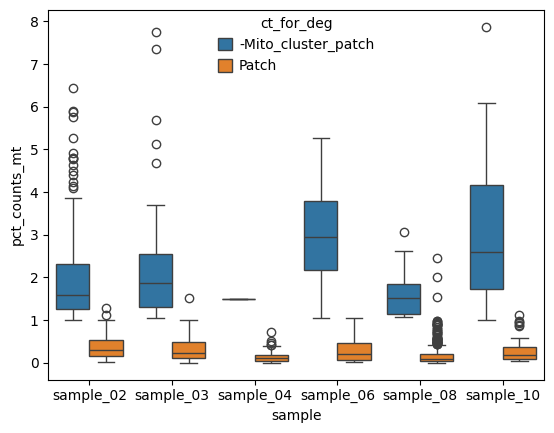

ct_for_deg  -Mito_cluster_patch  Patch
sample                                
sample_02                   136    568
sample_03                    46    262
sample_04                     1     71
sample_06                    17     64
sample_08                    33    437
sample_10                    22     45


/tmp/ipykernel_53216/3825799251.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby([SAMPLE_VARIABLE, CONTRAST_VARIABLE]).size().unstack())


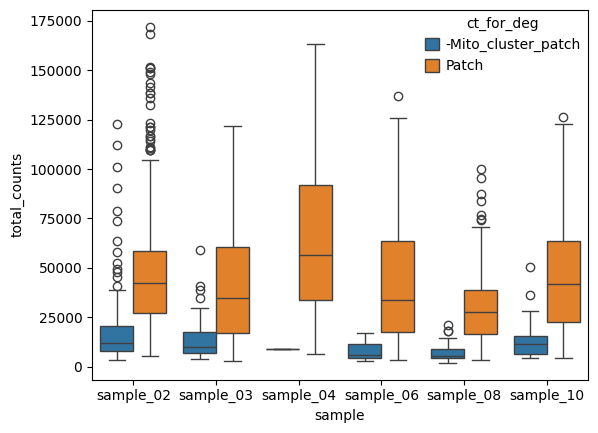

In [18]:
import seaborn as sns
sns.boxplot(data=adata.obs, x=SAMPLE_VARIABLE, y=MITO_COL, hue=CONTRAST_VARIABLE); plt.show()
sns.boxplot(data=adata.obs, x=SAMPLE_VARIABLE, y=LIBRARY_SIZE_COL, hue=CONTRAST_VARIABLE)
print(adata.obs.groupby([SAMPLE_VARIABLE, CONTRAST_VARIABLE]).size().unstack())


## Filter genes and sampples

In [19]:
# filter genes adn samples
adata = filter_genes_for_nebula(adata, SAMPLE_VARIABLE, CONTRAST_VARIABLE, 
    min_cells_per_sample=10, 
    min_counts=50)

# Filter: keep only samples with enough cells in BOTH conditions
MIN_CELLS_PER_CONDITION = 5
counts = pd.crosstab(adata.obs[SAMPLE_VARIABLE], adata.obs[CONTRAST_VARIABLE])
keep_samples = counts[(counts[CONTRAST_BASELINE] >= MIN_CELLS_PER_CONDITION) & 
                       (counts[CONTRAST_STIM]     >= MIN_CELLS_PER_CONDITION)].index
print(f"Keeping samples: {keep_samples.tolist()}")
adata = adata[adata.obs[SAMPLE_VARIABLE].isin(keep_samples)].copy()


# Sanity check: enough samples per condition
MIN_SAMPLES = 3
counts = (
    adata.obs[[SAMPLE_VARIABLE, CONTRAST_VARIABLE]]
    .drop_duplicates()
    .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
    .count()
    .reindex([CONTRAST_BASELINE, CONTRAST_STIM], fill_value=0)
)
print(counts)
assert (counts >= MIN_SAMPLES).all(), f"Too few samples per condition (need >= {MIN_SAMPLES})"

ATTENTION: .X must be raw!
Retained donors : 6
Filtered genes  : 37588 -> 16653 (min_cells=60, min_counts=50)
Keeping samples: ['sample_02', 'sample_03', 'sample_06', 'sample_08', 'sample_10']
ct_for_deg
Patch                  5
-Mito_cluster_patch    5
Name: sample, dtype: int64


/tmp/ipykernel_53216/602145137.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


## Drop cells with missing covariates

In [20]:
all_covs = [CONTRAST_VARIABLE, *COVARIATES]
mask = adata.obs[all_covs].isna().any(axis=1)
print(f"Dropping {mask.sum()} cells with NaN covariates")
display(adata.obs[mask][[SAMPLE_VARIABLE, *all_covs]])
adata = adata[~mask].copy()

pd.crosstab(adata.obs[SAMPLE_VARIABLE], adata.obs[CONTRAST_VARIABLE])

Dropping 0 cells with NaN covariates


,sample,ct_for_deg,age_at_death,pct_intronic,Sorted,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10


ct_for_deg,-Mito_cluster_patch,Patch
sample,,
sample_02,136,568
sample_03,46,262
sample_06,17,64
sample_08,33,437
sample_10,22,45


## Simple wilcoxon per sample

###############à
Processing sample: sample_02
################


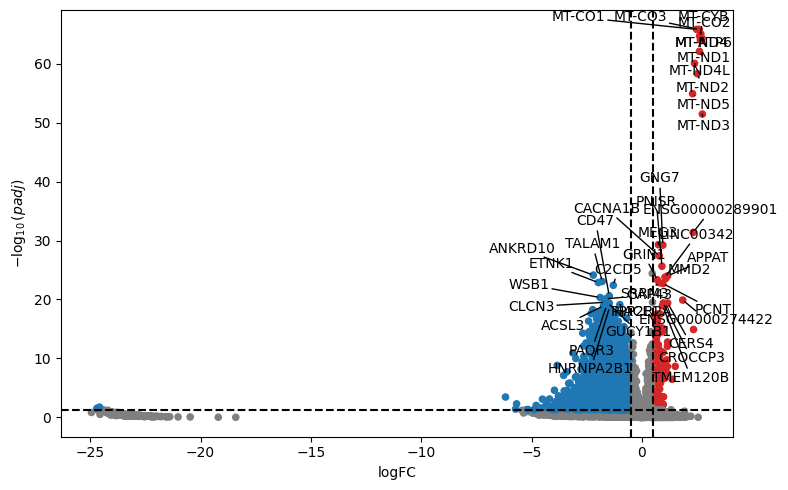

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
32,ZNF91,9.024644,0.704241,1.802803e-19,3.706430e-17,1.000000,sample_02,1.000000
16610,OGT,-9.100924,-1.308528,8.956713e-20,1.988749e-17,0.529412,sample_02,0.940141


###############à
Processing sample: sample_03
################


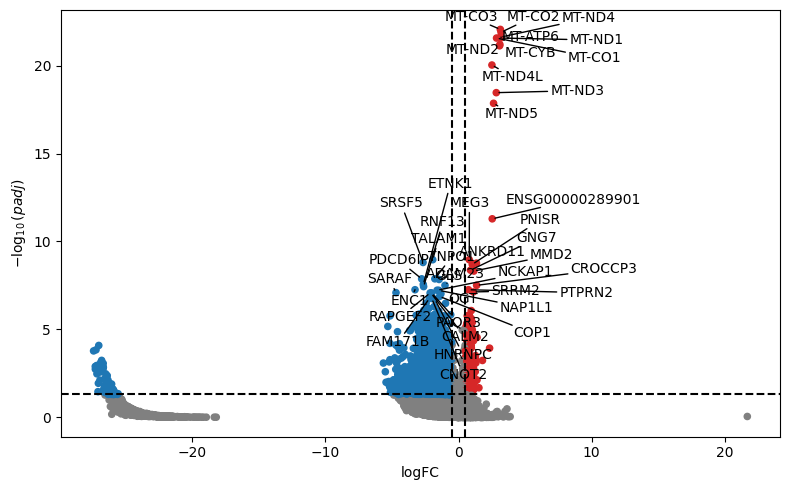

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
358,ZNF91,2.015866,0.325823,4.381403e-02,1.477592e-01,0.913043,sample_03,0.988550
16637,OGT,-6.359042,-1.325409,2.030161e-10,9.391188e-08,0.630435,sample_03,0.912214


###############à
Processing sample: sample_06
################


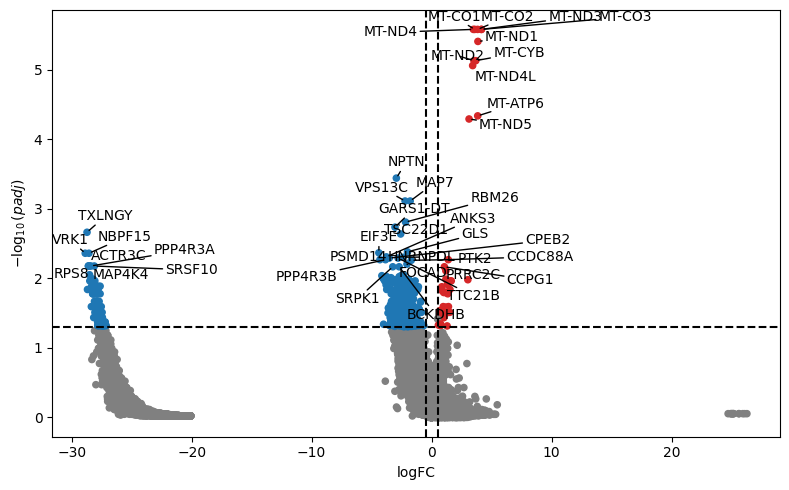

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
50,ZNF91,2.974792,0.815071,0.002932,0.066154,0.941176,sample_06,0.953125
11633,OGT,-1.525088,-0.631258,0.127237,0.402064,0.352941,sample_06,0.796875


###############à
Processing sample: sample_08
################
0 [-0.38798192 -0.70486698]
2 [0.26909812 0.0488195 ]
0 [-0.41693302  0.25634144]
2 [ 0.42870375 -0.45482398]


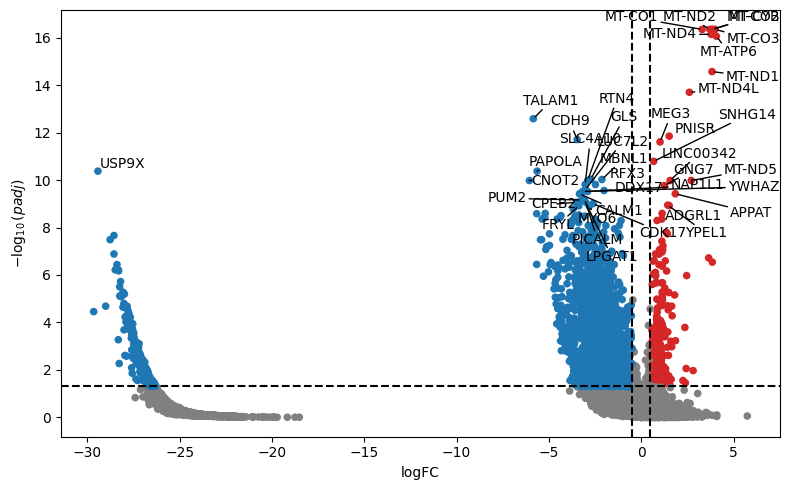

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
34,ENSG00000289901,5.923473,3.851602,3.152131e-09,2.884200e-07,0.696970,sample_08,0.180778
194,MT-ATP8,3.147489,2.810999,1.646795e-03,1.073349e-02,0.424242,sample_08,0.137300


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
416,ZNF91,1.838250,0.177811,6.602552e-02,1.799547e-01,0.848485,sample_08,0.983982
16587,OGT,-6.438529,-2.394134,1.206374e-10,2.257275e-08,0.303030,sample_08,0.901602


###############à
Processing sample: sample_10
################


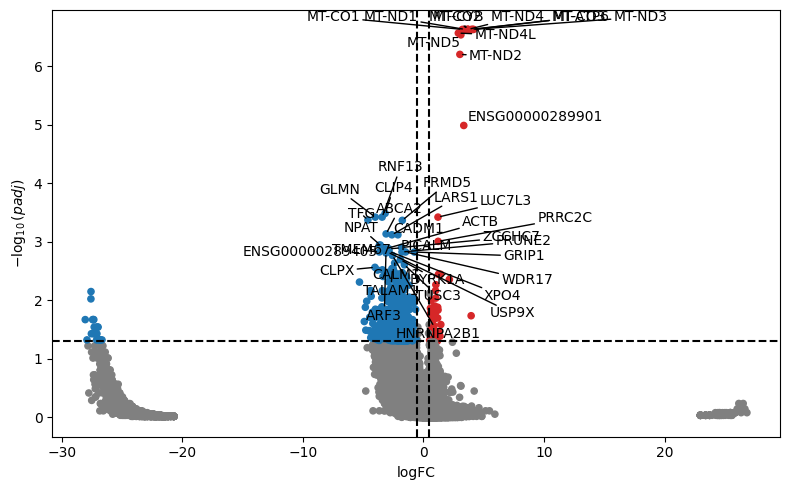

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
204,ZNF91,1.989321,0.606205,0.046666,0.249398,1.0,sample_10,0.977778
16502,OGT,-3.785050,-1.519529,0.000154,0.014210,0.5,sample_10,0.933333


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,sample,pct_nz_rest
0,MT-CO3,17.784540,2.592071,9.312287e-71,1.514163e-66,1.000000,sample_02,0.994718
1,MT-CO1,17.746988,2.474881,1.818487e-70,1.514163e-66,1.000000,sample_02,0.998239
2,MT-CO2,17.622595,2.666270,1.652494e-69,9.172992e-66,1.000000,sample_02,0.996479
3,MT-CYB,17.562510,2.608990,4.771776e-69,1.986610e-65,1.000000,sample_02,0.996479
4,MT-ATP6,17.497732,2.720672,1.490903e-68,4.965601e-65,1.000000,sample_02,0.966549
...,...,...,...,...,...,...,...,...
83260,FRMD5,-5.040058,-1.755357,4.653910e-07,4.305643e-04,0.772727,sample_10,1.000000
83261,TFG,-5.053409,-4.607499,4.339930e-07,4.251345e-04,0.045455,sample_10,0.800000
83262,GLMN,-5.086787,-3.999583,3.641806e-07,3.790437e-04,0.136364,sample_10,0.822222
83263,RNF13,-5.086787,-3.429322,3.641806e-07,3.790437e-04,0.181818,sample_10,0.844444


In [21]:
import pandas as pd
import scanpy as sc
import decoupler as dc

dfs = []
for sample in adata.obs[SAMPLE_VARIABLE].unique():
    print(f"###############à\nProcessing sample: {sample}\n################")
    adata_wc = adata[adata.obs[SAMPLE_VARIABLE] == sample].copy()
    sc.pp.normalize_total(adata_wc, target_sum=1e4)
    sc.pp.log1p(adata_wc)

    sc.tl.rank_genes_groups(
        adata_wc,
        groupby=CONTRAST_VARIABLE,
        groups=[CONTRAST_STIM],
        reference=CONTRAST_BASELINE,
        method="wilcoxon",
        use_raw=False,
        key_added="wilcoxon",
        pts=True,
    )

    df = sc.get.rank_genes_groups_df(adata_wc, group=CONTRAST_STIM, key="wilcoxon")
    df["sample"] = sample
    pts_matrix = adata_wc.uns["wilcoxon"]["pts"]
    baseline_pcts = pts_matrix[CONTRAST_BASELINE]
    df["pct_nz_rest"]  = df["names"].map(baseline_pcts) 
    dfs.append(df)

    dc.pl.volcano(
        df.set_index("names").rename(columns={"pvals_adj": "padj", "logfoldchanges": "logFC"}),
        x="logFC",
        y="padj",
        top=40,
        thr_sign=0.05,
        thr_stat=0.5,
        figsize=(8, 5),
    ); plt.show()

    df_sig = df[df["pvals_adj"] < 0.05]
    display(df_sig[(df_sig["pct_nz_rest"] < 0.2) & (df_sig["pct_nz_group"] > 0.2)])  # only sig genes that are expressed in baseline
    display(df[df["names"].isin(["ZNF91", "OGT"])])

df_all = pd.concat(dfs, ignore_index=True)
df_all


## Convert to .qs and run Nebula

In [22]:
QS_PATH = f"{SAVE_FOLDER}/adata_for_nebula.qs"

tmp_dir = tempfile.mkdtemp(dir="/tmp")

adata.X = adata.layers["counts"].copy()

preprocessing.save_files_for_R_conversion(adata, tmp_dir)
preprocessing.build_qs_from_python_files(
    tmp_dir, saving_path=QS_PATH,
    contrast_var=CONTRAST_VARIABLE, reference_level=CONTRAST_BASELINE
)

2026-10-28 15:06:06 | [WARNING] R callback write-console: Loading required package: SeuratObject
  
2026-10-28 15:06:06 | [WARNING] R callback write-console: Loading required package: sp
  
2026-10-28 15:06:07 | [WARNING] R callback write-console: 
Attaching package: ‘SeuratObject’

  
2026-10-28 15:06:07 | [WARNING] R callback write-console: The following objects are masked from ‘package:base’:

    %||%, intersect, t

  



    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

2026-10-28 15:06:10 | [WARNING] R callback write-console: 
Attaching package: ‘Seurat’

  
2026-10-28 15:06:10 | [WARNING] R callback write-console: The following object is masked from ‘package:base’:

    %||%

  
2026-10-28 15:06:10 | [WARNING] R callback write-console: qs 0.27.3. Announcement: https://github.com/qsbase/qs/issues/103
  



Setting ct_for_deg reference level to: Patch
Levels: Patch -Mito_cluster_patch 
[1] "Creating Seurat object..."


2026-10-28 15:06:16 | [WARNING] R callback write-console: Warning:  
2026-10-28 15:06:16 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."


In [ ]:
QS_PATH

'/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/mito_patch_VS_patch_dead_region/adata_for_nebula.qs'

In [23]:
# it silently drops any row with an NA in any covariate
nebula_result_path = DEG.run_nebula_parallel_script(
    path_qs             = QS_PATH,
    path_nebula_script  = PARALLEL_NEBULA_SCRIPT_PATH,
    id_col              = SAMPLE_VARIABLE,
    covs                = [CONTRAST_VARIABLE, *COVARIATES],
    offset_col          = LIBRARY_SIZE_COL,
    n_folds             = 40,
    n_cores             = 40,
    save_tmp            = False,
)

cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/mito_patch_VS_patch_dead_region/adata_for_nebula.qs', '--id-col', 'sample', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/mito_patch_VS_patch_dead_region/adata_for_nebula.qs --id-col sample --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/mito_patch_VS_patch_dead_region/adata_for_nebula.qs --id-col sample --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0 --covs ct_for_deg,age_at_death,pct_intronic,Sorted,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,P

## Save results

In [24]:
ro.r(f'''
    library(qs)
    obj <- qread("{nebula_result_path}")
    df  <- obj$summary
    write.csv(df, "{save_csv_path}", row.names=FALSE)
''')
save_csv_path

'/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/mito_patch_VS_patch_dead_region/nebula_results.csv'

In [25]:
# Clean up tmp .qs (optional)
os.remove(QS_PATH)

## Polish results

In [26]:
PVAL_BETA_CONSTRAST = f"p_{CONTRAST_VARIABLE}{CONTRAST_STIM}"
LOGFC_BETA_CONSTRAST = f"logFC_{CONTRAST_VARIABLE}{CONTRAST_STIM}"
PVAL_BETA_MITO = f"p_{MITO_COL}"
LOGFC_BETA_MITO = f"logFC_{MITO_COL}"
PVAL_BETA_CONSTRAST, LOGFC_BETA_CONSTRAST, PVAL_BETA_MITO, LOGFC_BETA_MITO

('p_ct_for_deg-Mito_cluster_patch',
 'logFC_ct_for_deg-Mito_cluster_patch',
 'p_pct_counts_mt',
 'logFC_pct_counts_mt')

In [37]:
import gseapy as gp
import pandas as pd
import numpy as np

collections_gsea = [
    ("MSigDB_Hallmark_2020",                 ["MSigDB_Hallmark_2020"],                              gp.get_library("MSigDB_Hallmark_2020"),              4,  250),
    ("SynGO_2024",                           ["SynGO_2024"],                                        gp.get_library("SynGO_2024"),              4,  250),
    ("Reactome_Pathways_2024",               ["Reactome_Pathways_2024"],                          gp.get_library("Reactome_Pathways_2024"),             4,  250),
    ("GO_Biological_Process_2025",           ["GO_Biological_Process_2025"],                      gp.get_library("GO_Biological_Process_2025"),         4,  250),
    ("ENCODE_and_ChEA_Consensus_TFs_from_ChIP-X", ["ENCODE_and_ChEA_Consensus_TFs_from_ChIP-X"], gp.get_library("ENCODE_and_ChEA_Consensus_TFs_from_ChIP-X"), 4, 250),
    ("TRRUST_Transcription_Factors_2019",    ["TRRUST_Transcription_Factors_2019"],               gp.get_library("TRRUST_Transcription_Factors_2019"),  4,  250),
]

# Build ranked gene list: sign(logFC) * -log10(p)
df_deg = df_results[["gene", PVAL_BETA_CONSTRAST, LOGFC_BETA_CONSTRAST]].copy()  # your df with gene, p_..., logFC_... columns

P_COL   = "p_ct_for_deg-Mito_cluster_patch"
FC_COL  = "logFC_ct_for_deg-Mito_cluster_patch"

df_deg["rank_metric"] = np.sign(df_deg[FC_COL]) * -np.log10(df_deg[P_COL].clip(lower=1e-300))
df_deg = df_deg.sort_values("rank_metric", ascending=False)
ranked = df_deg.set_index("gene")["rank_metric"]

# Run GSEA for each collection
gsea_results = {}

for name, _, gene_set, min_size, max_size in collections_gsea:
    print(f"Running GSEA: {name} ...")
    try:
        res = gp.prerank(
            rnk             = ranked,
            gene_sets       = gene_set,
            min_size        = min_size,
            max_size        = max_size,
            permutation_num = 1000,
            outdir          = None,   # no files written
            seed            = 42,
            verbose         = False,
        )
        df_res = res.res2d.copy()
        df_res["collection"] = name
        gsea_results[name] = df_res
        print(f"  ✓ {len(df_res)} terms tested")
    except Exception as e:
        print(f"  ✗ Failed: {e}")

# Combine all results
df_gsea_all = pd.concat(gsea_results.values(), axis=0)
df_gsea_all = df_gsea_all.sort_values("FDR q-val")

display(df_gsea_all[df_gsea_all["FDR q-val"] < 0.25][[
    "collection", "Term", "ES", "NES", "NOM p-val", "FDR q-val", "Lead_genes"
]])

2026-10-28 15:43:57 | [INFO] Downloading and generating Enrichr library gene sets...
2026-10-28 15:43:57 | [INFO] Library is already downloaded in: /home/gdallagl/.cache/gseapy/Enrichr.MSigDB_Hallmark_2020.gmt, use local file
2026-10-28 15:43:57 | [INFO] Downloading and generating Enrichr library gene sets...
2026-10-28 15:43:57 | [INFO] Library is already downloaded in: /home/gdallagl/.cache/gseapy/Enrichr.SynGO_2024.gmt, use local file
2026-10-28 15:43:58 | [INFO] Downloading and generating Enrichr library gene sets...
2026-10-28 15:43:58 | [INFO] Library is already downloaded in: /home/gdallagl/.cache/gseapy/Enrichr.Reactome_Pathways_2024.gmt, use local file
2026-10-28 15:43:58 | [INFO] 0005 gene_sets have been filtered out when max_size=2000 and min_size=0
2026-10-28 15:43:58 | [INFO] Downloading and generating Enrichr library gene sets...
2026-10-28 15:43:58 | [INFO] Library is already downloaded in: /home/gdallagl/.cache/gseapy/Enrichr.GO_Biological_Process_2025.gmt, use local fi

Running GSEA: MSigDB_Hallmark_2020 ...
  ✓ 50 terms tested
Running GSEA: SynGO_2024 ...
  ✓ 126 terms tested
Running GSEA: Reactome_Pathways_2024 ...
  ✓ 1846 terms tested
Running GSEA: GO_Biological_Process_2025 ...
  ✓ 4567 terms tested
Running GSEA: ENCODE_and_ChEA_Consensus_TFs_from_ChIP-X ...
  ✓ 34 terms tested
Running GSEA: TRRUST_Transcription_Factors_2019 ...
  ✓ 417 terms tested


,collection,Term,ES,NES,NOM p-val,FDR q-val,Lead_genes
0,MSigDB_Hallmark_2020,Myc Targets V1,-0.581403,-1.953906,0.0,0.0,HNRNPA2B1;NCBP1;PSMD1;HNRNPC;SRSF1;HNRNPU;PA2G...
0,Reactome_Pathways_2024,rRNA Processing in the Mitochondrion,0.98858,2.680362,0.0,0.0,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
15,Reactome_Pathways_2024,RHOBTB2 GTPase Cycle,-0.778388,-2.004532,0.0,0.0,HNRNPC;RHOBTB2;DBN1;CCT2;CUL3;MYO6;DDX39B;TXNL...
1,Reactome_Pathways_2024,tRNA Processing in the Mitochondrion,0.991716,2.679491,0.0,0.0,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
2,MSigDB_Hallmark_2020,mTORC1 Signaling,-0.558251,-1.871796,0.0,0.000384,SERP1;HSP90B1;HSPA4;PPA1;PSMC6;GBE1;EIF2S2;PNO...
...,...,...,...,...,...,...,...
178,GO_Biological_Process_2025,Prot Transport to Vacuole Inv in Ub-dep Prot C...,-0.662999,-1.575437,0.012483,0.246686,STAM2;TSG101;STAM;VPS36;VPS37A
193,GO_Biological_Process_2025,Regulation of DNA-templated DNA Replication (G...,-0.766386,-1.568087,0.008357,0.2468,METTL4;MCM4;WRNIP1;MCM7;MCM3
175,GO_Biological_Process_2025,Mitochondrial Fragmentation Involved in Apopto...,-0.82733,-1.57632,0.006024,0.247694,DNM1L;CCAR2
551,Reactome_Pathways_2024,The NLRP3 Inflammasome,-0.670807,-1.351338,0.102273,0.249495,HSP90AB1;APP;NFKB1;PANX1


In [38]:
display(df_gsea_all[(df_gsea_all["FDR q-val"] < 0.05) & (df_gsea_all["NES"] > 0)][[
    "collection", "Term", "ES", "NES", "NOM p-val", "FDR q-val", "Lead_genes"
]].head(50))



,collection,Term,ES,NES,NOM p-val,FDR q-val,Lead_genes
0,Reactome_Pathways_2024,rRNA Processing in the Mitochondrion,0.98858,2.680362,0.0,0.0,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
1,Reactome_Pathways_2024,tRNA Processing in the Mitochondrion,0.991716,2.679491,0.0,0.0,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
3,Reactome_Pathways_2024,Cytoprotection by HMOX1,0.876455,2.624462,0.0,0.001481,MT-CO3;MT-CO1;MT-CO2;HMOX2
4,Reactome_Pathways_2024,Complex IV Assembly,0.894554,2.611113,0.0,0.001712,MT-CO3;MT-CO1;MT-CO2
2,Reactome_Pathways_2024,Mitochondrial RNA Degradation,0.983569,2.626788,0.0,0.001975,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
5,Reactome_Pathways_2024,rRNA Processing,0.81524,2.536936,0.0,0.004938,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
6,Reactome_Pathways_2024,FASTK Family Proteins Regulate Processing and ...,0.995169,2.49785,0.0,0.010817,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...
7,Reactome_Pathways_2024,tRNA Processing,0.87672,2.44317,0.0,0.022386,MT-CO3;MT-CYB;MT-CO1;MT-CO2;MT-ND4;MT-ATP6;MT-...


Convergence failures (p=1): 0 / 16653


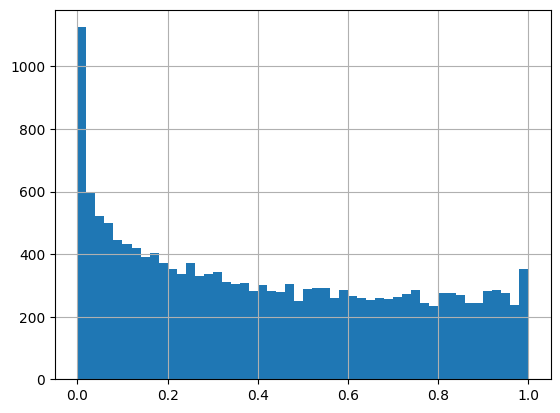

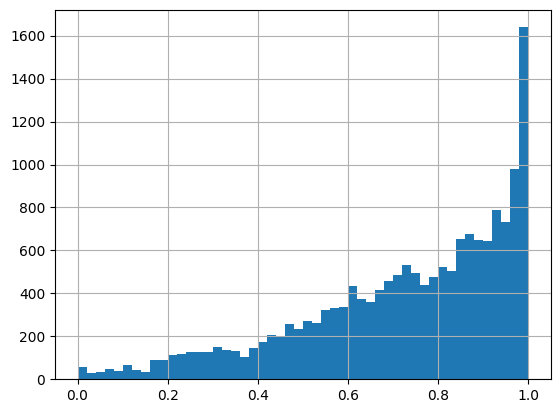

Significant genes: 102


,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj
61,ENSG00000278445,8.930440e-05,1.617752,2.398687e-02
74,CCDC74B,1.471283e-04,1.163739,3.266836e-02
57,PPP1R26-AS1,7.114648e-05,1.116679,2.042763e-02
11,MT-ATP8,2.740698e-15,0.866190,3.803404e-12
10,MT-ND3,8.220476e-34,0.848363,1.244505e-30
0,MT-CO3,8.773041e-56,0.828114,1.460974e-51
1,MT-CYB,2.645361e-55,0.817619,2.202660e-51
4,MT-ND4,2.003071e-47,0.817346,6.671428e-44
3,MT-CO2,3.540380e-52,0.806423,1.473949e-48
5,MT-ATP6,1.868061e-44,0.799784,5.184805e-41


In [30]:
df_results = pd.read_csv(save_csv_path)

# separate failed fits from real results
mask_failed = df_results[PVAL_BETA_CONSTRAST] >= 1.0
print(f"Convergence failures (p=1): {mask_failed.sum()} / {len(df_results)}")

from statsmodels.stats.multitest import multipletests
df_results["p_adj"] = multipletests(df_results[PVAL_BETA_CONSTRAST], method="fdr_bh")[1]

# show pval distribution
df_results[PVAL_BETA_CONSTRAST].hist(bins=50); plt.show()
df_results["p_adj"].hist(bins=50); plt.show()

# seort by pvalue
df_results = df_results.sort_values(PVAL_BETA_CONSTRAST)

# remove mito
#df_results = df_results[~df_results["gene"].str.startswith("MT-")]

df_results.reset_index(drop=True, inplace=True)

# filter specific columns
if WITH_MITO_COV:
    df_results = df_results[["gene", PVAL_BETA_CONSTRAST, LOGFC_BETA_CONSTRAST, PVAL_BETA_MITO, LOGFC_BETA_MITO, "p_adj"]]
else:
    df_results = df_results[["gene", PVAL_BETA_CONSTRAST, LOGFC_BETA_CONSTRAST, "p_adj"]]


# creat only significant df
df_sig = df_results[(df_results["p_adj"] < 0.05) & (df_results[LOGFC_BETA_CONSTRAST].abs() > 0.1)].copy()
df_results["is_significant"] = df_sig["gene"].isin(df_results["gene"])
print(f"Significant genes: {len(df_sig)}")

df_sig.head(50)
df_sig.sort_values(LOGFC_BETA_CONSTRAST, ascending=False).head(50)

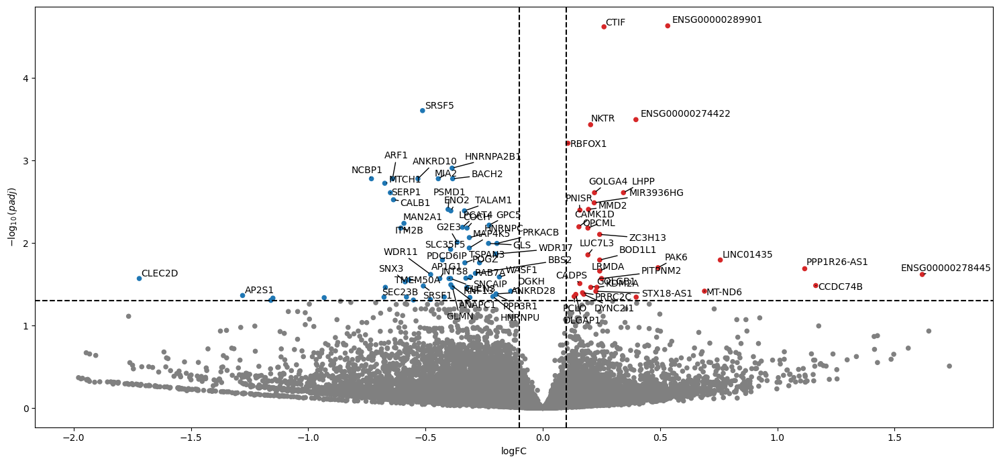

In [31]:
import decoupler as dc
dc.pl.volcano(
    df_results.set_index("gene").rename(columns={"p_adj": "padj", LOGFC_BETA_CONSTRAST: "logFC"}), # ccan manage "_"
    x="logFC",
    y="padj",
    top=80,
    thr_stat=0.1, # logFC thresholdFORCE TO SEE ALL
    thr_sign=0.05,
    max_stat=2,        # clip x-axis to ±5
    max_sign=-np.log10(1e-10), # clip y-axis to -log10(1e-10) ATTENYION !!!
    figsize=(15, 7)
)

### Load genes famileies

In [32]:
prc2_genes = [
                                'POU4F2', 'TWIST1', 'ALDH1A2', 'IRX5', 'CALCR', 'CDKN2A', 'SKOR1', 'PITX2',
                                'HOXC8', 'WT1', 'SFMBT2', 'POU4F1', 'TAL1', 'PNMT', 'DSP', 'CDHR1', 'SPP1',
                                'HOXD8', 'NKX6-1', 'HOXC4', 'RIPK4', '4933436C20RIK', 'LECT1', 'ALDH1A7',
                                'PYGL', 'DMRT3', 'TFAP2C', 'FST', 'GPR101', 'RUNX3', 'ONECUT2', 'BARX1',
                                'AMN', 'TMEM30B', 'IRX3', 'CCND1', 'IRX2', 'S100A10', 'FAM196B', 'LGALS3',
                                'SIX6', 'COX6B2', 'TBX2', 'CD44', 'ASB4', 'PTPLAD2', 'SCARF2', 'VGLL2',
                                'BNC2', 'LYPD1', 'GATA3', 'OTOF', 'HOXD10', 'HOXA9', 'HOXC10', 'SLC6A5',
                                'LBX1', 'HOXA5', 'TBX20', 'HAND2', 'HOXD9', 'HOXB7', 'HOXB8', 'MNX1',
                                'DMRTA2', 'FOXF1', 'SIM2', 'GATA6', 'SIX2', 'LUM', 'GATA2', 'PMAIP1',
                                'HOXA10', 'BHLHE22', 'FOXD1', 'PITX1', 'PAX1', 'FOXL2OS', 'HMX1', 'TBX3',
                                'FOXA1', 'EBF3', 'SIM1', '1500016L03RIK', 'HOXB13', 'EN1', 'SERPINA3N',
                                'RGNEF', 'HOXD13', 'LHX5', 'HOXA7', 'BC061194', 'HOXC5', 'NEUROD1', 'TFAP2A',
                                'HOXB5', 'SHOX2', 'TFAP2B', 'NEUROD2', '2610027K06RIK', 'TLX1', 'TNNT2',
                                'SULT1A1', 'VAX2', '1500011B03RIK', 'RPRD2', 'HOXD11', 'CDKN1A', 'NEUROG2',
                                'EOMES', 'PLIN4', 'TPBG', '4930447C04RIK', 'SSTR3', 'DLK1', 'PRDM8',
                                'E030030I06RIK', 'CES1D', 'HOXA4', 'NRN1', 'VSX2', 'AI448005', 'GFI1',
                                'ADCYAP1', 'LHX1', 'NKX3-1', 'LHX9', 'ZIC2', 'MATN2', 'HOXB3', 'KRT1',
                                'IGFBP3', 'FBN1', 'OVGP1', 'CDKN2B', 'HOXB2', 'HEYL', 'GSTA3', 'NKX2-5',
                                'TSHZ2', 'FOXD2', 'ALDOC', 'HMGCS2', 'DLX4', 'C130021I20RIK', 'SIX1', 'GRP',
                                'COL23A1', 'CIRBP', 'A030001D16RIK', 'HOXB6', 'LMX1B', 'CBX4', 'RPRM',
                                'PAX3', 'MFSD4', 'GPR50', 'SFRP2', 'UGT1A1', 'UGT1A10', 'UGT1A2', 'UGT1A5',
                                'UGT1A6A', 'UGT1A6B', 'UGT1A7C', 'UTG1A9', 'ISLR', 'ASB5', 'MYCL1',
                                'TRP53I11', 'SDC1', '9530018H14RIK', 'GATA4', 'BEND5', 'GM15453', 'RBM3',
                                'FXYD7', 'FOXL2', '1700109F18RIK', 'GM8350', 'ZFP644', '4933439C10RIK',
                                'ONECUT1', 'DAB1', 'ZFAND4', 'RPP25', 'CLDN3', 'SLC6A7', 'SERPINB1B',
                                'COLEC11', 'S100A8', 'COL6A2', 'CYBRD1', 'MMD', 'GALNTL1', 'GNA13', 'ALX1',
                                'NTF3', 'GRHL1', 'HOXA3', 'FHOD3', 'GREB1L', 'PAMR1', 'CPA6', 'DMRT2',
                                'CPNE6', '9330171B17RIK', 'BID', 'C1QTNF1', 'KAZALD1', 'HOXD3', 'SLCO4A1',
                                'S100A9', 'MYO5B', 'ANXA1', 'ACY3', 'SH2B2'
                            ]

In [33]:
GRAD_THR=0.1

df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv")

grad_genes = df_grad[
    (np.abs(df_grad.mean_spearman)>= GRAD_THR) & 
    (df_grad.combined_p <= 0.05) &
    (df_grad.mean_spearman.notna()) 
    ]["gene"].tolist()
print(len(grad_genes))

df_grad["is_gradient_gene"] = df_grad["gene"].isin(grad_genes)
print(df_grad["is_gradient_gene"].sum())
df_grad = df_grad.set_index("gene")[["mean_spearman", "is_gradient_gene"]]
df_grad

1241
1241


,mean_spearman,is_gradient_gene
gene,,
A1BG,-0.002360,False
A1BG-AS1,-0.007881,False
A1CF,0.007398,False
A2M,-0.002144,False
A2M-AS1,-0.000389,False
...,...,...
ENSG00000277836,NaN,False
ENSG00000278633,NaN,False
ENSG00000276017,-0.008289,False


In [34]:
# ATTENTION: decide whcih fatset use a ref for mito genes
mito_corr_genes_df = pd.read_csv("/home/gdallagl/myworkdir/XDP/data/_old/corr_mito_genes/mito_corr_genes_bican_Patch.csv")
n_genes = len(mito_corr_genes_df)
display(mito_corr_genes_df)
display(mito_corr_genes_df[mito_corr_genes_df["gene"].isin(["ZNF91", "ZSWIM6", "PNISR"])])
mito_corr_genes = mito_corr_genes_df[(mito_corr_genes_df["pval"] < 0.05) & (mito_corr_genes_df["rho"] > 0.1)]["gene"].tolist()
print("preprocessing mito corr genes", len(mito_corr_genes)/n_genes)
mito_corr_genes

,gene,rho,pval,pval_bh
0,MT-CO3,0.926298,0.000000e+00,0.000000e+00
1,MT-CO1,0.891081,0.000000e+00,0.000000e+00
2,MT-ND4,0.887264,0.000000e+00,0.000000e+00
3,MT-CO2,0.878906,0.000000e+00,0.000000e+00
4,MT-ATP6,0.873425,0.000000e+00,0.000000e+00
...,...,...,...,...
22557,B3GLCT,-0.000021,1.090597e-90,1.830807e-90
22558,RSRP1,0.000013,3.576666e-279,8.867773e-279
22559,CENATAC,-0.000010,5.013753e-209,1.072129e-208
22560,STMN2,0.000009,0.000000e+00,0.000000e+00


,gene,rho,pval,pval_bh
23,PNISR,0.157703,0.0,0.0
4148,ZSWIM6,-0.065926,0.0,0.0
6131,ZNF91,0.056954,0.0,0.0


preprocessing mito corr genes 0.002880950270366102


['MT-CO3',
 'MT-CO1',
 'MT-ND4',
 'MT-CO2',
 'MT-ATP6',
 'MT-ND2',
 'MT-CYB',
 'MT-ND1',
 'MT-ND3',
 'MT-ND5',
 'MT-ND4L',
 'DHFR',
 'MT-ATP8',
 'GNG7',
 'ZBTB7A',
 'JUND',
 'CELF5',
 'GRIN1',
 'CAMK2B',
 'ARPP19',
 'PEG3',
 'PNISR',
 'CALM1',
 'THY1',
 'PHYHIP',
 'CELF1',
 'HSP90AA1',
 'MT-ND6',
 'MEG3',
 'LINC00632',
 'NRGN',
 'TMEM120B',
 'GPR88',
 'BMS1P14',
 'YPEL1',
 'TSPYL1',
 'SYT11',
 'HPCA',
 'CYP46A1',
 'ELAVL3',
 'YWHAG',
 'BAIAP2',
 'JPH4',
 'CACNA1A',
 'FAIM2',
 'MAP1A',
 'MMD2',
 'PPP1R1B',
 'PRNP',
 'ST8SIA3',
 'LINGO3',
 'APPAT',
 'BCL11B',
 'LINC00342',
 'RASD2',
 'AKAP9',
 'CERS4',
 'ZER1',
 'ADGRL1',
 'CHST15',
 'EFR3B',
 'DKK3',
 'PRKCB',
 'MAPK1',
 'TTC3']

### Add info

In [35]:
df_sig["is_gradient_gene"] = df_sig["gene"].map(df_grad["is_gradient_gene"]).fillna(False)
print(df_sig["is_gradient_gene"].sum()/len(df_sig))

df_sig["is_mito_corr_gene"] = df_sig["gene"].isin(mito_corr_genes)
print(df_sig["is_mito_corr_gene"].sum()/len(df_sig))

df_sig["is_prc2_gene"] = df_sig["gene"].isin(prc2_genes)

df_sig["is_interesting_gene"] = (~df_sig["is_mito_corr_gene"]) & (~df_sig["is_gradient_gene"])

df_sig.to_csv(f"{SAVE_FOLDER}/significant_genes_annotated.csv", index=False)

display(df_sig.head(50))
print(f"Interesting genes over significant ones: {df_sig['is_interesting_gene'].sum()} / {len(df_sig)}")
display(df_sig[df_sig["is_interesting_gene"]].head(50).reset_index(drop=True))
# just postive logfc
display(df_sig[(df_sig["is_interesting_gene"]) & (df_sig[LOGFC_BETA_CONSTRAST] > 0)].head(50).reset_index(drop=True))
display(df_sig[df_sig["gene"].str.startswith("MT-")].head(50))

0.1568627450980392
0.14705882352941177


,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj,is_gradient_gene,is_mito_corr_gene,is_prc2_gene,is_interesting_gene
0,MT-CO3,8.773041e-56,0.828114,1.460974e-51,False,True,False,False
1,MT-CYB,2.645361e-55,0.817619,2.202660e-51,False,True,False,False
2,MT-CO1,2.602503e-52,0.749788,1.444649e-48,False,True,False,False
3,MT-CO2,3.540380e-52,0.806423,1.473949e-48,False,True,False,False
4,MT-ND4,2.003071e-47,0.817346,6.671428e-44,False,True,False,False
5,MT-ATP6,1.868061e-44,0.799784,5.184805e-41,False,True,False,False
6,MT-ND4L,2.298308e-44,0.721041,5.467676e-41,False,True,False,False
7,MT-ND2,1.969032e-38,0.714047,4.098786e-35,False,True,False,False
8,MT-ND5,2.172907e-36,0.714539,4.020602e-33,False,True,False,False
9,MT-ND1,3.250619e-36,0.719986,5.413255e-33,False,True,False,False


Interesting genes over significant ones: 72 / 102


,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj,is_gradient_gene,is_mito_corr_gene,is_prc2_gene,is_interesting_gene
0,ENSG00000289901,1.815789e-08,0.532709,0.000023,False,False,False,True
1,SRSF5,2.232899e-07,-0.512439,0.000248,False,False,False,True
2,ENSG00000274422,3.061380e-07,0.397116,0.000319,False,False,False,True
3,RBFOX1,6.650236e-07,0.107410,0.000615,False,False,False,True
4,ANKRD10,2.201347e-06,-0.532247,0.001658,False,False,False,True
5,BACH2,2.265426e-06,-0.384074,0.001658,False,False,False,True
6,NCBP1,2.273728e-06,-0.730419,0.001658,False,False,False,True
7,MIA2,2.311902e-06,-0.445260,0.001658,False,False,False,True
8,ARF1,2.390049e-06,-0.640352,0.001658,False,False,False,True
9,MTCH1,2.825917e-06,-0.673546,0.001882,False,False,False,True


,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj,is_gradient_gene,is_mito_corr_gene,is_prc2_gene,is_interesting_gene
0,ENSG00000289901,1.815789e-08,0.532709,0.000023,False,False,False,True
1,ENSG00000274422,3.061380e-07,0.397116,0.000319,False,False,False,True
2,RBFOX1,6.650236e-07,0.107410,0.000615,False,False,False,True
3,LHPP,3.901072e-06,0.344028,0.002448,False,False,False,True
4,GOLGA4,3.982030e-06,0.220501,0.002448,False,False,False,True
5,MIR3936HG,5.846512e-06,0.219239,0.003245,False,False,False,True
6,ZC3H13,2.024280e-05,0.242587,0.007840,False,False,False,True
7,LINC01435,5.013308e-05,0.756789,0.016013,False,False,False,True
8,BOD1L1,5.170827e-05,0.242748,0.016013,False,False,False,True
9,PAK6,6.796944e-05,0.491385,0.019858,False,False,False,True


,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj,is_gradient_gene,is_mito_corr_gene,is_prc2_gene,is_interesting_gene
0,MT-CO3,8.773041e-56,0.828114,1.460974e-51,False,True,False,False
1,MT-CYB,2.645361e-55,0.817619,2.202660e-51,False,True,False,False
2,MT-CO1,2.602503e-52,0.749788,1.444649e-48,False,True,False,False
3,MT-CO2,3.540380e-52,0.806423,1.473949e-48,False,True,False,False
4,MT-ND4,2.003071e-47,0.817346,6.671428e-44,False,True,False,False
5,MT-ATP6,1.868061e-44,0.799784,5.184805e-41,False,True,False,False
6,MT-ND4L,2.298308e-44,0.721041,5.467676e-41,False,True,False,False
7,MT-ND2,1.969032e-38,0.714047,4.098786e-35,False,True,False,False
8,MT-ND5,2.172907e-36,0.714539,4.020602e-33,False,True,False,False
9,MT-ND1,3.250619e-36,0.719986,5.413255e-33,False,True,False,False


In [36]:
# print some interesting genes
df_sig[df_sig["gene"].isin(["CACNA1A", "KDM2A","ZNF91", "TAF1", "OGA", "POLR2A", "ZSWIM6", "TAF1", "TIA1", "ZNF772", "SMG7", "ZNF93", "MOV10L1", "EXO1", "SSH", "GLIA1", "OGT", "GLI3", "MEG3",  "GNG7", "MT-ND6", "PNISR",
    "OGA", "OGT", 'GFPT1', 'GFPT2','GNPNAT1', 'PGM3', 'UAP1',
    "NONO",
    "MEG8"
    
    ])][["gene", PVAL_BETA_CONSTRAST, LOGFC_BETA_CONSTRAST, "p_adj", "is_gradient_gene", "is_mito_corr_gene", "is_prc2_gene", "is_interesting_gene"]]

,gene,p_ct_for_deg-Mito_cluster_patch,logFC_ct_for_deg-Mito_cluster_patch,p_adj,is_gradient_gene,is_mito_corr_gene,is_prc2_gene,is_interesting_gene
32,PNISR,0.000008,0.158412,0.003977,False,True,False,False
79,KDM2A,0.000166,0.230511,0.034344,False,False,False,True
82,MT-ND6,0.000190,0.689441,0.038212,False,True,False,False


In [ ]:
# df_results["-log_10(p_val)"] = -np.log10(df_results[PVAL_BETA_CONSTRAST])
# df_results = df_results.join(mito_corr_genes_df.set_index("gene")[["rho", "pval"]], on="gene", rsuffix="_mito_corr")
# df_results["is_mito_corr_gene"] = df_results["gene"].isin(mito_corr_genes)
# display(df_results)

# sns.scatterplot(df_results, x="-log_10(p_val)", y="rho", hue="is_mito_corr_gene"); plt.show()

# THR_LOG10P = 1.3
# THR_RHO = 0.1

# fig, ax = plt.subplots(figsize=(10, 6))
# sns.scatterplot(data=df_results, x="-log_10(p_val)", y="rho", 
#                 hue="is_mito_corr_gene", alpha=0.5, s=10, ax=ax)

# mask_label = (df_results["-log_10(p_val)"] > THR_LOG10P) & (df_results["rho"].abs() < THR_RHO)
# for _, row in df_results[mask_label].iterrows():
#     ax.annotate(row["gene"], (row["-log_10(p_val)"], row["rho"]),
#                 fontsize=7, ha="left", xytext=(3, 3), textcoords="offset points")

# plt.axhline(THR_RHO,  color="red", ls="--", lw=0.8)
# plt.axhline(-THR_RHO, color="red", ls="--", lw=0.8)
# plt.axvline(THR_LOG10P, color="grey", ls="--", lw=0.8)
# plt.xscale("linear")

# plt.tight_layout()
# plt.show()

In [ ]:
# Clean up tmp .qs (optional)
os.remove(QS_PATH)

In [ ]:
STOP

NameError: name 'STOP' is not defined

# DA

### Prepare

In [ ]:
adata = sc.read_h5ad(ADATA_PATH, backed="r")
adata.obs["sample"].unique()

['sample_01', 'sample_02', 'sample_03', 'sample_04', 'sample_05', 'sample_06', 'sample_07', 'sample_08', 'sample_09']
Categories (9, object): ['sample_01', 'sample_02', 'sample_03', 'sample_04', ..., 'sample_06', 'sample_07', 'sample_08', 'sample_09']

In [ ]:
obs = adata.obs.copy()
print(obs["sample"].unique())

adata.obs["condition"] = adata.obs["condition"].replace({"diseased ": "diseased"})

obs = obs[(obs["condition"] == "diseased") & (obs["sample"] != "sample_09")].copy()

# obs = obs[(obs["sample"] == "sample_02")].copy()

obs["sample"].unique()

['sample_01', 'sample_02', 'sample_03', 'sample_04', 'sample_05', 'sample_06', 'sample_07', 'sample_08', 'sample_09']
Categories (9, object): ['sample_01', 'sample_02', 'sample_03', 'sample_04', ..., 'sample_06', 'sample_07', 'sample_08', 'sample_09']


/tmp/ipykernel_439007/1873139153.py:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["condition"] = adata.obs["condition"].replace({"diseased ": "diseased"})


['sample_01', 'sample_02', 'sample_03', 'sample_08']
Categories (9, object): ['sample_01', 'sample_02', 'sample_03', 'sample_04', ..., 'sample_06', 'sample_07', 'sample_08', 'sample_09']

### Cell Proportions

In [ ]:
obs = adata.obs.copy()
print(obs["sample"].unique())

adata.obs["condition"] = adata.obs["condition"].replace({"diseased ": "diseased"})

obs = obs[(obs["condition"] == "diseased") & (obs["sample"] != "sample_09")].copy()

# obs = obs[(obs["sample"] == "sample_02")].copy()

obs["sample"].unique()

ct_for_deg,-Mito_cluster_matrix,Astrocyte,Matrix_D1,Matrix_D2,Microglia,Tcells,eMSN_D1D2,eMSN_NUDAP,eMSN_StrioMat
sample_01_radial_high_mito_patch,0.000000,0.060000,0.000000,0.000000,0.020000,0.020000,0.040000,0.000000,0.000000
sample_02_radial_high_mito_patch,0.001096,0.053728,0.006579,0.006579,0.054825,0.003289,0.006579,0.002193,0.004386
sample_03_radial_high_mito_patch,0.000000,0.098361,0.014754,0.014754,0.052459,0.001639,0.009836,0.000000,0.000000
sample_04_radial_high_mito_patch,0.000000,0.111111,0.015873,0.015873,0.000000,0.000000,0.015873,0.000000,0.000000
sample_06_radial_high_mito_patch,0.000000,0.163793,0.000000,0.000000,0.094828,0.000000,0.008621,0.000000,0.004310
sample_01_radial_patch_in_death,0.002984,0.067131,0.028344,0.071109,0.062158,0.000000,0.050224,0.038787,0.014918
sample_02_radial_patch_in_death,0.002160,0.079194,0.006479,0.008639,0.054716,0.002160,0.030958,0.005760,0.013679
sample_03_radial_patch_in_death,0.005445,0.130672,0.014519,0.009074,0.050817,0.001815,0.043557,0.000000,0.001815
sample_04_radial_patch_in_death,0.002747,0.070055,0.009615,0.015110,0.032967,0.000000,0.010989,0.001374,0.002747
sample_06_radial_patch_in_death,0.008065,0.125000,0.004032,0.008065,0.068548,0.006048,0.008065,0.000000,0.002016


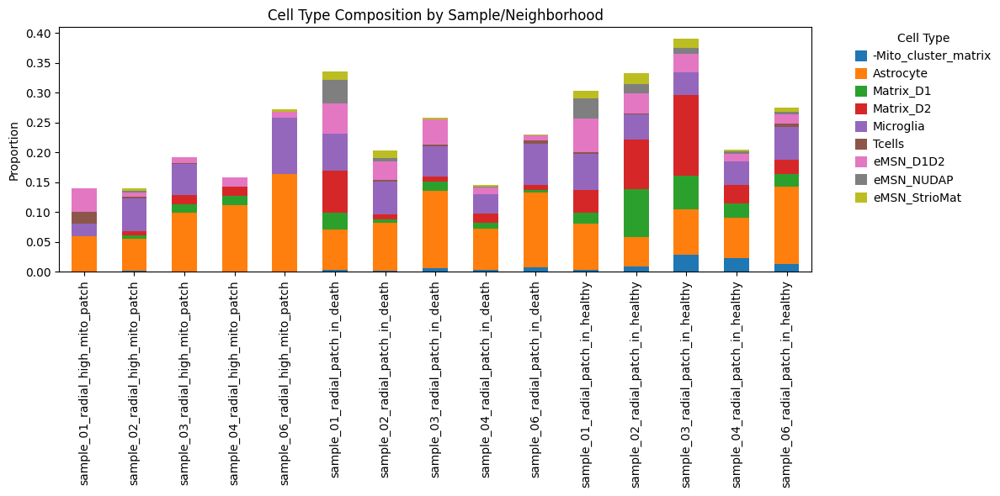

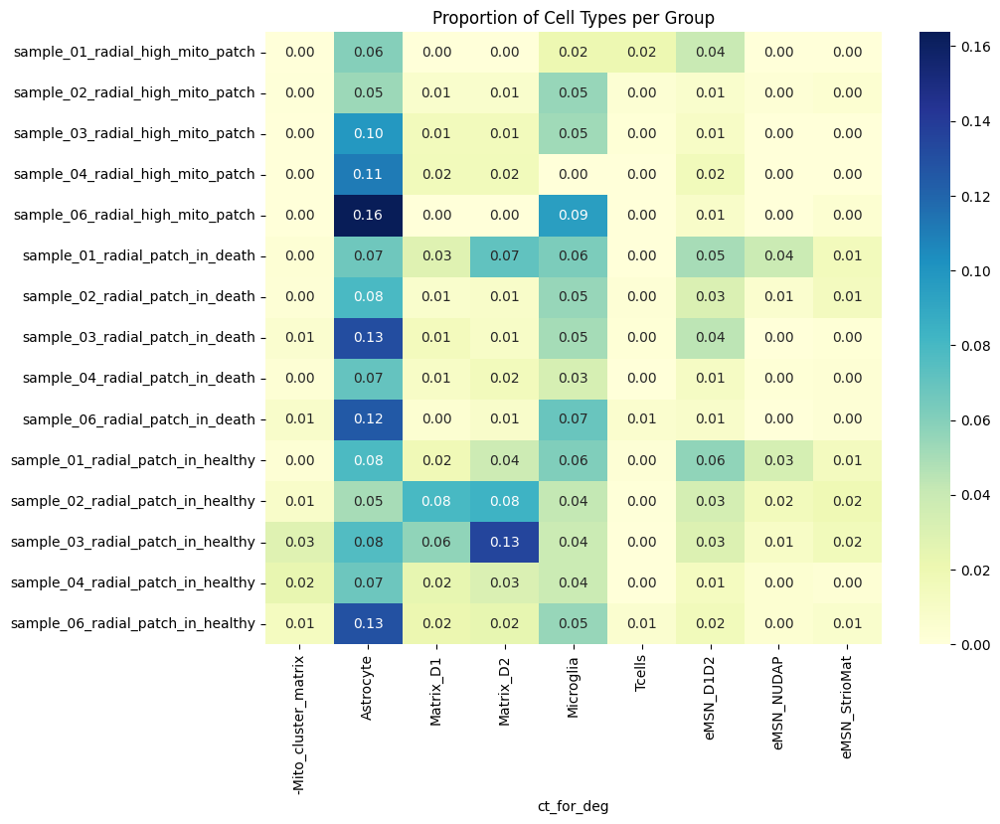

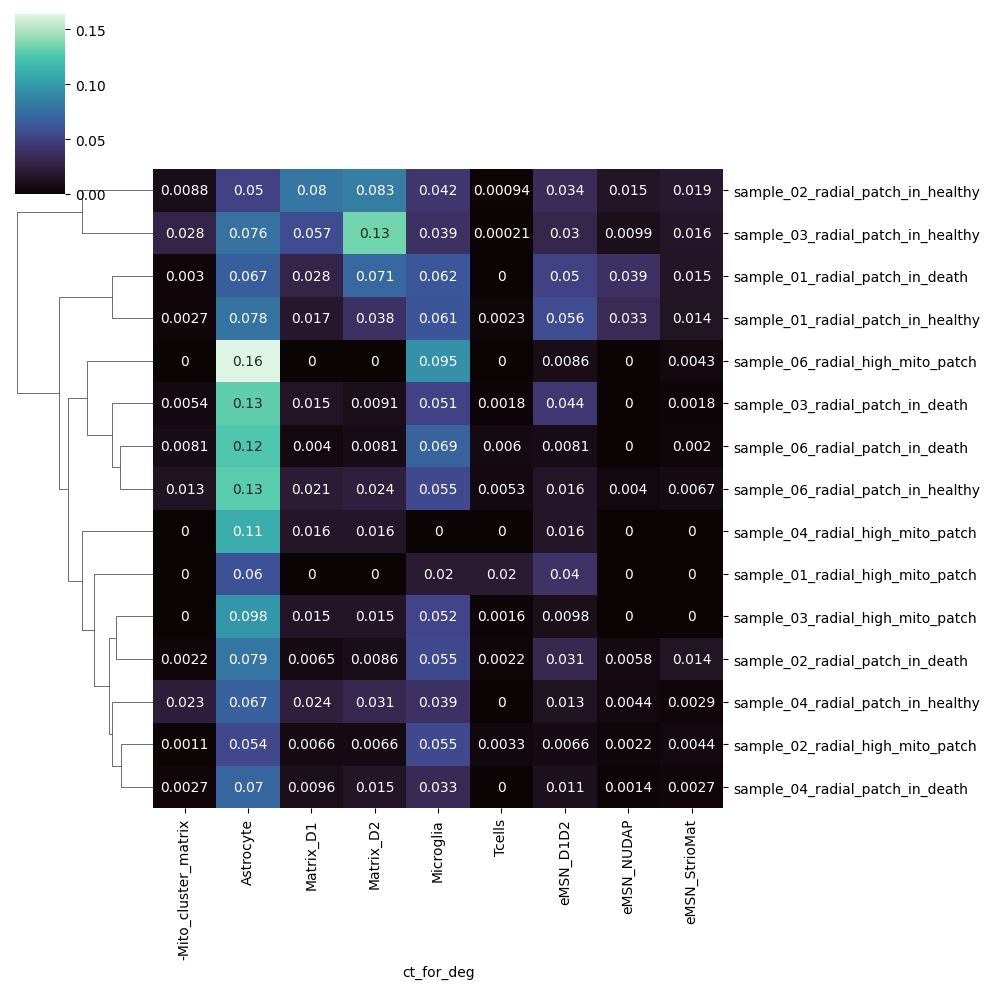

In [ ]:
# proportion of cells in neughborhoo

ct = pd.crosstab(
    index=[obs["sample"], obs["mito_radial_neighborhood"]], 
    columns=obs["ct_for_deg"], 
    normalize="index"
)
ct = ct.reset_index()
#ct = ct.drop(columns=["ct_for_deg"])
ct.index= ct["sample"].astype(str) + "_" + ct["mito_radial_neighborhood"].astype(str)
ct = ct.drop(columns=["sample", "mito_radial_neighborhood"])

current_index = ct.index.tolist()
sorted_index = sorted(current_index, key=lambda item: item[::-1])
ct = ct.reindex(sorted_index)

exclude = ["nan", "-Low_quality", "Patch_D1", "Patch_D2", "-Mito_cluster_patch", "-Mito_cluster_D1D2", "Macrophages", "ImAstro", "-TAFA1", "OT_D1_ICj"]
ct = ct.loc[:, ~ct.columns.isin(exclude)]

display(ct)

# Plot
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.legend(title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.title('Cell Type Composition by Sample/Neighborhood')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(ct, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Proportion of Cell Types per Group")
plt.show()

sns.clustermap(ct, cmap="mako", annot=True, col_cluster=False)

/tmp/ipykernel_439007/1780405420.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


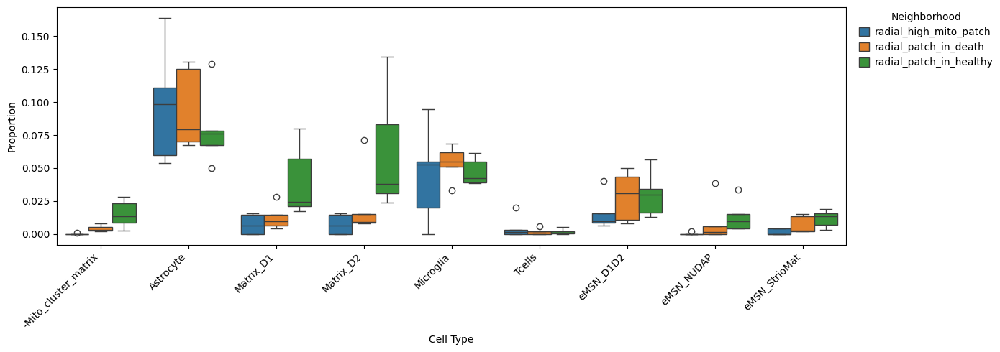

<Axes: xlabel='Cell Type', ylabel='Proportion'>

In [ ]:
ct["Neighborhood"] = ct.index.str.split("_").str[2:].str.join("_")

ct_long = ct.melt(
    id_vars="Neighborhood",
    var_name="cell_type",
    value_name="proportion"
)

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=ct_long, x="cell_type", y="proportion", hue="Neighborhood", ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_xlabel("Cell Type")
ax.set_ylabel("Proportion")
ax.legend(title="Neighborhood", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
sns.boxplot(data=ct_long, x="Neighborhood", y="proportion", hue="cell_type", ax=ax)

### Colocalization

In [ ]:
adata = sc.read_h5ad(ADATA_PATH)

SPATIAL_KEY="spatial"

In [ ]:
# CRITICAL: spatial graphs must be built per sample/image
# Otherwise cells from different slides get connected!
import squidpy as sq

nan_mask = np.isnan(adata.obsm[SPATIAL_KEY]).any(axis=1)
print(f"Dropping {nan_mask.sum()} cells with NaN spatial coordinates")
adata = adata[~nan_mask].copy()


adata = adata[
    (adata.obs["condition"] == "diseased") & 
    (adata.obs["region"] == "dead") 
].copy()

adata.obs["image_id"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
adata.obs["image_id"] = adata.obs["image_id"].astype("category")

Dropping 222438 cells with NaN spatial coordinates


In [ ]:
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].replace({"Patch_D1": "Patch", "Patch_D2": "Patch", "Matrix_D1": "Matrix", "Matrix_D2": "Matrix"})


/tmp/ipykernel_845413/272706820.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].replace({"Patch_D1": "Patch", "Patch_D2": "Patch", "Matrix_D1": "Matrix", "Matrix_D2": "Matrix"})


In [ ]:
cell_types_to_plot = ['Patch', 'Matrix', '-Mito_cluster_patch', "-Mito_cluster_matrix", "Microglia", "Astrocyte"]
adata = adata[adata.obs["ct_for_deg"].isin(cell_types_to_plot)].copy()

In [ ]:
adata_s = adata[adata.obs["sample"] == "sample_07"].copy()
print(adata_s)
sc.pl.embedding(adata_s, basis=SPATIAL_KEY, color=[CONTRAST_VARIABLE, SAMPLE_VARIABLE])
adata_s.uns.pop("ct_for_deg_colors")

cats = adata_s.obs[CONTRAST_VARIABLE].cat.categories.tolist()

palette = {cat: "lightgray" for cat in cats}
palette.update({"Patch": "blue", "Matrix": "green", "-Mito_cluster_patch": "red"})

sc.pl.embedding(
    adata_s, basis=SPATIAL_KEY,
    color=[CONTRAST_VARIABLE],
    groups=["Patch", "Matrix", "-Mito_cluster_patch"],
    palette=palette,
    size=30
)

AnnData object with n_obs × n_vars = 0 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'leiden_0.1_all_cells'

ZeroDivisionError: division by zero

Processing image: sample_01_puck2
AnnData object with n_obs × n_vars = 3830 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4

ct_for_deg
Matrix                  1439
Astrocyte               1228
Microglia                983
Patch                    138
-Mito_cluster_matrix      42
Name: count, dtype: int64

Processing image: sample_01_puck1
AnnData object with n_obs × n_vars = 2337 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4

ct_for_deg
Astrocyte               1085
Microglia                986
Patch                    180
Matrix                    76
-Mito_cluster_patch        6
-Mito_cluster_matrix       4
Name: count, dtype: int64

[26713.82315118 16000.38009746]
Median cell-cell distance: 122.9


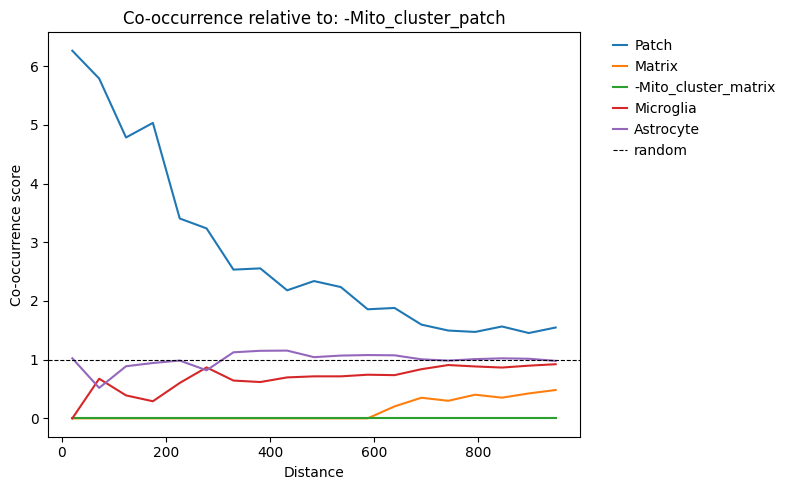

Processing image: sample_02_puck2
AnnData object with n_obs × n_vars = 1583 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4

ct_for_deg
Astrocyte               483
Microglia               472
Patch                   349
-Mito_cluster_patch     172
Matrix                  101
-Mito_cluster_matrix      6
Name: count, dtype: int64

[22101.08935165 16267.43226015]
Median cell-cell distance: 146.5


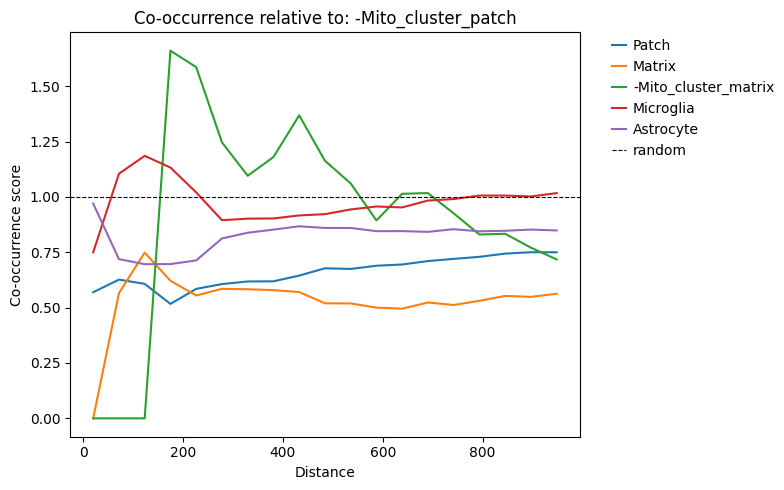

Processing image: sample_02_puck1
AnnData object with n_obs × n_vars = 699 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_

ct_for_deg
Patch                   203
Astrocyte               193
Microglia               138
-Mito_cluster_patch     100
Matrix                   62
-Mito_cluster_matrix      3
Name: count, dtype: int64

[22075.87357024 14902.49560402]
Median cell-cell distance: 179.6


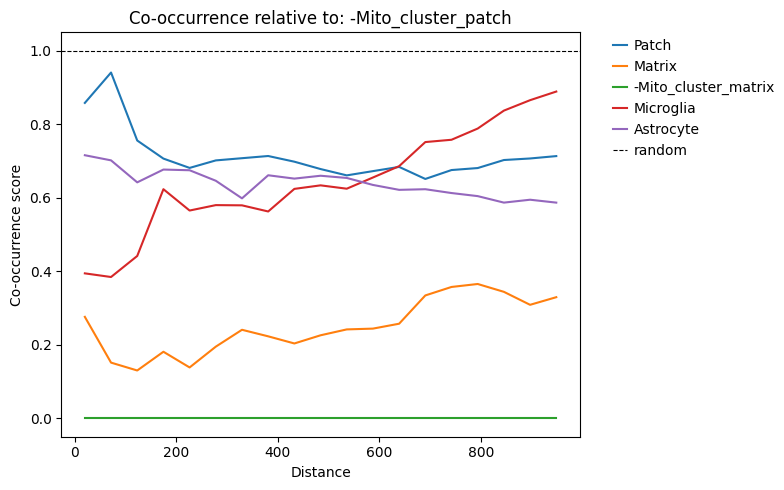

Processing image: sample_03_puck2
AnnData object with n_obs × n_vars = 453 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_

ct_for_deg
Astrocyte               211
Microglia                97
Patch                    68
-Mito_cluster_patch      48
Matrix                   26
-Mito_cluster_matrix      3
Name: count, dtype: int64

[16461.51790151  5198.65676027]
Median cell-cell distance: 70.6


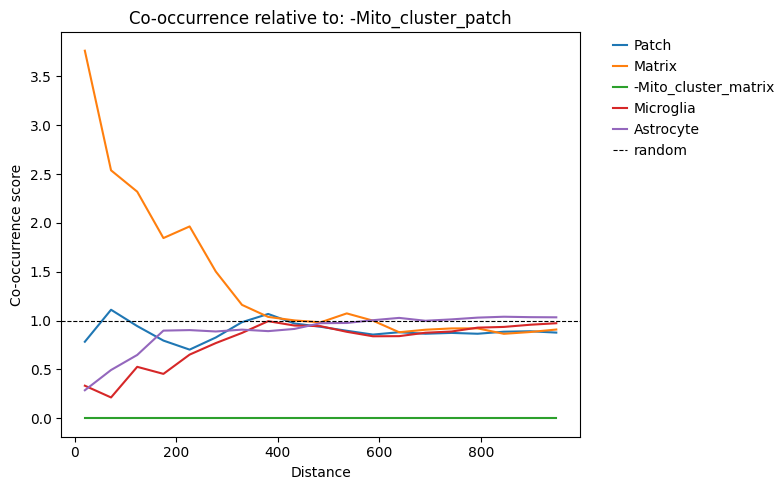

Processing image: sample_03_puck1
AnnData object with n_obs × n_vars = 1408 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4

ct_for_deg
Astrocyte               578
Microglia               420
Patch                   193
-Mito_cluster_patch     146
Matrix                   64
-Mito_cluster_matrix      7
Name: count, dtype: int64

[24637.42000243 16843.59811188]
Median cell-cell distance: 62.5


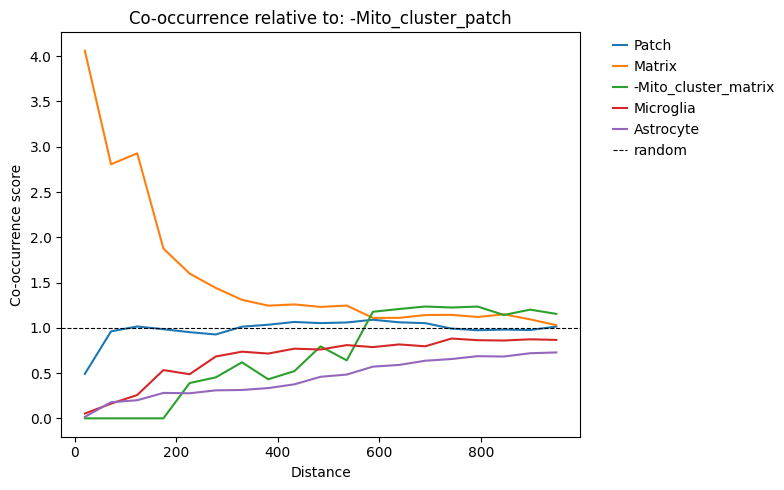

Processing image: sample_09_puck1
AnnData object with n_obs × n_vars = 1225 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4

ct_for_deg
Astrocyte               587
Microglia               410
Patch                   130
Matrix                   66
-Mito_cluster_patch      28
-Mito_cluster_matrix      4
Name: count, dtype: int64

[15719.62478471  2894.38373962]
Median cell-cell distance: 60.5


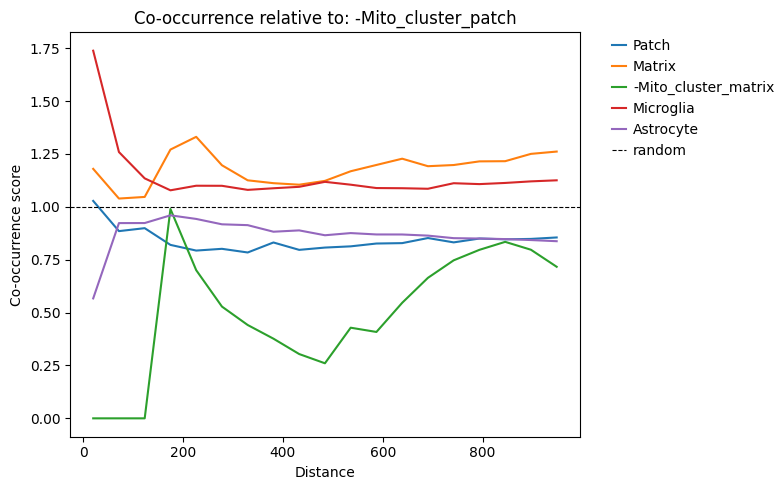

In [ ]:


# sq.gr.spatial_neighbors(
#     adata,
#     spatial_key='spatial', # obsm key 
#     library_key='image_id', # obs key that contsin images

#     coord_type="generic", # not visium
#     radius=None, # Only for 'generic'. If a float: connects all cells within that physical distance
#     delaunay=False, # Only for 'generic'. If True, connects cells via Delaunay triangulation 
#     percentile=None, # Only for 'generic'. Prunes edges longer than this percentile of all edge distance

#     transform=None, #How to weight the edges in the adjacency matrix. None = raw distances. 'spectral' = applies spectral normalization (good for diffusion-based analyses). 'cosine' = cosine similarity weighting
#     set_diag=False, # False)Whether to set the diagonal of the connectivity matrix to 1.0 (i.e., each cell is its own neighbor). Required by some downstream methods
    
#     key_added='spatial', #obsp
# )
# # WHAT GET ADDDED
# # adata.obsp['spatial_connectivities']  # sparse binary/weighted adjacency matrix
# # adata.obsp['spatial_distances']       # sparse matrix of physical distances per edge
# # adata.uns['spatial']                  # dict of parameters used

adatas = []
for img_id in adata.obs['image_id'].unique():

    print(f"Processing image: {img_id}")
    ad = adata[adata.obs['image_id'] == img_id].to_memory().copy()
    print(ad)

    sq.gr.co_occurrence(
        ad,
        cluster_key="ct_for_deg", # obs key with cell type annotations
        spatial_key=SPATIAL_KEY, #
            interval=np.linspace(20, 1000, 20),  # 50 bins from 0 to 5000 units, #If an int: creates 50 uniformly spaced distance bins from min to max coordinate range
        n_splits=None, #Splits the coordinate matrix into chunks to avoid building a massive N×N distance matrix that crashes RAM.
        n_jobs=None, # CPUs
        backend='loky',
        show_progress_bar=True
    )

    display(ad.obs["ct_for_deg"].value_counts())
    if "-Mito_cluster_patch" not in ad.obs["ct_for_deg"].unique():
        print(f"Warning: '-Mito_cluster_patch' not found in ct_for_deg for image {img_id}. Skipping co-occurrence plot.")
        continue

    # plot
    # sq.pl.co_occurrence(
    #     ad,
    #     cluster_key="ct_for_deg",
    #     clusters=["-Mito_cluster_patch"],  # which "cond" cell type to anchor on
    #     figsize=(10, 10)
    # );plt.show()

    import matplotlib.pyplot as plt
    import numpy as np

    # Check your coordinate scale
    print(ad.obsm[SPATIAL_KEY].max(axis=0) - ad.obsm[SPATIAL_KEY].min(axis=0))

    # Typical cell diameter in your data (median nearest-neighbor distance)
    from sklearn.neighbors import NearestNeighbors
    nn = NearestNeighbors(n_neighbors=2).fit(ad.obsm[SPATIAL_KEY])
    dists, _ = nn.kneighbors(ad.obsm[SPATIAL_KEY])
    print(f"Median cell-cell distance: {np.median(dists[:,1]):.1f}")
    

    # Cell types you actually want to see as lines

    anchor = "-Mito_cluster_patch"

    # Pull out the co-occurrence results stored in uns
    occ = ad.uns["ct_for_deg_co_occurrence"]   # shape: (n_clusters, n_clusters, n_intervals)
    categories = ad.obs["ct_for_deg"].cat.categories.tolist()
    interval = occ["interval"]        # distance bins
    scores = occ["occ"]               # (n_clusters, n_clusters, n_bins)

    anchor_idx = categories.index(anchor)

    fig, ax = plt.subplots(figsize=(8, 5))

    for ct in cell_types_to_plot:
        if ct == anchor:
            continue
        ct_idx = categories.index(ct)
        ax.plot(interval[:-1], scores[anchor_idx, ct_idx], label=ct)

    ax.axhline(1, color="black", linestyle="--", linewidth=0.8, label="random")
    ax.set_xlabel("Distance")
    ax.set_ylabel("Co-occurrence score")
    ax.set_title(f"Co-occurrence relative to: {anchor}")
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    adatas.append(ad)

    #break

  0%|          | 0/1000 [00:00<?, ?/s]

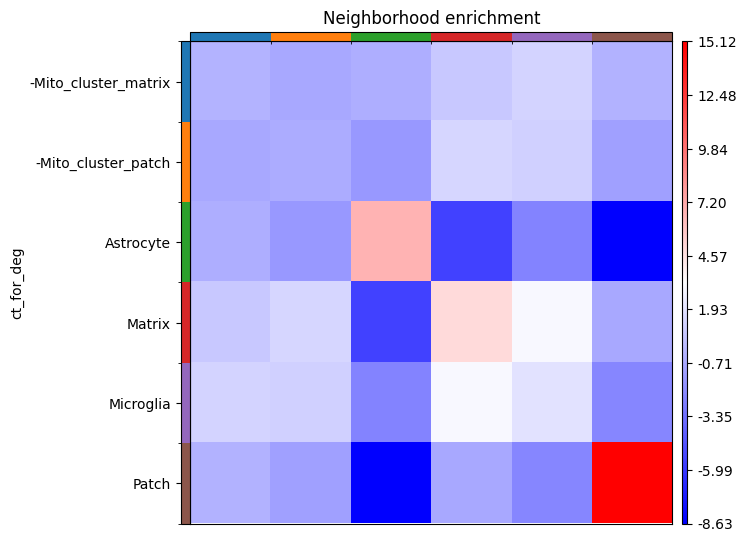

In [ ]:
sq.gr.spatial_neighbors(ad, spatial_key='spatial', coord_type='generic', delaunay=True)
sq.gr.nhood_enrichment(ad, cluster_key='ct_for_deg')
sq.pl.nhood_enrichment(ad, cluster_key='ct_for_deg', figsize=(6,5), cmap="bwr"); plt.show()

# Mito_pct correlated genes

In [ ]:
CELL_TYPE_TO_USE = "bican_Patch" # 
# bican_Patch, bican_Matrix, bican_D1D2, bican_Astro
# nucseq_Patch_healthy,  nucseq_Matrix_healthy, nucseq_D1D2_healthy, nucseq_Astro_healthy, nucseq_non-MSN_healthy
# ventral_slidetag_diseased_Patch, ventral_slidetag_diseased_Astro

if CELL_TYPE_TO_USE == "bican_Patch":
    # d1_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STRd_D1_Striosome_MSN_4_zones.h5ad")
    # d2_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STRd_D2_Striosome_MSN_4_zones.h5ad")

    d1_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/BICAN/STR_D1_Striosome_MSN.h5ad")
    d2_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/BICAN/STR_D2_Striosome_MSN.h5ad")

    strio_bican = sc.concat([d1_strio_bican, d2_strio_bican], axis=0)

elif CELL_TYPE_TO_USE == "bican_Matrix":
    d1_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STR_D1_Matrix_MSN.h5ad")
    d2_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STR_D2_Matrix_MSN.h5ad")
    strio_bican = sc.concat([d1_strio_bican, d2_strio_bican], axis=0)
elif CELL_TYPE_TO_USE == "bican_D1D2":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STR_D1D2_Hybrid_MSN_4_zones.h5ad")
elif CELL_TYPE_TO_USE == "bican_Astro":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/Astrocyte_4_zones.h5ad")

elif CELL_TYPE_TO_USE == "nucseq_Patch_healthy":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
    strio_bican = strio_bican[(strio_bican.obs["ct_for_deg"].isin(["Patch_D1", "Patch_D2"])) & (strio_bican.obs["condition"]=="Control")].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
elif CELL_TYPE_TO_USE == "nucseq_Matrix_healthy":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
    strio_bican = strio_bican[(strio_bican.obs["ct_for_deg"].isin(["Matrix_D1", "Matrix_D2"])) & (strio_bican.obs["condition"]=="Control")].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
elif CELL_TYPE_TO_USE == "nucseq_D1D2_healthy":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
    strio_bican = strio_bican[(strio_bican.obs["ct_for_deg"].isin(["eMSN_D1D2"])) & (strio_bican.obs["condition"]=="Control")].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
elif CELL_TYPE_TO_USE == "nucseq_Astro_healthy":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
    strio_bican = strio_bican[(strio_bican.obs["ct_for_deg"].isin(["Astrocyte"])) & (strio_bican.obs["condition"]=="Control")].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
elif CELL_TYPE_TO_USE == "nucseq_non-MSN_healthy":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad", backed="r")
    strio_bican = strio_bican[(strio_bican.obs["ct_for_deg"].isin(["non-MSN"])) & (strio_bican.obs["condition"]=="Control")].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)

elif CELL_TYPE_TO_USE == "ventral_slidetag_diseased_Patch":
    adata = sc.read_h5ad(ADATA_PATH, backed="r")
    strio_bican = adata[
                        (adata.obs["ct_for_deg"].isin(["Patch_D1", "Patch_D2"])) & 
                        (adata.obs["condition"]=="diseased") &
                        (adata.obs["region"] == "healthy")
                        ].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
    strio_bican.var_names_make_unique()

elif CELL_TYPE_TO_USE == "ventral_slidetag_diseased_Astro":
    adata = sc.read_h5ad(ADATA_PATH, backed="r")
    strio_bican = adata[
                        (adata.obs["ct_for_deg"].isin(["Astrocyte"])) &
                        (adata.obs["condition"]=="diseased") &
                        (adata.obs["region"] == "healthy")
                        ].to_memory().copy()
    strio_bican.var.index = strio_bican.var["gene_symbol"].astype(str)
    strio_bican.var_names_make_unique()


display(strio_bican)
strio_bican.X[:100, :100].toarray().sum(axis=1)

AnnData object with n_obs × n_vars = 204480 × 32695
    obs: 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'frac_contamination', 'donor_external_id', 'biobank', 'age', 'pmi_hr', 'imputed_sex', 'toxicology_report_complete', 'mmc_neighborhood_name', 'mmc_neighborhood_bootstrapping_probability', 'mmc_class_name', 'mmc_class_bootstrapping_probability', 'mmc_subclass_name', 'mmc_subclass_bootstrapping_probability', 'mmc_group_name', 'mmc_group_bootstrapping_probability', 'mmc_cluster_name', 'mmc_cluster_bootstrapping_probability', 'neuropath_diagnosis', 'village', 'brain_region_abbreviation', 'is_primary_data', 'donor_id', 'n_counts', 'zone', 'zone_probs'

array([835., 918., 640., 647., 738., 759., 832., 609., 279., 650., 317.,
       805., 644., 605., 642., 835., 648., 675., 800., 676., 877., 621.,
       807., 552., 756., 636., 370., 264., 542., 430., 343., 432., 446.,
       325., 432., 324., 425., 396., 353., 390., 361., 337., 331., 166.,
       343., 329., 465., 460., 413., 547., 328., 461., 483., 332., 312.,
       445., 406., 414., 286., 361., 407., 316., 283., 326., 380., 332.,
       321., 459., 537., 575., 365., 432., 441., 451., 414., 533., 389.,
       331., 588., 453., 409., 448., 519., 462., 245., 313., 433., 542.,
       374., 462., 513., 373., 513., 551., 358., 474., 638., 372., 407.,
       389.])

In [ ]:
df_obs = pd.read_csv("/home/gdallagl/myworkdir/XDP/data/BICAN/bican_metadata.csv", index_col=0)
df_obs.drop_duplicates(subset=["donor_id"], inplace=True)
df_obs.set_index("donor_id", inplace=True)
df_obs = df_obs[["age"]]
df_obs

,age
donor_id,
MD6366,31
MD6417,46
MD6424,55
MD6429,27
MD6432,28
...,...
MS216919,72
MS5423,90
UMBEB23158,59


AnnData object with n_obs × n_vars = 204480 × 32695
    obs: 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'frac_contamination', 'donor_external_id', 'biobank', 'age', 'pmi_hr', 'imputed_sex', 'toxicology_report_complete', 'mmc_neighborhood_name', 'mmc_neighborhood_bootstrapping_probability', 'mmc_class_name', 'mmc_class_bootstrapping_probability', 'mmc_subclass_name', 'mmc_subclass_bootstrapping_probability', 'mmc_group_name', 'mmc_group_bootstrapping_probability', 'mmc_cluster_name', 'mmc_cluster_bootstrapping_probability', 'neuropath_diagnosis', 'village', 'brain_region_abbreviation', 'is_primary_data', 'donor_id', 'n_counts', 'zone', 'zone_probs', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.1subset',

INFO: Seed set to 42
2026-05-12 12:17:41 | [INFO] Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-05-12 12:20:54,101 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-05-12 12:20:54 | [INFO] Running Harmony (PyTorch on cuda)
2026-05-12 12:20:54,103 - harmonypy - INFO -   Parameters:
2026-05-12 12:20:54 | [INFO]   Parameters:
2026-05-12 12:20:54,104 - harmonypy - INFO -     max_iter_harmony: 30
2026-05-12 12:20:54 | [INFO]     max_iter_harmony: 30
2026-05-12 12:20:54,105 - harmonypy - INFO -     max_iter_kmeans: 20
2026-05-12 12:20:54 | [INFO]     max_iter_kmeans: 20
2026-05-12 12:20:54,105 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-05-12 12:20:54 | [INFO]     epsilon_cluster: 1e-05
2026-05-12 12:20:54,106 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-05-12 12:20:54 | [INFO]     epsilon_harmony: 0.0001
2026-05-12 12:20:54,107 - harmonypy - INFO -     nclust: 100
2026-05-12 12:20:54 | [INFO]     nclust: 100
2026-05-12 12:20:54,108 - harmonypy - INFO -     block_size: 0.05
2026-05-12 12:20:54 | [INFO]     block_size: 0.05
2026-05-12 12:20:54,110 - harm

Running Harmony batch correction...


2026-05-12 12:20:54,825 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-05-12 12:20:54 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-05-12 12:20:58,977 - harmonypy - INFO - KMeans initialization complete.
2026-05-12 12:20:58 | [INFO] KMeans initialization complete.
2026-05-12 12:20:59,236 - harmonypy - INFO - Iteration 1 of 30
2026-05-12 12:20:59 | [INFO] Iteration 1 of 30
2026-05-12 12:21:04,649 - harmonypy - INFO - Iteration 2 of 30
2026-05-12 12:21:04 | [INFO] Iteration 2 of 30
2026-05-12 12:21:09,756 - harmonypy - INFO - Iteration 3 of 30
2026-05-12 12:21:09 | [INFO] Iteration 3 of 30
2026-05-12 12:21:14,862 - harmonypy - INFO - Iteration 4 of 30
2026-05-12 12:21:14 | [INFO] Iteration 4 of 30
2026-05-12 12:21:19,991 - harmonypy - INFO - Iteration 5 of 30
2026-05-12 12:21:19 | [INFO] Iteration 5 of 30
2026-05-12 12:21:24,580 - harmonypy - INFO - Iteration 6 of 30
2026-05-12 12:21:24 | [INFO] Iteration 6 of 30
2026-05-12 12:21:28,090 - 

Z_corr shape: (204480, 50), n_obs: 204480
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...
0 cells with missing age
[2/6] Backed up raw counts
[3/6] Normalized total counts (target_sum=1e4)
[4/6] Applied log1p transformation
[5/6] Saved log1p layer, restored raw counts in .X
13


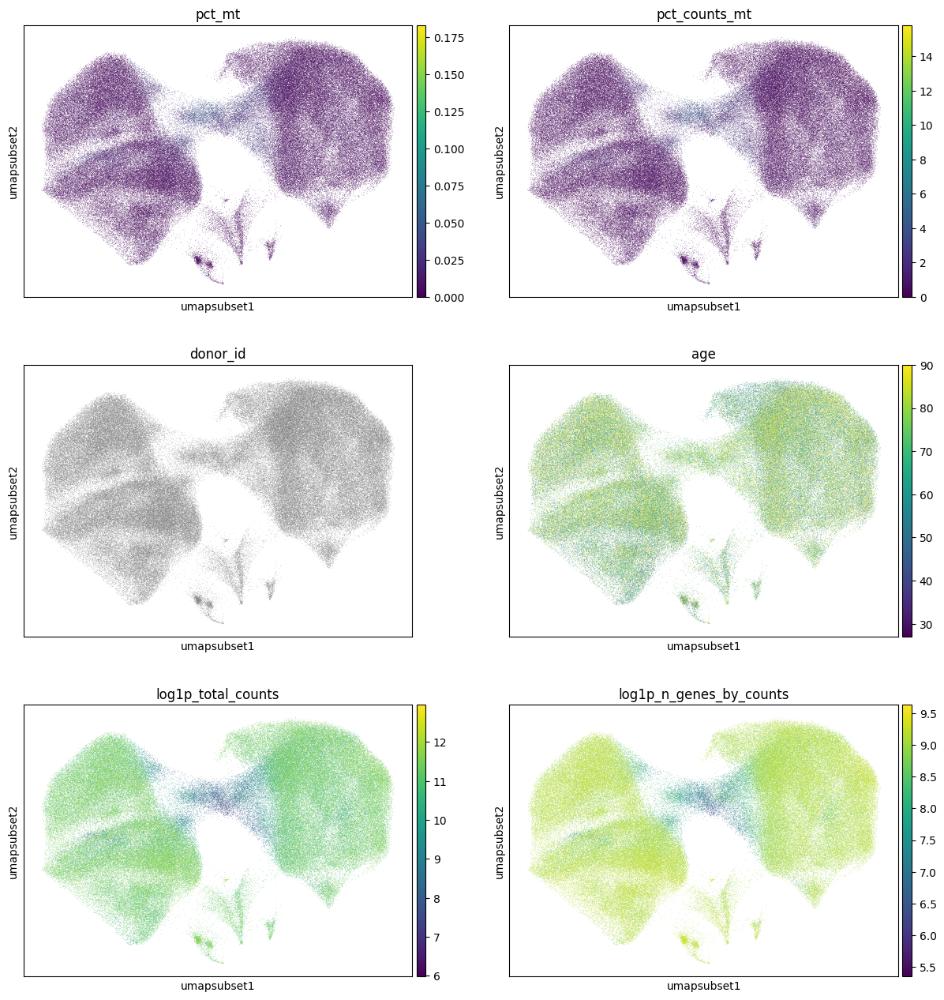

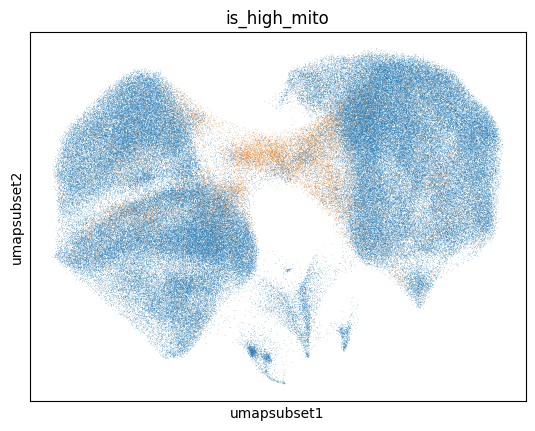

In [ ]:
NAME="subset"
from utils import label_mapping_utils as lmu

strio_bican.layers["counts"] = strio_bican.X.copy()
leiden_cluster_names = lmu.preprocess_common_pipeline(strio_bican, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key="donor_id")

if "age" not in strio_bican.obs.columns:
    strio_bican.obs = strio_bican.obs.merge(
        df_obs,
        left_on="donor_id",
        right_index=True,
        how="left"   # keeps all cells even if no matching donor_id
    )
print(strio_bican.obs["age"].isna().sum(), "cells with missing age")

strio_bican.layers["counts"] = strio_bican.X.copy()
print(f"[2/6] Backed up raw counts")
sc.pp.normalize_total(strio_bican, target_sum=1e4)
print(f"[3/6] Normalized total counts (target_sum=1e4)")
sc.pp.log1p(strio_bican)
print(f"[4/6] Applied log1p transformation")
strio_bican.layers["log1p_norm"] = strio_bican.X.copy()
strio_bican.X = strio_bican.layers["counts"]
print(f"[5/6] Saved log1p layer, restored raw counts in .X")

# marc mito genes
strio_bican.var["mt"] = strio_bican.var_names.str.startswith(("MT-", "mt-"))
print(strio_bican.var["mt"].sum())
# calculte Mt pct
sc.pp.calculate_qc_metrics(strio_bican, qc_vars=['mt'], inplace=True)

strio_bican = strio_bican[strio_bican.obs["donor_id"] != 'nan'].copy()
strio_bican = strio_bican[strio_bican.obs["age"].notna()].copy()


sc.pl.embedding(strio_bican, basis=F"umap{NAME}", color=["pct_mt", "pct_counts_mt", "donor_id", "age", "log1p_total_counts", "log1p_n_genes_by_counts"], ncols=2, legend_loc=None)
strio_bican.obs["is_high_mito"] = strio_bican.obs["pct_counts_mt"] > 1
sc.pl.embedding(strio_bican, basis=F"umap{NAME}", color=["is_high_mito"], ncols=2, legend_loc=None)





In [ ]:
from scipy.stats import spearmanr
import numpy as np

gene = "ZNF91"
gene_idx = list(strio_bican.var_names).index(gene)
gene_expr = strio_bican.layers["log1p_norm"][:, gene_idx].toarray().flatten()
pct_mito  = strio_bican.obs["pct_counts_mt"].values
samples   = strio_bican.obs["donor_id"].values

# Order samples by age
sample_age = (
    strio_bican.obs[["donor_id", "age"]]
    .drop_duplicates("donor_id")
    .set_index("donor_id")["age"]
)
unique_samples = sample_age.sort_values().index.values  # sorted by age

n_cols = 6
n_rows = int(np.ceil(len(unique_samples) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, sample in zip(axes, unique_samples):
    mask = samples == sample
    x = pct_mito[mask]
    y = gene_expr[mask]

    rho, pval = spearmanr(x, y)

    ax.scatter(x, y, s=5, alpha=0.3, rasterized=True)

    # fit and plot regression line
    m, b = np.polyfit(x, y, deg=1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, m * x_line + b, color="red", linewidth=1.5)

    age = sample_age[sample]
    ax.set_title(f"{sample}  (age {age})\nρ = {rho:.3f}  (p = {pval:.2e})", fontsize=9)
    ax.set_xlabel("% mito counts")
    ax.set_ylabel(f"{gene} log1p expr")

for ax in axes[len(unique_samples):]:
    ax.set_visible(False)

fig.suptitle(f"{gene} expression vs % mito — per sample, ordered by age ({CELL_TYPE_TO_USE})", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
strio_bican.obsm["spatial"] = np.array(strio_bican.obs[["x", "y"]])

sample_age = (
    strio_bican.obs[["donor_id", "age"]]
    .drop_duplicates("donor_id")
    .set_index("donor_id")["age"]
)
unique_samples = sample_age.sort_values().index.values  # ordered by age

n_cols = 6
n_rows = int(np.ceil(len(unique_samples) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()

for ax, sample in zip(axes, unique_samples):
    adata_sample = strio_bican[strio_bican.obs["donor_id"] == sample].copy()
    age = sample_age[sample]
    sc.pl.embedding(
        adata_sample,
        basis="spatial",
        color="pct_counts_mt",
        title=f"{sample}  (age {age})",
        ax=ax,
        show=False,
        color_map="Reds",
        vmin=0,
        vmax=3
    )

for ax in axes[len(unique_samples):]:
    ax.set_visible(False)

fig.suptitle(f"% mito — spatial, ordered by age ({CELL_TYPE_TO_USE})", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

KeyError: "None of [Index(['x', 'y'], dtype='object')] are in the [columns]"

In [ ]:
# marc mito genes
strio_bican.var["mt"] = strio_bican.var_names.str.startswith(("MT-", "mt-"))
print(strio_bican.var["mt"].sum())

# calculte Mt pct
sc.pp.calculate_qc_metrics(strio_bican, qc_vars=['mt'], inplace=True)

13


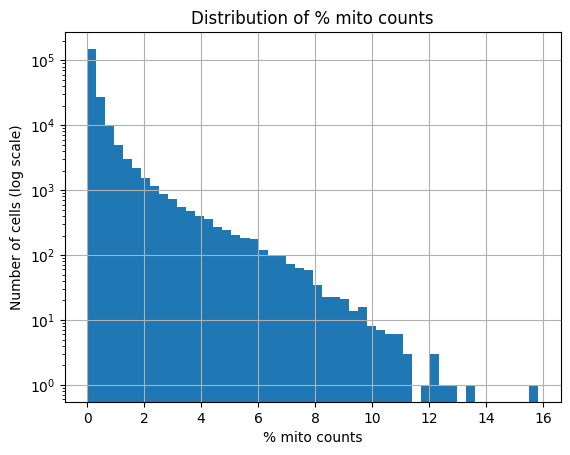

In [ ]:
strio_bican.obs["pct_counts_mt"].hist(bins=50); plt.yscale("log"); plt.title("Distribution of % mito counts"); plt.xlabel("% mito counts"); plt.ylabel("Number of cells (log scale)"); plt.show()

In [ ]:
# remvoe not interesting genes
ensg_genes = strio_bican.var_names.str.startswith("ENSG")
print(ensg_genes.sum())

strio_bican = strio_bican[:, ~ensg_genes].copy()
print(strio_bican)

#strio_bican.obs.groupby(["donor_id"]).size().sort_values().head(10)

10133


AnnData object with n_obs × n_vars = 204480 × 22562
    obs: 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'frac_contamination', 'donor_external_id', 'biobank', 'age', 'pmi_hr', 'imputed_sex', 'toxicology_report_complete', 'mmc_neighborhood_name', 'mmc_neighborhood_bootstrapping_probability', 'mmc_class_name', 'mmc_class_bootstrapping_probability', 'mmc_subclass_name', 'mmc_subclass_bootstrapping_probability', 'mmc_group_name', 'mmc_group_bootstrapping_probability', 'mmc_cluster_name', 'mmc_cluster_bootstrapping_probability', 'neuropath_diagnosis', 'village', 'brain_region_abbreviation', 'is_primary_data', 'donor_id', 'n_counts', 'zone', 'zone_probs', 'leiden_0.1subset', 'leiden_0.5subset', 'leiden_1.0subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', '

In [ ]:
display(strio_bican)
strio_bican = strio_bican[strio_bican.obs["donor_id"] != 'nan'].copy()
# strio_bican = strio_bican[strio_bican.obs["pct_counts_mt"] < 3].copy()
display(strio_bican)


AnnData object with n_obs × n_vars = 204480 × 22562
    obs: 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'frac_contamination', 'donor_external_id', 'biobank', 'age', 'pmi_hr', 'imputed_sex', 'toxicology_report_complete', 'mmc_neighborhood_name', 'mmc_neighborhood_bootstrapping_probability', 'mmc_class_name', 'mmc_class_bootstrapping_probability', 'mmc_subclass_name', 'mmc_subclass_bootstrapping_probability', 'mmc_group_name', 'mmc_group_bootstrapping_probability', 'mmc_cluster_name', 'mmc_cluster_bootstrapping_probability', 'neuropath_diagnosis', 'village', 'brain_region_abbreviation', 'is_primary_data', 'donor_id', 'n_counts', 'zone', 'zone_probs', 'leiden_0.1subset', 'leiden_0.5subset', 'leiden_1.0subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', '

AnnData object with n_obs × n_vars = 204480 × 22562
    obs: 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'frac_contamination', 'donor_external_id', 'biobank', 'age', 'pmi_hr', 'imputed_sex', 'toxicology_report_complete', 'mmc_neighborhood_name', 'mmc_neighborhood_bootstrapping_probability', 'mmc_class_name', 'mmc_class_bootstrapping_probability', 'mmc_subclass_name', 'mmc_subclass_bootstrapping_probability', 'mmc_group_name', 'mmc_group_bootstrapping_probability', 'mmc_cluster_name', 'mmc_cluster_bootstrapping_probability', 'neuropath_diagnosis', 'village', 'brain_region_abbreviation', 'is_primary_data', 'donor_id', 'n_counts', 'zone', 'zone_probs', 'leiden_0.1subset', 'leiden_0.5subset', 'leiden_1.0subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', '

/tmp/ipykernel_1013913/855638795.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rho_per_donor = df_plot.groupby("donor_id").apply(
/tmp/ipykernel_1013913/855638795.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rho_per_donor = df_plot.groupby("donor_id").apply(


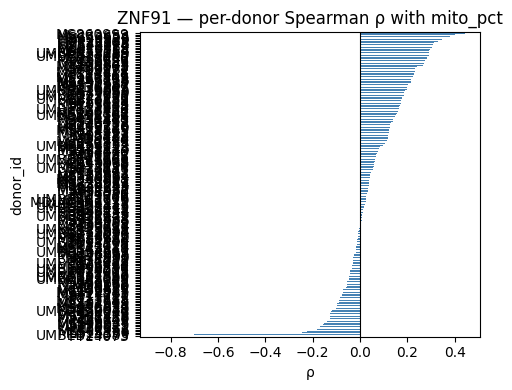




In [ ]:
from scipy.stats import spearmanr

GENE = "ZNF91"

strio_bican.layers["counts"] = strio_bican.X.copy()
sc.pp.normalize_total(strio_bican, target_sum=1e4)
sc.pp.log1p(strio_bican)

gene_expr_raw = strio_bican[:, GENE].X
expr = gene_expr_raw.toarray().flatten() if hasattr(gene_expr_raw, "toarray") else np.asarray(gene_expr_raw).flatten()

df_plot = strio_bican.obs[["pct_counts_mt", "donor_id"]].copy()
df_plot[GENE] = expr

rho_per_donor = df_plot.groupby("donor_id").apply(
    lambda g: spearmanr(g["pct_counts_mt"], g[GENE]).statistic
)

rho_per_donor.sort_values().plot(kind="barh", figsize=(5, 4), color="steelblue")
plt.axvline(0, color="k", lw=0.8)
plt.title(f"{GENE} — per-donor Spearman ρ with mito_pct")
plt.xlabel("ρ")
plt.tight_layout()
plt.show()

def regplot_with_rho(data, x, y, **kwargs):
    ax = plt.gca()
    donor = data["donor_id"].iloc[0]
    rho = rho_per_donor[donor]
    sns.regplot(data=data, x=x, y=y, ax=ax,
                scatter_kws={"s": 5, "alpha": 0.4}, line_kws={"color": "red"})
    ax.annotate(f"ρ = {rho:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                fontsize=9, color="red", fontweight="bold")

g = sns.FacetGrid(df_plot, col="donor_id", col_wrap=4, height=3)
g.map_dataframe(regplot_with_rho, x="pct_counts_mt", y=GENE)
g.set_axis_labels("% mito", f"{GENE} (log1p)")
g.set_titles(col_template="{col_name}")
plt.suptitle(f"{GENE} vs mito fraction per sample", y=1.01)
plt.tight_layout()
plt.show()

strio_bican.X = strio_bican.layers["counts"].copy()


In [ ]:
strio_bican.obs["sample"].unique()

KeyError: 'sample'

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from joblib import Parallel, delayed


from scipy.stats import spearmanr, combine_pvalues

SAMPLE_COL = "donor_id" #"sample" #"donor_id"  # ← adjust to your obs column name

save_df_corr_path = f"/home/gdallagl/myworkdir/XDP/data/_old/corr_mito_genes/mito_corr_genes_{CELL_TYPE_TO_USE}.csv"

if not os.path.exists(save_df_corr_path):
    n_cells, n_genes = strio_bican.shape
    print(f"[1/6] Starting preprocessing — {n_cells} cells × {n_genes} genes")

    strio_bican.layers["counts"] = strio_bican.X.copy()
    print(f"[2/6] Backed up raw counts")

    sc.pp.normalize_total(strio_bican, target_sum=1e4)
    print(f"[3/6] Normalized total counts (target_sum=1e4)")

    sc.pp.log1p(strio_bican)
    print(f"[4/6] Applied log1p transformation")

    strio_bican.layers["log1p_norm"] = strio_bican.X.copy()
    strio_bican.X = strio_bican.layers["counts"]
    print(f"[5/6] Saved log1p layer, restored raw counts in .X")

    X = strio_bican.layers["log1p_norm"].toarray()
    frac_mito = strio_bican.obs["pct_counts_mt"].values
    sample_labels = strio_bican.obs[SAMPLE_COL].values
    samples = np.unique(sample_labels)

    n_jobs = 48
    chunks = np.array_split(range(n_genes), n_jobs)

    def corr_gene_chunk(gene_indices, X_s, frac_mito_s):
        return [spearmanr(X_s[:, i], frac_mito_s) for i in gene_indices]

    print(f"[6/6] Computing per-sample Spearman correlations across {len(samples)} samples × {n_genes} genes...")

    all_rhos  = np.full((len(samples), n_genes), np.nan)   # (n_samples, n_genes)
    all_pvals = np.full((len(samples), n_genes), np.nan)

    for s_idx, sample in enumerate(samples):
        mask = sample_labels == sample
        n_cells_s = mask.sum()
        print(f"  Sample {s_idx+1}/{len(samples)}: {sample!r}  ({n_cells_s} cells)")

        X_s         = X[mask]
        frac_mito_s = frac_mito[mask]

        results_chunked = Parallel(n_jobs=n_jobs, verbose=0)(
            delayed(corr_gene_chunk)(chunk, X_s, frac_mito_s) for chunk in chunks
        )
        results = [r for chunk in results_chunked for r in chunk]
        rhos_s, pvals_s = zip(*results)

        all_rhos[s_idx]  = rhos_s
        all_pvals[s_idx] = pvals_s

    # Average rho across samples (Fisher z-transform → average → back-transform
    # is more principled than a raw mean, but raw mean is kept below for simplicity;
    # swap to the z-transform block if you prefer)
    rhos = np.nanmean(all_rhos, axis=0)

    # Combine per-sample p-values with Fisher's method (robust to different sample sizes)
    pvals = np.array([
        combine_pvalues(all_pvals[:, i][~np.isnan(all_pvals[:, i])], method="fisher")[1]
        for i in range(n_genes)
    ])
    print(f"      ✓ Done — averaged rho and combined p-values across {len(samples)} samples")

    df_corr = pd.DataFrame({
        "gene":    strio_bican.var_names,
        "rho":     rhos,
        "pval":    pvals,
        "pval_bh": pvals   # placeholder
    }, index=strio_bican.var_names)

    _, pval_bh, _, _ = multipletests(df_corr["pval"], method="fdr_bh")
    df_corr["pval_bh"] = pval_bh
    print(f"      ✓ BH correction applied")

    df_corr = df_corr.sort_values("rho", key=abs, ascending=False)
    df_corr.to_csv(save_df_corr_path, index=False)
    print(f"      ✓ Saved to {save_df_corr_path}")

else:
    print(f"Correlation results already exist at {save_df_corr_path}, skipping computation.")

df_corr = pd.read_csv(save_df_corr_path, index_col="gene")

if "age" in strio_bican.obs.columns:
    new_row = pd.DataFrame([{
        "rho": strio_bican.obs["age"].corr(
            strio_bican.obs["pct_counts_mt"], method="spearman"
        ),
        "pval": float("nan"),
        "pval_bh": float("nan")
    }], index=["corr_age"])
    new_row.index.name = "gene"
    df_corr = pd.concat([df_corr, new_row])
    print(f"Added age correlation row")

df_corr

[1/6] Starting preprocessing — 204480 cells × 22562 genes
[2/6] Backed up raw counts
[3/6] Normalized total counts (target_sum=1e4)
[4/6] Applied log1p transformation
[5/6] Saved log1p layer, restored raw counts in .X
[6/6] Computing per-sample Spearman correlations across 190 samples × 22562 genes...
  Sample 1/190: 'MD6366'  (1291 cells)


/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: 

  Sample 2/190: 'MD6417'  (270 cells)


/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: 

  Sample 3/190: 'MD6424'  (633 cells)


/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: 

... (370 outputs left out)

  Sample 190/190: 'UMBEB24130'  (3006 cells)


/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
/tmp/ipykernel_1013913/929765049.py:40: ConstantInputWarning: 

      ✓ Done — averaged rho and combined p-values across 190 samples
      ✓ BH correction applied
      ✓ Saved to /home/gdallagl/myworkdir/XDP/data/_old/corr_mito_genes/mito_corr_genes_bican_Patch.csv
Added age correlation row


,rho,pval,pval_bh
gene,,,
MT-CO3,0.926298,0.000000e+00,0.000000e+00
MT-CO1,0.891081,0.000000e+00,0.000000e+00
MT-ND4,0.887264,0.000000e+00,0.000000e+00
MT-CO2,0.878906,0.000000e+00,0.000000e+00
MT-ATP6,0.873425,0.000000e+00,0.000000e+00
...,...,...,...
RSRP1,0.000013,3.576666e-279,8.867773e-279
CENATAC,-0.000010,5.013753e-209,1.072129e-208
STMN2,0.000009,0.000000e+00,0.000000e+00


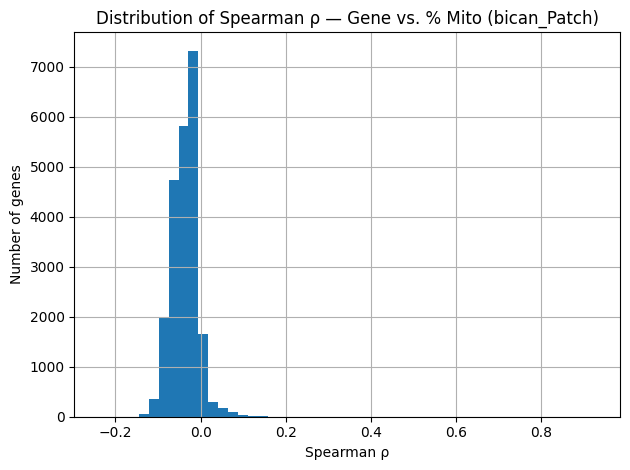

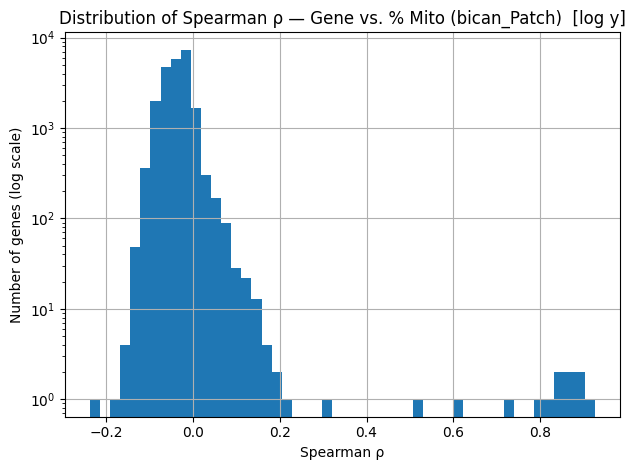

,rho,pval,pval_bh
gene,,,
MT-CO3,0.926298,0.0,0.0
MT-CO1,0.891081,0.0,0.0
MT-ND4,0.887264,0.0,0.0
MT-CO2,0.878906,0.0,0.0
MT-ATP6,0.873425,0.0,0.0
MT-ND2,0.855253,0.0,0.0
MT-CYB,0.854635,0.0,0.0
MT-ND1,0.818894,0.0,0.0
MT-ND3,0.787523,0.0,0.0


,rho,pval,pval_bh
gene,,,
MT-ATP8,0.315746,0.0,0.0
GNG7,0.212602,0.0,0.0


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
df_corr["rho"].hist(bins=50, ax=ax)
ax.set_title(f"Distribution of Spearman ρ — Gene vs. % Mito ({CELL_TYPE_TO_USE})")
ax.set_xlabel("Spearman ρ")
ax.set_ylabel("Number of genes")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
df_corr["rho"].hist(bins=50, ax=ax)
ax.set_yscale("log")
ax.set_title(f"Distribution of Spearman ρ — Gene vs. % Mito ({CELL_TYPE_TO_USE})  [log y]")
ax.set_xlabel("Spearman ρ")
ax.set_ylabel("Number of genes (log scale)")
plt.tight_layout()
plt.show()

display(df_corr[df_corr["rho"] > 0.4])
display(df_corr[(df_corr["rho"] > 0.2) & (df_corr["rho"] <= 0.4)].head(20))



In [ ]:
dfs = []

for file in os.listdir(os.path.dirname(save_df_corr_path)):
    if "mito_corr_genes_" not in file:   # skip unrelated files
        continue
    file_name = os.path.splitext(file)[0].split("mito_corr_genes_")[1]
    print(f"Processing {file_name}...")
    df = pd.read_csv(os.path.join(os.path.dirname(save_df_corr_path), file), index_col="gene")
    print(df.index[df.index.duplicated()].tolist())
    df.columns = [f"{col}_{file_name}" for col in df.columns]  # avoid column name collisions
    dfs.append(df)

merged_df = pd.concat(dfs, axis=1)
display(merged_df)

Processing bican_Patch...
[]
Processing ventral_slidetag_diseased_Patch...
[]
Processing nucseq_Matrix_healthy...
[]
Processing nucseq_D1D2_healthy...
[]
Processing bican_Astro...
[]
Processing nucseq_non-MSN_healthy...
[]
Processing bican_D1D2...
[]
Processing nucseq_Patch_healthy...
[]
Processing nucseq_Astro_healthy...
[]
Processing ventral_slidetag_diseased_Astro...
[]
Processing bican_Matrix...
[]


,rho_bican_Patch,pval_bican_Patch,pval_bh_bican_Patch,rho_ventral_slidetag_diseased_Patch,pval_ventral_slidetag_diseased_Patch,pval_bh_ventral_slidetag_diseased_Patch,rho_nucseq_Matrix_healthy,pval_nucseq_Matrix_healthy,pval_bh_nucseq_Matrix_healthy,rho_nucseq_D1D2_healthy,...,pval_bh_nucseq_Patch_healthy,rho_nucseq_Astro_healthy,pval_nucseq_Astro_healthy,pval_bh_nucseq_Astro_healthy,rho_ventral_slidetag_diseased_Astro,pval_ventral_slidetag_diseased_Astro,pval_bh_ventral_slidetag_diseased_Astro,rho_bican_Matrix,pval_bican_Matrix,pval_bh_bican_Matrix
gene,,,,,,,,,,,,,,,,,,,,,
MT-CO3,0.926298,0.0,0.0,0.815697,0.0,NaN,0.800061,0.0,NaN,0.820578,...,NaN,0.574574,0.0,NaN,0.765810,0.0,NaN,0.835740,0.000000,NaN
MT-CO1,0.891081,0.0,0.0,0.899329,0.0,NaN,0.876728,0.0,NaN,0.889869,...,NaN,0.778282,0.0,NaN,0.878265,0.0,NaN,0.906498,0.000000,NaN
MT-ND4,0.887264,0.0,0.0,0.750059,0.0,NaN,0.741334,0.0,NaN,0.782220,...,NaN,0.595811,0.0,NaN,0.779811,0.0,NaN,0.794431,0.000000,NaN
MT-CO2,0.878906,0.0,0.0,0.860372,0.0,NaN,0.791948,0.0,NaN,0.821387,...,NaN,0.635930,0.0,NaN,0.788294,0.0,NaN,0.857556,0.000000,NaN
MT-ATP6,0.873425,0.0,0.0,0.584189,0.0,NaN,0.686565,0.0,NaN,0.700315,...,NaN,0.500915,0.0,NaN,0.649276,0.0,NaN,0.741928,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTY21B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FAM90A3P,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.018110,0.116137,NaN
LINC01855,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.008315,0.523203,NaN


,rho_bican_Astro,rho_bican_D1D2,rho_bican_Matrix,rho_bican_Patch,rho_nucseq_Astro_healthy,rho_nucseq_D1D2_healthy,rho_nucseq_Matrix_healthy,rho_nucseq_Patch_healthy,rho_nucseq_non-MSN_healthy,rho_ventral_slidetag_diseased_Astro,rho_ventral_slidetag_diseased_Patch
gene,,,,,,,,,,,
GNG7,0.065949,-0.014157,-0.062423,0.212602,0.107416,0.105701,0.060001,0.084447,0.048284,0.183064,0.092879
MEG3,0.004640,-0.075461,0.112200,0.144335,0.080685,0.107683,0.028962,0.061929,0.067465,0.012549,-0.032221
OGT,-0.010012,-0.080583,-0.089289,-0.069810,0.039382,-0.149255,-0.058822,-0.066636,-0.136777,0.014240,-0.040153
ZSWIM6,-0.073045,-0.128799,-0.131218,-0.065926,0.006177,-0.135413,-0.047665,-0.076926,-0.083523,-0.044069,-0.038233
ZNF90,-0.004201,-0.030283,-0.053203,-0.064607,-0.008762,-0.067701,-0.003946,-0.010188,-0.038638,-0.001616,-0.008406
ALAS1,0.028372,0.100973,-0.006001,-0.058908,0.039983,-0.054724,0.018973,0.004567,-0.007360,0.116613,0.037304
ZNF91,0.005075,0.061419,0.019875,0.056954,0.015185,0.031899,0.024142,0.011817,0.082350,0.026046,0.021326
ZNF282,0.004746,-0.029169,-0.029674,-0.056038,-0.004430,-0.086850,-0.002683,0.018328,-0.052365,0.035431,0.019256
OGA,0.006417,0.015384,0.017867,-0.052760,0.031832,0.034127,0.003247,-0.024186,0.027133,0.027843,0.052555


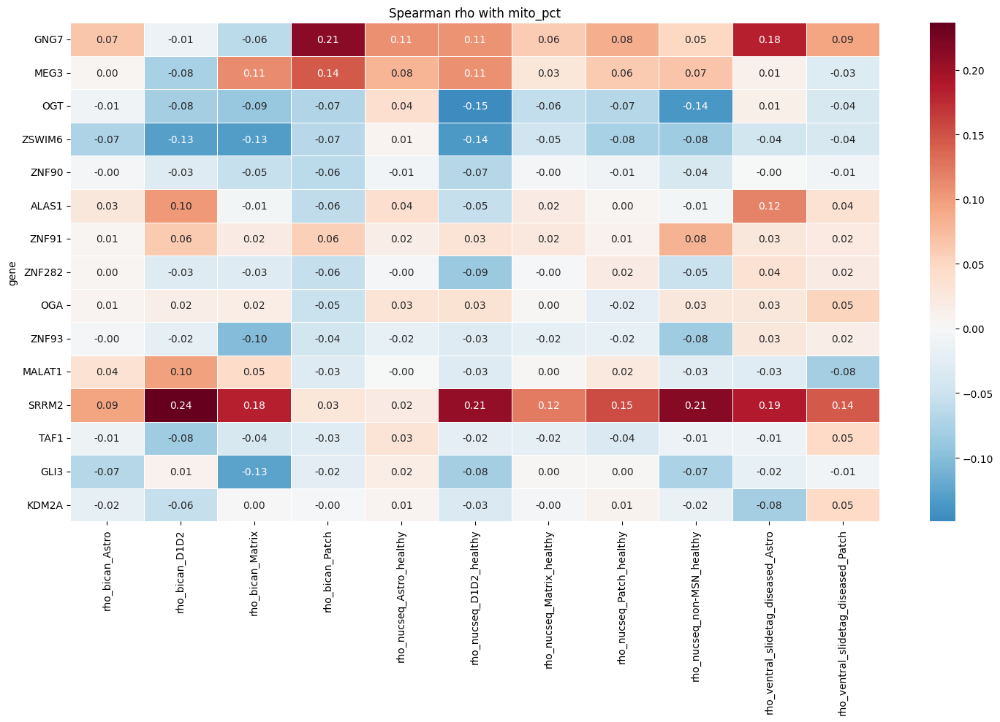

In [ ]:
cols_to_show = [col for col in merged_df.columns if col.startswith("rho")]

subset = merged_df[merged_df.index.isin(["MEG3", "GNG7", "OGT", "GLI3", "ZNF91", "ZNF93", "ZNF90", "ZNF282", "TAF1", "OGA", "MALAT1", "SRRM2", "corr_age", "KDM2A", "ZSWIM6", "ALAS1", "ROBFOX1"])][cols_to_show]#.plot(kind="scatter", figsize=(10, 5))
subset = subset.sort_index(axis=1)
display(subset)

import seaborn as sns
fig, ax = plt.subplots(figsize=(15, 10))
sns.heatmap(subset, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, ax=ax)
ax.set_title("Spearman rho with mito_pct")
plt.tight_layout()
plt.show()

# PCs on healthy Patches

In [ ]:
from utils import nebula_with_factors as nbf

CONTRAST_BASELINE = "eMSN_D1D2" # Patch, D1D2
saving_folder_pca = f"/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic/pca_results_{CONTRAST_BASELINE}"
os.makedirs(saving_folder_pca, exist_ok=True)

In [ ]:
# Read strio-bican
if CONTRAST_BASELINE == "Patch":
    d1_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STRd_D1_Striosome_MSN_4_zones.h5ad")
    d2_strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STRd_D2_Striosome_MSN_4_zones.h5ad")
    strio_bican = sc.concat([d1_strio_bican, d2_strio_bican], axis=0)
elif CONTRAST_BASELINE == "D1D2":
    strio_bican = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/STR_zonation_references_h5ad/STR_D1D2_Hybrid_MSN_4_zones.h5ad")
strio_bican

AnnData object with n_obs × n_vars = 578 × 37905
    obs: 'orig.ident', 'nCount_originalexp', 'nFeature_originalexp', 'PREFIX', 'CELL_BARCODE', 'NUM_GENIC_READS', 'NUM_TRANSCRIPTS', 'NUM_GENES', 'num_retained_transcripts', 'pct_coding', 'pct_utr', 'pct_intergenic', 'pct_genic', 'pct_intronic', 'pct_mt', 'pct_ribosomal', 'frac_contamination', 'experiment', 'donor_external_id', 'is_primary_data', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'donor_id', 'n_counts', 'nCount_RNA', 'nFeature_RNA', 'x', 'y', 'RNA_snn_res.0.8', 'seurat_clusters', 'library', 'donor', 'x_um2', 'y_um2', 'unique_cell_ID', 'AK_celltype', 'RNA_snn_res.0.2', 'cb', 'clusters', 'num_dbscan', 'logu

In [ ]:
strio_bican.obs["donor_id"].unique()

['PT13935']
Categories (1, object): ['PT13935']

Normalising
HVG
Scaling
PCA on Healthy
Auto-selected 50 PCs (37.5% variance explained)
Done.


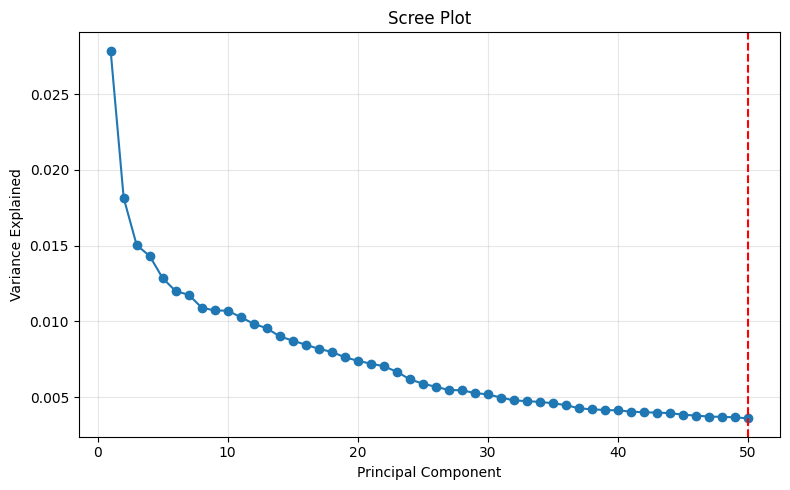

In [ ]:
# ── 1. CALCULATE PCA on healthy data ──────────────────────────────────────────
results_healthy = nbf.calculate_pca(
    adata        = strio_bican.copy(),
    calculate_or_project = "calculate",
    saving_folder = saving_folder_pca,
    variance_threshold = 10   # or pass N_PCS_TO_USE=20 for a fixed number
)

In [ ]:
df_cell_loadings = pd.read_csv(f"{saving_folder_pca}/healthy_pcs.csv")

# add back PCs
strio_bican.obs.drop(columns=[col for col in df_cell_loadings.columns if col.startswith("PC")], inplace=True, errors="ignore")
strio_bican.obs = strio_bican.obs.join(df_cell_loadings.set_index("barcode"))
strio_bican.obs

,orig.ident,nCount_originalexp,nFeature_originalexp,PREFIX,CELL_BARCODE,NUM_GENIC_READS,NUM_TRANSCRIPTS,NUM_GENES,num_retained_transcripts,pct_coding,...,PC_41,PC_42,PC_43,PC_44,PC_45,PC_46,PC_47,PC_48,PC_49,PC_50
s5_s5_CTATCAGAGCTTCGTT_1,2024-10-25,35960,6850,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn1,CTATCAGAGCTTCGTT,62007,35493,6699,35092,0.1999,...,-1.473761,2.748999,0.897362,0.282736,0.974521,-0.519743,-1.214204,-0.761559,0.523454,-0.045379
s5_s5_AGCTTCCGTCTGTGGA_1,2024-10-25,155216,11174,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn1,AGCTTCCGTCTGTGGA,285023,150548,10768,150277,0.1873,...,0.165303,-0.046317,1.557559,0.287113,0.041905,2.901781,-1.405094,0.391270,-0.955501,-0.534953
s5_s5_CCGATTAAGACAATTC_1,2024-10-25,53172,7501,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn1,CCGATTAAGACAATTC,97674,51977,7278,51668,0.1654,...,-1.888584,-0.048235,-4.054758,-4.393327,6.909941,-0.380861,-2.466840,4.523791,-5.615176,-4.092253
s5_s5_CTTCGTTAGCGTTGTA_1,2024-10-25,83854,10111,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn1,CTTCGTTAGCGTTGTA,148105,81768,9774,81508,0.2120,...,2.277922,2.479884,2.087364,1.537913,-3.225910,1.847276,1.595741,-3.432896,3.935195,0.731127
s5_s5_CCTTGCCAGCGTGGTT_1,2024-10-25,117378,10147,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn1,CCTTGCCAGCGTGGTT,211667,114099,9725,113838,0.1394,...,1.918461,-0.044123,-2.013517,0.151618,-2.236784,1.750085,1.150045,1.667335,-3.325113,0.907450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s5_s5_GCTCCGTTCAGGGACA_8,2024-10-25,103573,10209,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn8,GCTCCGTTCAGGGACA,216349,100935,9857,100482,0.2146,...,1.196567,-0.054460,-0.479281,2.712014,0.359748,-0.385517,-0.353718,-2.085063,0.014261,0.517215
s5_s5_ATGGGGTCAGTGCTCA_8,2024-10-25,12499,4236,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn8,ATGGGGTCAGTGCTCA,29406,13309,4416,12204,0.1795,...,-4.147989,0.034631,-0.342427,0.511029,1.817240,-2.867061,-0.916057,0.914762,-2.404842,-1.040786
s5_s5_GGGTCTCCACGCAATT_8,2024-10-25,118540,11043,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn8,GGGTCTCCACGCAATT,252116,115294,10678,114841,0.2551,...,-1.659434,0.566567,0.322635,-0.505929,-0.364198,0.579416,-0.862675,0.278450,-1.579875,-2.915776
s5_s5_ACTTCGTTCCTAAGCA_8,2024-10-25,184876,11119,2024-10-25_s5_Slide-tag_10X-GEMX-5P-GEX_BN_rxn8,ACTTCGTTCCTAAGCA,361762,178449,10541,178122,0.1169,...,0.663622,-0.465154,-2.703822,0.122309,-2.190066,0.904245,-1.144715,0.416578,0.507252,0.567006


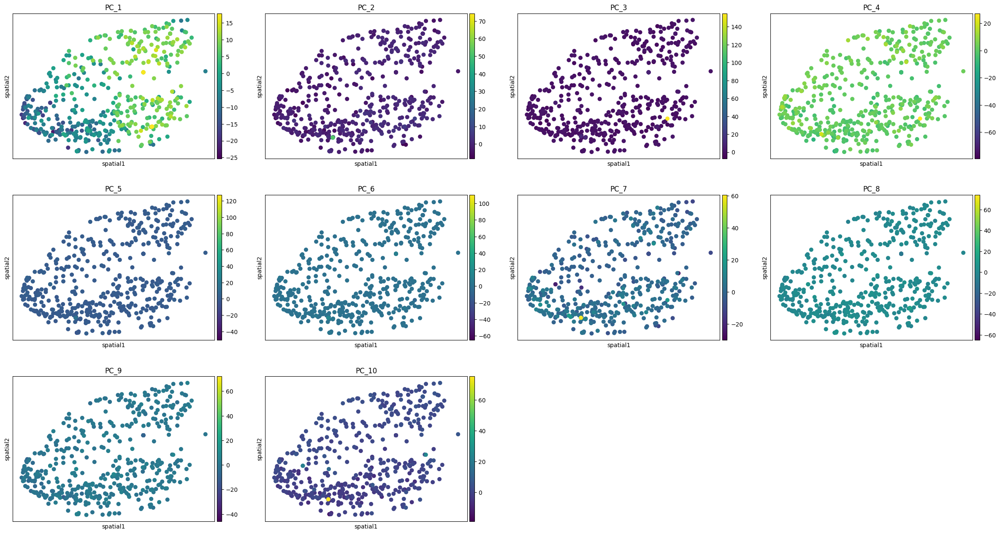

In [ ]:

# mae spatila
strio_bican.obsm["spatial"] = np.array(strio_bican.obs[["x", "y"]])

adata_sample = strio_bican[strio_bican.obs["donor_id"] == "PT13935"].copy()
sc.pl.embedding(adata_sample, basis="spatial", color=[f"PC_{i}" for i in range(1, 11)])

In [ ]:
print(strio_bican.obs[pc_cols].isna().sum())  # how many NaN PCs per component
print(strio_bican.obs.groupby("donor_id")[pc_cols[0]].apply(lambda x: x.notna().sum()))  # per sample


PC_1     0
PC_2     0
PC_3     0
PC_4     0
PC_5     0
PC_6     0
PC_7     0
PC_8     0
PC_9     0
PC_10    0
PC_11    0
PC_12    0
PC_13    0
PC_14    0
PC_15    0
PC_16    0
PC_17    0
PC_18    0
PC_19    0
PC_20    0
PC_21    0
PC_22    0
PC_23    0
PC_24    0
PC_25    0
PC_26    0
PC_27    0
PC_28    0
PC_29    0
PC_30    0
PC_31    0
PC_32    0
PC_33    0
PC_34    0
PC_35    0
PC_36    0
PC_37    0
PC_38    0
PC_39    0
PC_40    0
PC_41    0
PC_42    0
PC_43    0
PC_44    0
PC_45    0
PC_46    0
PC_47    0
PC_48    0
PC_49    0
PC_50    0
dtype: int64
donor_id
PT13935    578
Name: PC_1, dtype: int64


/tmp/ipykernel_414806/3363911021.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(strio_bican.obs.groupby("donor_id")[pc_cols[0]].apply(lambda x: x.notna().sum()))  # per sample


In [ ]:
from scipy import stats
import pandas as pd
import numpy as np

pc_cols = sorted([col for col in strio_bican.obs.columns if col.startswith("PC_")],
                 key=lambda x: int(x.replace("PC_", "")))

pc_scores = strio_bican.obs[pc_cols].values
sample_labels = strio_bican.obs["donor_id"]  # adjust to your column

results = []
for i, pc in enumerate(pc_cols):
    groups = [pc_scores[sample_labels == s, i] for s in sample_labels.unique()]
    groups = [g for g in groups if len(g) > 1]

    stat, pval = stats.kruskal(*groups)

    ss_between = sum(len(g) * (g.mean() - pc_scores[:, i].mean())**2 for g in groups)
    ss_total = ((pc_scores[:, i] - pc_scores[:, i].mean())**2).sum()
    eta2 = ss_between / ss_total

    results.append({"PC": pc, "kruskal_pval": pval, "eta_squared": eta2})

df_pc_batch = pd.DataFrame(results).set_index("PC")[:10]
df_pc_batch

ValueError: Need at least two groups in stats.kruskal()

/tmp/ipykernel_238312/2609725307.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90, fontsize=6)
/tmp/ipykernel_238312/2609725307.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90, fontsize=6)
/tmp/ipykernel_238312/2609725307.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90, fontsize=6)
/tmp/ipykernel_238312/2609725307.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90, fontsize=6)
/tmp/ipykernel_23831

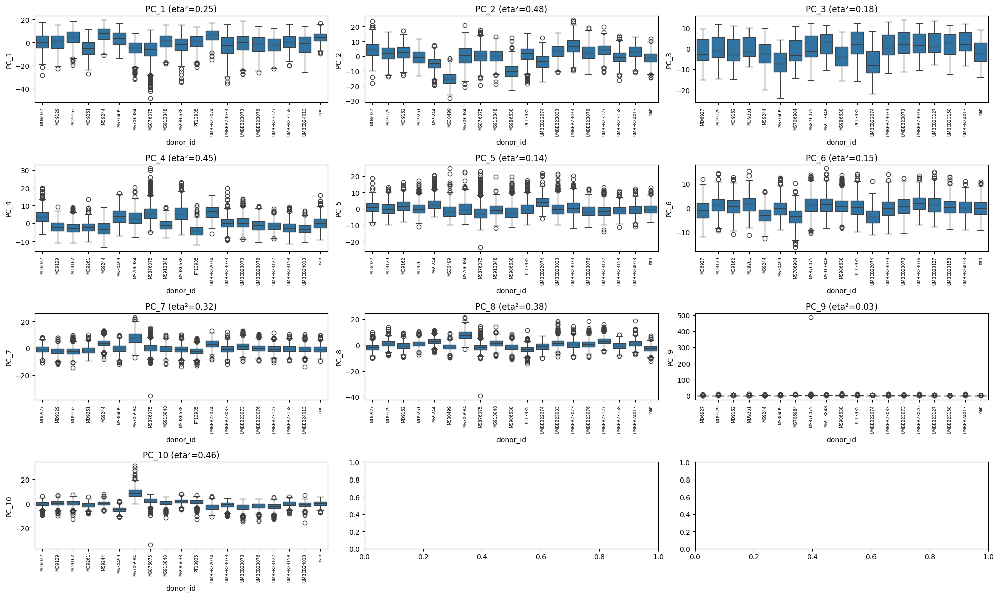

In [ ]:
import seaborn as sns

fig, axes = plt.subplots(4, 3, figsize=(20, 12))
axes = axes.flatten()

for i, pc in enumerate(pc_cols[:10]):
    sns.boxplot(data=strio_bican.obs, x="donor_id", y=pc, ax=axes[i])
    axes[i].set_title(f"{pc} (eta²={df_pc_batch.loc[pc,'eta_squared']:.2f})")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90, fontsize=6)

plt.tight_layout()

In [ ]:
results = []
for i, pc in enumerate(pc_cols[:10]):
    total_var = pc_scores[:, i].var()
    
    # within-sample variance: average variance inside each sample
    within_var = np.mean([
        pc_scores[sample_labels == s, i].var()
        for s in sample_labels.unique()
        if (sample_labels == s).sum() > 1
    ])
    
    between_var = total_var - within_var
    icc_approx = between_var / total_var  # 0=cell-level, 1=sample-level
    
    results.append({"PC": pc, 
                    "within_var": within_var,
                    "between_var": between_var, 
                    "ICC_approx": icc_approx,
                    "eta_squared": df_pc_batch.loc[pc, "eta_squared"]})

df_variance = pd.DataFrame(results).set_index("PC")
df_variance

NameError: name 'df_pc_batch' is not defined

In [ ]:
N_TOP = 10
df_loadings = pd.read_csv(f"{saving_folder_pca}/gene_loadings.csv", index_col=0) #results_healthy["df_loadings"]

for pc in df_loadings.columns[:11]:
    col = df_loadings[pc].sort_values(ascending=False)
    top  = col.head(N_TOP)
    bot  = col.tail(N_TOP)
    print(f"\n{'─'*50}")
    print(f"{pc}")
    print(f"  TOP: {', '.join(f'{g}({v:+.3f})' for g, v in top.items())}")
    print(f"  BOT: {', '.join(f'{g}({v:+.3f})' for g, v in bot.items())}")



──────────────────────────────────────────────────
PC_1
  TOP: CNR1(+0.095), TAC1(+0.080), GRIK1(+0.077), MERTK(+0.075), ZNF385B(+0.074), ESRRG(+0.072), PENK(+0.070), EPHA5(+0.068), NFATC2(+0.068), STAC(+0.066)
  BOT: GRM3(-0.070), SEZ6L(-0.070), CPNE5(-0.070), NDST3(-0.071), PLCXD3(-0.071), UNC5C(-0.073), KCTD8(-0.074), SYNPR(-0.077), ANKRD30BL(-0.078), PDE4D(-0.079)

──────────────────────────────────────────────────
PC_2
  TOP: MALINC1(+0.095), TRIM5(+0.084), ENSG00000279249(+0.084), CFAP299(+0.074), IQCM(+0.074), LINC01344(+0.073), ENSG00000290660(+0.072), ENSG00000257657(+0.068), PAPPA(+0.068), NHSL2(+0.066)
  BOT: RGS20(-0.034), IQGAP1(-0.034), LINC02137(-0.035), HS6ST2(-0.035), ZNF608(-0.036), MEF2C(-0.036), BCL2(-0.037), DCC(-0.037), PCDH11Y(-0.041), ENSG00000253693(-0.042)

──────────────────────────────────────────────────
PC_3
  TOP: ENSG00000243491(+0.142), LINC02273(+0.142), ENSG00000233029(+0.142), IL1RN(+0.140), ENSG00000261070(+0.139), KRTAP10-3(+0.139), ENSG0000026088

In [ ]:
# deifne which a good PCs to use
PC = [
    "PC_1",  # striatal markers + gradient
    "PC_2",  # d1 d2 + some gradient
    "PC_3", # d1 d2
    #"PC_4",  # mito
    "PC_5",
    "PC_6",
    "PC_7",
    #"PC_8", # ribo
    #"PC_9", # ICC+ unknown genes
    #"PC_10" sex
]

In [ ]:
# Unpack what you need for projection
df_stats    = pd.read_csv(f"{saving_folder_pca}/healthy_stats.csv", index_col=0)  # results_healthy["df_stats"]
df_loadings = pd.read_csv(f"{saving_folder_pca}/gene_loadings.csv", index_col=0) #results_healthy["df_loadings"]
df_cell_loadings = pd.read_csv(f"{saving_folder_pca}/healthy_pcs.csv")
df_cell_loadings

,barcode,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,...,PC_41,PC_42,PC_43,PC_44,PC_45,PC_46,PC_47,PC_48,PC_49,PC_50
0,s5_s5_AGCTGAACACAGTTCG_1,-11.597599,1.377758,-2.761356,-2.915693,2.387387,2.110057,-3.662484,-3.968081,-0.022932,...,1.569755,-2.000602,0.661348,1.367320,1.436204,-2.265727,3.632579,-1.421720,-1.486269,0.766374
1,s5_s5_ACCCAAATCACTCTGT_1,-3.408280,0.649480,-1.505948,-7.642397,-5.810849,2.098586,0.986672,-3.597234,-0.060964,...,-0.324553,-1.102800,-0.128018,-1.435937,1.767337,-1.272900,1.342791,-1.429728,-2.432142,1.748096
2,s5_s5_GGAGAGGAGAGTATAG_1,1.236850,10.042952,-4.226388,-1.519150,-0.894328,5.936881,-1.495484,-6.419001,0.020182,...,0.150993,0.521510,-1.049314,0.971044,-0.352874,2.288692,-2.808870,0.537649,4.501703,-1.489010
3,s5_s5_GCAACCCCACCAAGCC_1,-1.620830,-3.166266,0.114861,-9.294931,-6.431955,0.646923,-1.953519,-3.854411,0.020303,...,0.044945,-1.570136,1.581127,0.813491,0.850864,0.041649,0.573663,0.891703,0.126990,0.601444
4,s5_s5_CTTGTACTCGGTTAAT_1,1.902146,10.016050,-0.567943,-5.616521,-1.010105,-3.856323,0.452684,-4.091641,1.460031,...,-1.528253,0.717182,0.106676,-0.288365,0.494552,0.513512,-0.436138,-0.706526,1.168981,0.350354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21494,s38_s38_2025-06-04_s38_GEX_CAP_rxn4_CTTCTACAGA...,8.637201,-3.829999,0.382482,8.772290,3.312861,-1.403599,0.149192,-1.762501,-0.191912,...,-0.424679,0.955964,-1.315899,0.650672,-1.833531,1.866699,-1.399469,-0.443762,-0.958310,-0.933175
21495,s38_s38_2025-06-04_s38_GEX_CAP_rxn4_CGTGCCCGTA...,6.715217,-8.816700,-0.445080,9.970563,-1.418635,0.294852,-3.104501,-1.470799,-0.577912,...,0.564482,-0.307699,1.318548,1.406199,0.070996,-0.599926,-0.434008,-0.297314,-1.283428,0.998119
21496,s38_s38_2025-06-04_s38_GEX_CAP_rxn4_CTCCTTACAA...,3.307232,-11.985446,3.307072,5.735767,-5.798567,-0.326151,-4.222750,0.875178,-0.167783,...,0.146498,2.342528,-1.378537,-3.715653,7.643751,4.950582,5.375966,4.484590,-2.852831,-1.054537
21497,s38_s38_2025-06-04_s38_GEX_CAP_rxn4_ACAGAACAGG...,4.013939,-8.790572,4.028608,3.361874,-3.636552,-0.863152,-0.329377,-3.765361,-0.376733,...,1.696818,-0.567520,0.052864,-0.289890,0.691972,0.957476,-0.165398,-1.140636,0.948577,0.211994


In [ ]:
# ── 2. PROJECT onto diseased data ──────────────────────────────────────────────

shared_genes = adata.var_names.intersection(df_loadings.index)
print(f"Loadings genes: {len(df_loadings)}")
print(f"Diseased adata genes: {len(adata.var_names)}")
print(f"Shared genes: {len(shared_genes)}")
assert len(shared_genes) > 0, "No shared genes — check gene ID format (symbols vs ENSEMBL)"

df_loadings_shared = df_loadings.loc[shared_genes]
df_stats_shared    = df_stats.loc[shared_genes]
adata_shared       = adata[:, shared_genes].copy()

# Clear log1p key so calculate_pca doesn't think data is already normalized
if "log1p" in adata_shared.uns:
    del adata_shared.uns["log1p"]

results_diseased = nbf.calculate_pca(
    adata                = adata_shared,
    calculate_or_project = "project",
    saving_folder        = saving_folder_pca,
    df_stats             = df_stats_shared,
    df_loadings          = df_loadings_shared
)

# ── 3. ADD projected PCs back into adata ──────────────────────────────────────
df_pcs = results_diseased["df_pcs"]
pc_cols = [c for c in df_pcs.columns if c.startswith("PC_")]
df_pcs_indexed = df_pcs.set_index("barcode")
adata.obs[pc_cols] = df_pcs_indexed.reindex(adata.obs_names)


Loadings genes: 3000
Diseased adata genes: 17616
Shared genes: 2225
Normalising
Scaling
PCA on Diseased
Done.


... storing 'sample_x_puck' as categorical


Sample: sample_01_puck1


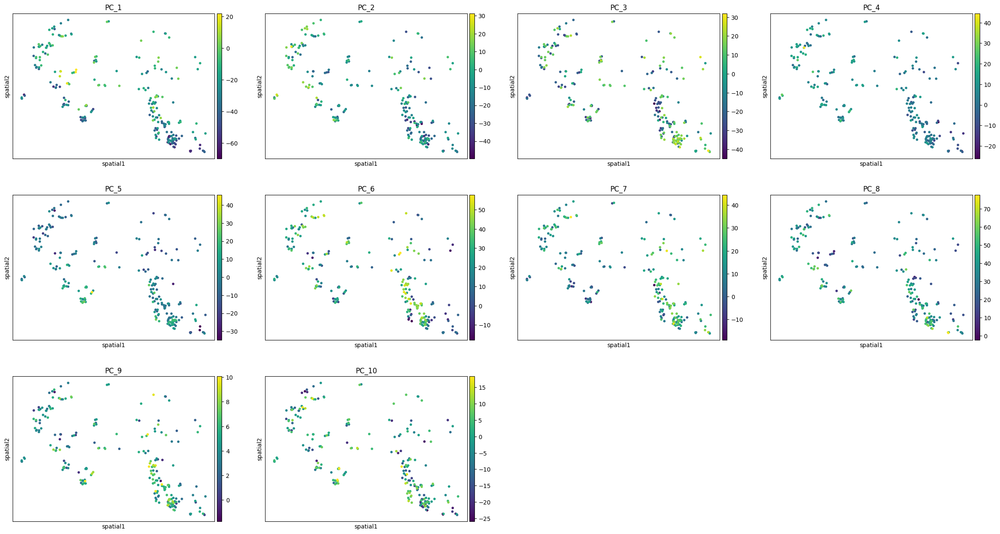

In [ ]:
adata.obs["sample_x_puck"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
for sample in adata.obs["sample_x_puck"].unique():
    print(f"Sample: {sample}")
    adata_sample = adata[adata.obs["sample_x_puck"] == sample].copy()
    sc.pl.embedding(adata_sample, basis="spatial", color=[f"PC_{i}" for i in range(1, 11)], size=70)   

    break 

# Clculte Grd score

In [ ]:
def calc_gradient_score(adata, df_grad, csv_save_path, col_corr="mean_spearman"):

    print("ATTENTION: adata.X must be raw.")
    print("ATTENTION: df_grad must have ONLY gradient genes and gene names as index.")

    # Normalise
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    # Calculate collim genes
    common_genes = adata.var_names.intersection(df_grad.index)

    # Subset to common genes
    import scipy.sparse as sp
    df_grad = df_grad.loc[common_genes]
    X_grad_genes = adata[:, common_genes].X  # (n_cells × n_genes)
    X_grad_genes = X_grad_genes.toarray() if sp.issparse(X_grad_genes) else np.asarray(X_grad_genes)


    # calculate score
    # more dorsal genes --> higher score
    adata.obs["gradient_score"] = - X_grad_genes @ df_grad[col_corr].values

    assert not adata.obs['gradient_score'].isna().any(), "Some cells have no gradient scores!"

    # save df
    df_scores = adata.obs[["gradient_score"]]
    df_scores.to_csv(csv_save_path)


In [ ]:
# define genes for grad

save_csv_path = f"{saving_folder_pca}/gradient_scores.csv"

if not os.path.exists(save_csv_path):

    adata.X = adata.layers["counts"].copy()  # use raw counts for score calculation
    df_grad_significant = df_grad[df_grad["is_gradient_gene"]]
    calc_gradient_score(adata, df_grad_significant, save_csv_path)

else:
    df_scores = pd.read_csv(save_csv_path, index_col=0)
    adata.obs = adata.obs.merge(df_scores, how="left", left_index=True, right_index=True, validate="one_to_one")
    # Check that all cells have scores
    assert not adata.obs['gradient_score'].isna().any(), "Some cells have no gradient scores!"

ATTENTION: adata.X must be raw.
ATTENTION: df_grad must have ONLY gradient genes and gene names as index.


In [ ]:
adata.obs

,x,y,pct_intronic,dbscan_clusters,dbscan_score,has_spatial,sample,Neighborhood_name,Neighborhood_bootstrapping_probability,Neighborhood_aggregate_probability,...,PC_42,PC_43,PC_44,PC_45,PC_46,PC_47,PC_48,PC_49,PC_50,gradient_score
2864,20686.646482,5222.443080,0.709720,1.0,0.917385,True,sample_01,Subpallium GABA,1.0,1.0,...,-0.149262,0.940768,2.734748,5.948108,6.837466,-6.780649,4.591291,4.549609,1.871894,31.016816
6127,50333.988732,2881.022766,0.728080,1.0,0.953548,True,sample_01,Subpallium GABA,1.0,1.0,...,-4.569522,2.103576,-3.943900,4.233537,-1.926449,8.699749,5.556115,-7.737782,4.367839,38.790679
6977,21564.853857,7147.182995,0.701700,1.0,0.922828,True,sample_01,Subpallium GABA,1.0,1.0,...,-6.549940,4.274154,5.090878,0.772808,2.039985,5.555838,11.192725,-7.778730,9.843297,44.456567
7030,53772.264972,-2297.419280,0.756438,1.0,0.871767,True,sample_01,Subpallium GABA,1.0,1.0,...,2.209382,-6.698683,-2.681083,-4.196439,1.573597,5.441604,5.085746,-10.700790,3.924117,34.483713
7068,22080.363438,8719.847585,0.670191,1.0,0.961792,True,sample_01,Subpallium GABA,1.0,1.0,...,1.638252,-8.160821,-3.090697,-2.467714,3.711988,3.792740,5.504083,-8.222976,4.626301,50.168429
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
419814,-19.189803,16.353506,0.838854,1.0,0.976310,True,sample_09,Subpallium GABA,1.0,1.0,...,0.227707,-0.049608,1.528192,3.535914,-0.478692,4.569652,9.986418,-8.730215,6.971220,38.883909
420627,-0.570238,33.043219,0.762856,1.0,0.832179,True,sample_09,Subpallium GABA,1.0,1.0,...,3.181885,-1.178161,-1.841613,0.729506,-5.552819,3.430048,-1.392200,2.411374,5.631098,20.068324
420986,-12.916394,25.497926,0.719072,1.0,0.846857,True,sample_09,Subpallium GABA,1.0,1.0,...,-1.263353,-5.162232,-1.814490,-0.551673,-3.223067,7.325951,2.774986,-5.643009,7.130972,46.817896
421207,1.279727,32.184699,0.726065,1.0,0.975300,True,sample_09,Subpallium GABA,1.0,1.0,...,-2.187111,-3.048510,0.609093,0.025496,-5.431505,5.313301,2.304157,-2.083164,1.470320,30.016957


... storing 'sample_x_puck' as categorical


Sample: sample_01_puck1


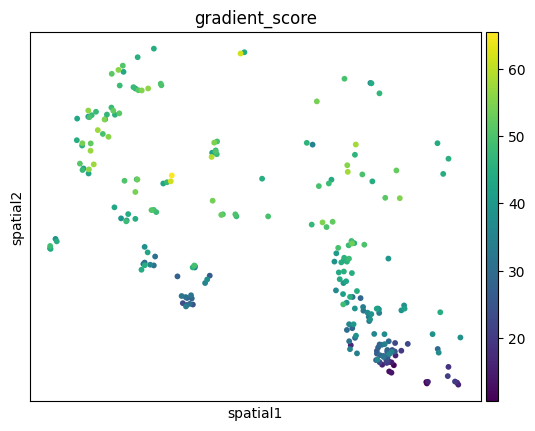

In [ ]:
adata.obs["sample_x_puck"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
for sample in adata.obs["sample_x_puck"].unique():
    print(f"Sample: {sample}")
    adata_sample = adata[adata.obs["sample_x_puck"] == sample].copy()
    sc.pl.embedding(adata_sample, basis="spatial", color="gradient_score", size=70)   

    break 

# Merge all results

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests

BASE = "/home/gdallagl/myworkdir/XDP/data/_old/nebula_generic"

analyses = {
    "Patch_mito_VS_Patch_dead":         (f"{BASE}/mito_patch_VS_patch_dead_region/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_patch", "logFC_ct_for_deg-Mito_cluster_patch", None, None),
    "Patch_mito_VS_Patch_dead_cov":    (f"{BASE}/mito_patch_VS_patch_dead_region_with_mito_cov/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_patch", "logFC_ct_for_deg-Mito_cluster_patch",
                           "p_pct_counts_mt", "logFC_pct_counts_mt"),
    "Patch_mito_VS_Patch_healthy":      (f"{BASE}/mito_patch_VS_patch_healthy_region/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_patch", "logFC_ct_for_deg-Mito_cluster_patch", None, None),
    "Patch_mito_VS_Patch_healthy_cov": (f"{BASE}/mito_patch_VS_patch_healthy_region_with_mito_cov/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_patch", "logFC_ct_for_deg-Mito_cluster_patch",
                           "p_pct_counts_mt", "logFC_pct_counts_mt"),
    "D1D2_mito_VS_D1D2_dead":          (f"{BASE}/mito_D1D2_VS_D1D2_dead_region/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_D1D2", "logFC_ct_for_deg-Mito_cluster_D1D2", None, None),
    "D1D2_mito_VS_D1D2_dead_cov":     (f"{BASE}/mito_D1D2_VS_D1D2_dead_region_with_mito_cov/nebula_results.csv",
                           "p_ct_for_deg-Mito_cluster_D1D2", "logFC_ct_for_deg-Mito_cluster_D1D2",
                           "p_pct_counts_mt", "logFC_pct_counts_mt"),
}

dfs = []
for label, (path, p_col, lfc_col, p_mito, lfc_mito) in analyses.items():
    df = pd.read_csv(path)[["gene", p_col, lfc_col] + ([p_mito, lfc_mito] if p_mito else [])]

    # BH correction independently — exclude p=1 (convergence failures)
    valid = df[p_col] < 1.0
    padj = np.where(valid, multipletests(df.loc[valid, p_col], method="fdr_bh")[1], np.nan)
    # re-align to full index
    padj_series = pd.Series(np.nan, index=df.index)
    padj_series[valid] = multipletests(df.loc[valid, p_col], method="fdr_bh")[1]

    df = df.rename(columns={
        p_col:   f"{label}__p",
        lfc_col: f"{label}__logFC",
        **({p_mito: f"{label}__p_mito", lfc_mito: f"{label}__logFC_mito"} if p_mito else {})
    })
    df[f"{label}__p_adj"] = padj_series.values
    dfs.append(df.set_index("gene"))

df_merged = pd.concat(dfs, axis=1).reset_index()
print(df_merged.shape)
print(df_merged.columns.tolist())
display(df_merged.head(3))


(21270, 25)
['gene', 'Patch_mito_VS_Patch_dead__p', 'Patch_mito_VS_Patch_dead__logFC', 'Patch_mito_VS_Patch_dead__p_adj', 'Patch_mito_VS_Patch_dead_cov__p', 'Patch_mito_VS_Patch_dead_cov__logFC', 'Patch_mito_VS_Patch_dead_cov__p_mito', 'Patch_mito_VS_Patch_dead_cov__logFC_mito', 'Patch_mito_VS_Patch_dead_cov__p_adj', 'Patch_mito_VS_Patch_healthy__p', 'Patch_mito_VS_Patch_healthy__logFC', 'Patch_mito_VS_Patch_healthy__p_adj', 'Patch_mito_VS_Patch_healthy_cov__p', 'Patch_mito_VS_Patch_healthy_cov__logFC', 'Patch_mito_VS_Patch_healthy_cov__p_mito', 'Patch_mito_VS_Patch_healthy_cov__logFC_mito', 'Patch_mito_VS_Patch_healthy_cov__p_adj', 'D1D2_mito_VS_D1D2_dead__p', 'D1D2_mito_VS_D1D2_dead__logFC', 'D1D2_mito_VS_D1D2_dead__p_adj', 'D1D2_mito_VS_D1D2_dead_cov__p', 'D1D2_mito_VS_D1D2_dead_cov__logFC', 'D1D2_mito_VS_D1D2_dead_cov__p_mito', 'D1D2_mito_VS_D1D2_dead_cov__logFC_mito', 'D1D2_mito_VS_D1D2_dead_cov__p_adj']


,gene,Patch_mito_VS_Patch_dead__p,Patch_mito_VS_Patch_dead__logFC,Patch_mito_VS_Patch_dead__p_adj,Patch_mito_VS_Patch_dead_cov__p,Patch_mito_VS_Patch_dead_cov__logFC,Patch_mito_VS_Patch_dead_cov__p_mito,Patch_mito_VS_Patch_dead_cov__logFC_mito,Patch_mito_VS_Patch_dead_cov__p_adj,Patch_mito_VS_Patch_healthy__p,...,Patch_mito_VS_Patch_healthy_cov__logFC_mito,Patch_mito_VS_Patch_healthy_cov__p_adj,D1D2_mito_VS_D1D2_dead__p,D1D2_mito_VS_D1D2_dead__logFC,D1D2_mito_VS_D1D2_dead__p_adj,D1D2_mito_VS_D1D2_dead_cov__p,D1D2_mito_VS_D1D2_dead_cov__logFC,D1D2_mito_VS_D1D2_dead_cov__p_mito,D1D2_mito_VS_D1D2_dead_cov__logFC_mito,D1D2_mito_VS_D1D2_dead_cov__p_adj
0,ENSG00000238009,0.417659,-0.286555,0.700345,0.432153,-0.354440,0.803530,0.043720,0.903129,0.116699,...,0.143536,0.321815,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ENSG00000241860,0.617814,-0.143363,0.830393,0.502888,-0.250594,0.641758,0.071139,0.917594,0.092180,...,0.000080,0.547799,0.650349,-0.474158,0.811354,0.941243,-0.095976,0.657357,-0.209225,0.997274
2,ENSG00000290385,0.457882,-0.246652,0.728762,0.511120,-0.284637,0.890071,0.023306,0.918730,0.529924,...,0.231361,0.815003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_merged[df_merged["gene"].isin(["MEG3", "GNG7", "OGT", "GLI3", "ZNF91", "ZNF93", "ZNF90", "ZNF282", "TAF1", "OGA", "MALAT1", "SRRM2"])]

,gene,Patch_mito_VS_Patch_dead__p,Patch_mito_VS_Patch_dead__logFC,Patch_mito_VS_Patch_dead__p_adj,Patch_mito_VS_Patch_dead_cov__p,Patch_mito_VS_Patch_dead_cov__logFC,Patch_mito_VS_Patch_dead_cov__p_mito,Patch_mito_VS_Patch_dead_cov__logFC_mito,Patch_mito_VS_Patch_dead_cov__p_adj,Patch_mito_VS_Patch_healthy__p,...,Patch_mito_VS_Patch_healthy_cov__logFC_mito,Patch_mito_VS_Patch_healthy_cov__p_adj,D1D2_mito_VS_D1D2_dead__p,D1D2_mito_VS_D1D2_dead__logFC,D1D2_mito_VS_D1D2_dead__p_adj,D1D2_mito_VS_D1D2_dead_cov__p,D1D2_mito_VS_D1D2_dead_cov__logFC,D1D2_mito_VS_D1D2_dead_cov__p_mito,D1D2_mito_VS_D1D2_dead_cov__logFC_mito,D1D2_mito_VS_D1D2_dead_cov__p_adj
6693,GLI3,9.448163e-07,2.100827,1.038707e-04,5.658996e-05,1.826634,4.921830e-03,0.307235,0.020174,1.125007e-11,...,0.330282,3.863332e-06,4.161788e-04,-1.046967,3.389411e-03,9.384358e-02,-0.655315,1.457192e-01,-0.198738,5.529736e-01
7261,ZNF282,7.304322e-01,-0.054765,8.931115e-01,9.333722e-01,-0.017027,7.660779e-01,-0.025363,0.994953,6.901128e-01,...,-0.038199,8.032054e-01,5.506023e-01,-0.203208,7.255483e-01,4.064853e-01,-0.377772,5.370447e-01,0.084641,8.478940e-01
9222,OGA,7.294167e-01,-0.011881,8.925552e-01,6.164297e-01,0.021692,2.046521e-01,-0.021782,0.942119,1.931310e-01,...,-0.007378,7.977214e-01,6.208914e-01,0.037334,7.876031e-01,4.323505e-01,0.082754,5.067554e-01,-0.022467,8.597545e-01
9853,MALAT1,1.065022e-25,-0.161569,1.338124e-22,1.797899e-09,-0.106569,3.458677e-10,-0.032904,0.000002,1.931786e-92,...,-0.035413,2.086265e-30,5.022260e-15,-0.172852,7.141554e-13,3.773283e-05,-0.116359,1.028851e-03,-0.025737,7.225586e-03
12100,MEG3,8.103795e-04,0.070878,1.634699e-02,7.012419e-03,0.066892,7.579401e-01,0.002392,0.334856,5.607440e-115,...,0.008445,9.724400e-63,1.021876e-53,0.519301,2.096597e-50,7.043069e-18,0.358117,4.013873e-10,0.077547,5.057628e-14
12899,SRRM2,1.035583e-02,0.094542,9.018580e-02,3.666299e-01,0.039506,1.971515e-02,0.034635,0.882837,1.438077e-29,...,0.069329,5.581487e-07,4.716790e-23,0.662082,1.693563e-20,2.922514e-08,0.462885,5.531547e-05,0.101079,1.998721e-05
14891,GNG7,7.867589e-18,0.262395,6.590042e-15,1.982903e-06,0.167965,3.821769e-07,0.058056,0.001292,5.911501e-114,...,0.085165,2.689412e-38,6.340922e-29,0.614285,3.502628e-26,2.627260e-06,0.316783,2.113822e-13,0.146425,8.361344e-04
15257,ZNF93,6.096677e-01,0.074108,8.253082e-01,6.494720e-01,0.081863,9.421053e-01,-0.004765,0.949092,8.288502e-01,...,0.072632,8.132473e-01,1.840416e-01,0.668232,3.353470e-01,7.885861e-02,1.275954,2.890564e-01,-0.322190,5.274391e-01
15259,ZNF90,5.395247e-01,-0.280927,7.829585e-01,5.961419e-01,0.318602,1.629904e-01,-0.437515,0.937844,8.733928e-01,...,-0.478308,6.332799e-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15284,ZNF91,9.155737e-05,0.132650,3.499352e-03,6.490308e-01,0.018392,2.475009e-07,0.071285,0.948989,4.338300e-23,...,0.099917,5.635393e-02,1.633859e-16,0.559077,2.970314e-14,7.083540e-03,0.240972,1.013771e-08,0.149561,2.058198e-01


In [ ]:
def show_gene(gene, df_merged):
    row = df_merged[df_merged["gene"] == gene]
    if row.empty:
        print(f"Gene '{gene}' not found")
        return

    row = row.iloc[0]
    analyses = set(c.split("__")[0] for c in df_merged.columns if "__" in c)

    records = []
    for an in sorted(analyses):
        r = {"analysis": an}
        for metric in ["logFC", "p", "p_adj", "logFC_mito", "p_mito"]:
            col = f"{an}__{metric}"
            r[metric] = f"{row[col]:.3g}" if col in df_merged.columns and pd.notna(row[col]) else "—"
        records.append(r)

    display(pd.DataFrame(records).set_index("analysis"))

show_gene("PENK", df_merged)


,logFC,p,p_adj,logFC_mito,p_mito
analysis,,,,,
D1D2_mito_VS_D1D2_dead,-1.57,5.26e-09,2.47e-07,—,—
D1D2_mito_VS_D1D2_dead_cov,-0.225,0.536,0.907,-0.629,1.8e-05
Patch_mito_VS_Patch_dead,-0.782,9.98e-12,3.9e-09,—,—
Patch_mito_VS_Patch_dead_cov,-0.37,0.0136,0.421,-0.242,5.03e-05
Patch_mito_VS_Patch_healthy,-0.912,5.07e-19,3.32e-17,—,—
Patch_mito_VS_Patch_healthy_cov,-0.519,0.000336,0.00685,-0.191,0.000202


# ---

In [ ]:
adata_sample

AnnData object with n_obs × n_vars = 29919 × 37464
    obs: 'x', 'y', 'pct_intronic', 'dbscan_clusters', 'dbscan_score', 'has_spatial', 'sample', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'library_id', 'donor_number', 'donor_id', 'condition', 'sex', 'age_at_onset', 'age_at_death', 'bcl', 'library', 'Sorted', 'mapping_coupling_for_zoning', 'zone', 'zone_probability', 'mapping_coupling_for_zoning_4_zones', 'zone_4', 'zone_4_probability', 'leiden_0.1_all_ce

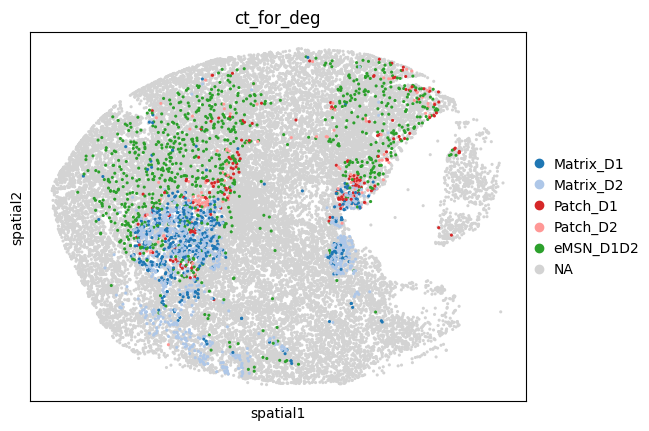

In [ ]:
# adata.obs["sample_x_puck"] = adata.obs["sample"].astype(str) + "_" + adata.obs["puck"].astype(str)  
# adata_sample = adata[adata.obs["sample_x_puck"] == "sample_01_puck1"].to_memory().copy()

from collections import defaultdict

palette = defaultdict(lambda: "lightgrey", {
    "Matrix_D1":  "#1f77b4",
    "Matrix_D2":  "#aec7e8",
    "Patch_D1":   "#d62728",
    "Patch_D2":   "#ff9896",
    "eMSN_D1D2":  "#2ca02c",
})

sc.pl.embedding(
    adata_sample,
    basis="spatial",
    color="ct_for_deg",
    groups=["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "eMSN_D1D2"],
    palette=palette,
    size=20
)